# Taller de IA · El problema del viajante (TSP)
## A* con MST · Hill Climbing vs. Simulated Annealing · Algoritmo genético · RBFS

**Versión del estudiante — enunciado y pseudocódigo, sin implementaciones.**

**Duración propuesta:** dos sesiones. **Modalidad:** parejas. **Entrega:** este mismo cuaderno, completado con las implementaciones propias, pruebas, figuras, resultados y análisis. El docente puede ajustar plazo y modalidad.

**Pregunta central:** ¿qué se gana y qué se pierde al cambiar garantía de optimalidad por rapidez, diversidad o menor consumo de memoria?

Instancias obligatorias: **att48, berlin52, brazil58 y gr48**. Se trabajará también con subinstancias pequeñas para verificar los métodos exactos. Instancias de ampliación: gr17, burma14 y eil51.

Este cuaderno contiene únicamente celdas Markdown. Los bloques etiquetados como `text` son pseudocódigo: no son Python ni MATLAB y no se ejecutan. El estudiante agregará sus propias celdas de código donde se indique.


## Cómo leer este cuaderno (guion de mi exposición)

Este cuaderno es el enunciado del taller **completado**: conservé todos los enunciados y pseudocódigos tal como los entregó el docente (primer commit del repositorio, `e10a4f7`) y, debajo de cada sección, agregué mi código, mis pruebas, mis mediciones y mis apuntes. Cada afirmación remite a una celda de código, una tabla, una figura o una prueba de este mismo cuaderno.

**La pregunta central del taller** es *¿qué se gana y qué se pierde al cambiar garantía de optimalidad por rapidez, diversidad o menor consumo de memoria?* Mi respuesta se construye en cuatro pasos:

| Paso | Qué demuestro | Dónde |
|---|---|---|
| 1. Datos y modelo | Los pesos son los oficiales y el costo incluye el cierre del ciclo | §3, §4 |
| 2. Exactos (A\* y RBFS con MST) | Garantizan el óptimo; A\* gasta memoria, RBFS gasta recomputación | §5–§8, §13, §14 escala A |
| 3. Locales (HC, SA, GA) | Sin garantía, pero dan buenas rutas con un presupuesto fijo | §9–§12, §14 escala B |
| 4. Comparación | Con el mismo presupuesto, repeticiones y gap, ¿qué conviene cuándo? | §15–§16 |

**Cómo está construido (reproducibilidad).** El código vive en el paquete `tsp/` con pruebas en `tests/` (`pytest`); la herramienta `tools/construir_cuaderno.py` inserta ese mismo código en las celdas, por eso el cuaderno se ejecuta de arriba abajo sin importar nada del repositorio salvo los datos locales de `datos/`. Los resultados se guardan como registros (`resultados/*.csv`) y **todas** las tablas y figuras se generan a partir de ellos; no hay cifras escritas a mano como si fueran mediciones. La bitácora (`BITACORA.md`) recoge cada decisión de diseño y cada error que cometí y corregí.

**Reglas que me impuse y que se verifican en el cuaderno**

1. Los cinco algoritmos están escritos desde cero; solo uso `tsplib95` para leer datos y pesos oficiales.
2. Una sola función de costo (`tour_cost`) para todos; el delta de 2-opt se valida contra ella.
3. Un gap negativo detiene la ejecución y obliga a auditar (`AuditError`).
4. La calibración de parámetros se hace en instancias **distintas** de las de evaluación (gr17, burma14 y eil51) y los parámetros se congelan antes de la evaluación principal.
5. «Interrumpido» no es «fracaso» ni «óptimo»; solo A\* y RBFS terminados sin interrupción llevan certificado.

## 1. Punto de partida y lectura crítica

La página [TSP Solve](https://sites.google.com/view/tsp-solve/homepage) presenta A*, Hill Climbing y RBFS en MATLAB. Este taller amplía el alcance con recocido simulado y un algoritmo genético. Los procedimientos que siguen son una formulación didáctica propia; no constituyen una traducción del código MATLAB.

Antes de programar, revise estas dos diferencias:

1. Intercambiar las posiciones de dos ciudades es **swap**. El movimiento **2-opt** elimina dos aristas y reconecta el ciclo invirtiendo un segmento. No son movimientos equivalentes en general.
2. En TSP, llegar a la misma ciudad por rutas parciales diferentes no significa llegar al mismo estado: importa también el conjunto de ciudades pendientes. Las reglas de descarte deben respetar esta información.

La página reporta resultados no óptimos para algunas ejecuciones de su variante denominada A* de grafo. Eso motiva una auditoría de estados y reglas de descarte; no demuestra que A* correctamente formulado pierda su garantía de optimalidad.

**Actividad de lectura:** identifique qué código del sitio realiza swap y explique qué debería cambiar para implementar 2-opt. Examine qué información necesita la clave de un estado de A*. No use los tiempos publicados como objetivos de rendimiento de su implementación.


### 1.A Lectura crítica de TSP Solve (actividad de la sección 1)

Leí las cuatro páginas del sitio (inicio, A\*, Hill Climbing y RBFS, consultadas el 15 de octubre de 2026) con una pregunta en mente: **¿qué hace exactamente el código, y qué dice el texto que hace?** Estas son las diferencias que encontré; las separo en las dos que pide el enunciado y otras que aparecieron.

**1. ¿Qué código realiza swap, y qué cambiaría para implementar 2-opt?**

El texto de la página de Hill Climbing dice que un vecino se obtiene «cambiando las posiciones de dos nodos (o borrando dos aristas y añadiendo dos)» y lo llama «vecinos 2-opt». Esas son **dos operaciones distintas** que la página trata como una sola. El código MATLAB hace la primera:

```matlab
tempNode = newTour(p1);
newTour(p1) = curState.node(p2);
newTour(p2) = tempNode;
```

Eso es un **swap**: intercambia dos ciudades y deja el resto en su sitio. Un swap de las posiciones `p1` y `p2` toca hasta **4 aristas** (las dos vecinas de cada ciudad) y, si las posiciones son adyacentes, solo 3. El 2-opt elimina exactamente **2 aristas** y reconecta invirtiendo el tramo intermedio. Para pasar de uno a otro habría que sustituir esas tres líneas por la inversión de un segmento, `newTour(p1+1:p2) = flip(newTour(p1+1:p2))`, y además cambiar el rango de los índices: el código recorre `p1 = 1:n-1` y `p2 = p1+1:n`, es decir **n(n−1)/2 = 1128** candidatos para n = 48, mientras que los pares válidos de 2-opt son **n(n−3)/2 = 1080** (se excluyen las aristas adyacentes). Una consecuencia práctica: con 2-opt el cambio de costo se calcula con solo 4 pesos (`Δ = d(a,c)+d(b,d)−d(a,b)−d(c,d)`), mientras que el código de la página vuelve a calcular el costo completo de cada candidato.

**2. ¿Qué información necesita la clave de un estado de A\*?**

En la versión de grafo la página comprueba los repetidos comparando solo el **nombre de la ciudad**: `ismember(nodelist(i).name, {closed.name})`. Es decir, su clave de estado es *únicamente la última ciudad*. Eso es incorrecto en el TSP porque dos rutas parciales pueden terminar en la misma ciudad habiendo visitado **conjuntos distintos**: sus futuros son diferentes, y al descartar una de ellas podría perderse la ruta óptima. La clave correcta es `(última ciudad, conjunto de pendientes, ciclo cerrado)`, con el mismo origen fijo. En mi implementación (etapa 6) esa afirmación no queda como opinión: construyo un contraejemplo concreto y lo verifico con una prueba.

**Otras diferencias entre lo que la página dice y lo que hace**

| Hallazgo | Qué dice la página | Qué hace el código | Por qué importa |
|---|---|---|---|
| Ruta inicial de HC | «comienza con una solución aleatoria» | usa el orden de los nodos del grafo (`table2cell(G.Nodes)`) | el resultado reportado es de una sola ruta inicial fija, no de una aleatoria; no se puede hablar de variabilidad |
| Hill Climbing acepta mejoras | «mejor vecino» | actualiza `curState` en cuanto encuentra una mejora dentro del barrido (primera mejora, no mejor mejora) | es otra variante; compararla con «mejor mejora» exige decirlo |
| Complejidad de HC | tiempo `O(∞)`, espacio `O(b)` | cada candidato recalcula el costo completo en O(n); un barrido cuesta O(n³) | `O(∞)` no es una cota; la memoria real es O(n), no O(b) |
| Término `- depth` | no aparece en el pseudocódigo | `node.cost = h + g - depth` en el árbol y en RBFS | el valor de `f` deja de ser el largo de la ruta; el costo reportado es menor que el real en aproximadamente n−1 |
| «Pathmax» en RBFS | `suc.cost ← max(suc.g+suc.h, currentNode.cost)` | se ejecuta sobre una copia (`suc = nodelist(i)`) que nunca se guarda | el `max` no tiene efecto; justo ese `max` es lo que mantiene los valores respaldados de `f` monótonos |
| A\* de grafo | «óptimo o casi óptimo» | solo 8 de las 48 ciudades de inicio dan 10628; las otras dan entre 10648 y 10795 | un A\* correctamente formulado devuelve el mismo costo desde cualquier origen |

**Qué NO afirmo.** Los resultados no óptimos de esa página **no demuestran** que A\* pierda la optimalidad: demuestran que *esa implementación* (clave de estado incompleta, `- depth`) no es un A\* correctamente formulado. Y no uso sus tiempos (166 s, 161 s, horas…) como objetivos de rendimiento: dependen del lenguaje, del hardware y de la implementación.

**Cómo lo uso.** Estas observaciones definen cuatro pruebas de mi propio trabajo: (i) el contraejemplo de la clave de estado (etapa 6); (ii) la invarianza del costo óptimo al cambiar el origen (etapa 6); (iii) 2-opt frente a swap con un ejemplo concreto (etapa 8); (iv) la traza de RBFS que muestra por qué se necesita el `max` (etapa 7).

## 2. Objetivos y reglas del trabajo

Al finalizar, deberá poder:

- Modelar el TSP como búsqueda de rutas parciales y como optimización de permutaciones completas.
- Construir y justificar una heurística basada en árbol de expansión mínima (MST).
- Implementar A*, RBFS, Hill Climbing, Simulated Annealing y un algoritmo genético con operadores válidos para permutaciones.
- Diseñar experimentos reproducibles y distinguir solución válida, mejor solución observada y optimalidad demostrada.
- Interpretar convergencia, brecha al óptimo, memoria y costo computacional.

**Implementación:** escriba los cinco algoritmos desde cero. Puede usar herramientas para arreglos, gráficas, tablas, lectura de archivos y medición. Se permite `tsplib95` para cargar datos y obtener pesos oficiales. Implemente el MST mediante Prim o Kruskal; no delegue las búsquedas ni la optimización a un solver, SimpleAI, DEAP o una biblioteca equivalente en la comparación principal.

Los nombres sugeridos de componentes e identificadores están en inglés; las explicaciones y conclusiones se entregan en español. Toda ayuda externa deberá declararse. Cada integrante debe poder explicar y modificar su implementación durante la sustentación.


## 3. Banco de problemas TSPLIB

| Instancia | Ciudades | Tipo de pesos | Óptimo oficial del ciclo | Papel en el taller |
|---|---:|---|---:|---|
| att48 | 48 | ATT: distancia pseudoeuclidiana | 10628 | Detectar errores de distancia y redondeo |
| berlin52 | 52 | EUC_2D: distancia euclidiana entera | 7542 | Relacionar rutas con una representación geométrica |
| brazil58 | 58 | EXPLICIT: pesos de una matriz | 25395 | Separar optimización de coordenadas |
| gr48 | 48 | EXPLICIT: pesos de una matriz | 5046 | Comparar dos problemas del mismo tamaño y estructura diferente |
| gr17 · ampliación | 17 | EXPLICIT | 2085 | Exploración exacta intermedia, bajo límites |
| burma14 · ampliación | 14 | GEO | 3323 | Estudiar un tipo de distancia adicional |
| eil51 · ampliación | 51 | EUC_2D | 426 | Generalización de métodos aproximados |

Fuentes: [documentación TSPLIB](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [óptimos oficiales](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [repositorio oficial de archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html).

Los valores son unidades del problema, no necesariamente kilómetros. Para las cuatro instancias obligatorias use los archivos TSP, no archivos homónimos de VRP. Descomprima los `.tsp.gz` antes de leerlos. El cuaderno proporciona enlaces; no contiene los archivos de datos.

**Descargas:** [att48](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/att48.tsp.gz) · [berlin52](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/berlin52.tsp.gz) · [brazil58](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/brazil58.tsp.gz) · [gr48](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/gr48.tsp.gz).


### 3.1. Preparación y auditoría de los datos

Lea `NAME`, `TYPE`, `DIMENSION`, `EDGE_WEIGHT_TYPE` y, cuando exista, `EDGE_WEIGHT_FORMAT`. Reconstruya una matriz simétrica de costos `D`. No presuponga que la numeración de nodos coincide con las posiciones de una lista: conserve una correspondencia explícita entre identificadores y posiciones.

Se recomienda obtener cada peso mediante la interfaz de `tsplib95`, que distingue pesos explícitos y funciones de distancia. La biblioteca no incluye las instancias. Consulte su [documentación de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html).

```text
PROCEDURE LoadInstance(file)
    problem ← leer archivo TSPLIB descomprimido
    nodeIds ← lista ordenada de identificadores reales
    PARA cada par de posiciones i, j
        D[i,j] ← peso oficial entre nodeIds[i] y nodeIds[j]
    verificar dimensión, simetría, diagonal cero y pesos no negativos
    devolver metadatos, nodeIds, D y datos de dibujo disponibles
```

**Entregue:** una ficha por instancia, tres pesos calculados o consultados manualmente y una comprobación automática independiente del costo de una ruta. Si usa un archivo `.opt.tour` oficial disponible, verifique su validez y costo; no lo use como población inicial ni como ruta inicial.

En problemas EXPLICIT, los datos de dibujo, si existen, sirven para visualizar, no para recalcular pesos. Si no hay coordenadas, use una matriz de calor y un dibujo circular de la ruta, etiquetado como disposición esquemática.


In [1]:
!pip install -q tsplib95


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 3.2. Dos reglas de distancia que deben comprender

Para berlin52 (EUC_2D), con $r=\sqrt{(x_i-x_j)^2+(y_i-y_j)^2}$:

$$d(i,j)=\lfloor r+0.5\rfloor.$$

Para att48 (ATT):

$$r=\sqrt{\frac{(x_i-x_j)^2+(y_i-y_j)^2}{10}},\qquad t=\lfloor r+0.5\rfloor,$$

$$d(i,j)=\begin{cases}t+1&\text{si }t<r,\\t&\text{en otro caso.}\end{cases}$$

Para brazil58 y gr48 se utilizan los pesos del archivo, respetando su formato matricial. No reemplace esos pesos por distancias euclidianas. Estas reglas corresponden a la especificación TSPLIB; no aplique el redondeo de empates de un lenguaje sin comprobarlo.

**Ejercicio:** calcule un peso ATT y uno EUC_2D a mano y compárelos con el lector. Explique por qué una ruta aparentemente mejor que el óptimo oficial obliga primero a revisar distancias, cierre del ciclo y validez. La [FAQ oficial](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html) documenta errores frecuentes de este tipo.


In [2]:
# ===== tsp/datos.py =====
# -*- coding: utf-8 -*-
"""Carga de instancias TSPLIB y subinstancias inducidas (seccion 3 del taller).

Decision de representacion: las ciudades se manejan por POSICION 0..n-1; la
correspondencia con los identificadores reales del archivo vive en `node_ids`.
Nunca se supone que el identificador i este en la posicion i-1.
"""
import os

import tsplib95

# Optimos oficiales del CICLO (TSP-BEST.html de TSPLIB95).
OPTIMA = {"att48": 10628, "berlin52": 7542, "brazil58": 25395, "gr48": 5046,
          "gr17": 2085, "burma14": 3323, "eil51": 426}


class TSPInstance:
    """Instancia simetrica con matriz de pesos inmutable.

    Atributos:
        name        nombre (las subinstancias llevan sufijo [k=..])
        node_ids    identificadores reales, ordenados; posicion i <-> node_ids[i]
        D           tuple de tuples de int: D[i][j] = peso oficial entre posiciones
        coords      tuple de (x, y) por posicion, o None si el archivo no trae
                    datos de dibujo (solo para VISUALIZAR, nunca para pesos)
        weight_type valor de EDGE_WEIGHT_TYPE (EUC_2D, ATT, GEO, EXPLICIT)
        optimum     optimo oficial del ciclo, o None (subinstancias: None)
        parent      nombre de la instancia completa si es subinstancia
    """

    def __init__(self, name, node_ids, D, coords, weight_type, optimum, parent=None):
        self.name = name
        self.node_ids = tuple(node_ids)
        self.D = tuple(tuple(fila) for fila in D)
        self.coords = None if coords is None else tuple(coords)
        self.weight_type = weight_type
        self.optimum = optimum
        self.parent = parent
        self.n = len(self.node_ids)

    def __repr__(self):
        return "TSPInstance({0}, n={1}, {2})".format(self.name, self.n, self.weight_type)

    def subinstance(self, k):
        """Primeros k identificadores ORDENADOS, con los pesos originales (induce
        el subproblema; no se recalculan distancias). El optimo oficial no aplica."""
        if not 2 <= k <= self.n:
            raise ValueError("k fuera de rango")
        pos = list(range(k))
        D = [[self.D[i][j] for j in pos] for i in pos]
        coords = None if self.coords is None else [self.coords[i] for i in pos]
        return TSPInstance("{0}[k={1}]".format(self.name, k), self.node_ids[:k], D,
                           coords, self.weight_type, None, parent=self.name)


def load_instance(path):
    """Lee un .tsp con tsplib95 y reconstruye la matriz D (verificada)."""
    problem = tsplib95.load(path)
    weight_keys = sorted(problem.get_nodes())     # claves que acepta get_weight
    n = len(weight_keys)
    if problem.dimension != n:
        raise ValueError("DIMENSION no coincide con los nodos leidos")
    # Para EXPLICIT sin coordenadas tsplib95 numera los nodos 0..n-1, pero los
    # archivos (.opt.tour) y la convencion TSPLIB los numeran 1..n. El
    # identificador REAL es posicion+1; la clave de get_weight es solo interna.
    node_ids = [k + 1 for k in weight_keys] if weight_keys[0] == 0 else list(weight_keys)
    D = [[0 if a == b else problem.get_weight(a, b) for b in weight_keys]
         for a in weight_keys]
    _audit_matrix(D)
    coords = _drawing_coords(problem, weight_keys)
    name = problem.name
    return TSPInstance(name, node_ids, D, coords, problem.edge_weight_type,
                       OPTIMA.get(name))


def load_by_name(name, folder="datos"):
    return load_instance(os.path.join(folder, name + ".tsp"))


def _audit_matrix(D):
    n = len(D)
    for i in range(n):
        if len(D[i]) != n:
            raise ValueError("matriz no cuadrada")
        if D[i][i] != 0:
            raise ValueError("diagonal no nula en {0}".format(i))
        for j in range(n):
            if D[i][j] != D[j][i]:
                raise ValueError("matriz asimetrica en ({0},{1})".format(i, j))
            if D[i][j] < 0:
                raise ValueError("peso negativo en ({0},{1})".format(i, j))


def _drawing_coords(problem, node_ids):
    """Coordenadas SOLO para dibujar. Si no existen, devuelve None."""
    for fuente in (getattr(problem, "node_coords", None),
                   getattr(problem, "display_data", None)):
        if fuente and all(i in fuente for i in node_ids):
            return [tuple(fuente[i][:2]) for i in node_ids]
    return None


def read_opt_tour(path, instance):
    """Lee un .opt.tour oficial y lo devuelve como ruta de POSICIONES, empezando
    en la posicion 0. Sirve para verificar costos, nunca como ruta inicial."""
    t = tsplib95.load(path)
    ids = list(t.tours[0])
    pos = {nid: i for i, nid in enumerate(instance.node_ids)}
    route = [pos[i] for i in ids]
    k = route.index(0)
    return route[k:] + route[:k]


In [3]:
# ===== Fichas de las siete instancias (lectura + auditoría automática de la matriz) =====
import math
import time
from IPython.display import Markdown, display

INSTANCE_NAMES = ["att48", "berlin52", "brazil58", "gr48", "gr17", "burma14", "eil51"]
MANDATORY = ["att48", "berlin52", "brazil58", "gr48"]
CALIBRATION = ["gr17", "burma14", "eil51"]
INSTANCES, LOAD_SECONDS = {}, {}
for nombre in INSTANCE_NAMES:                  # falla si la auditoría falla
    _t0 = time.perf_counter()
    INSTANCES[nombre] = load_by_name(nombre)
    LOAD_SECONDS[nombre] = time.perf_counter() - _t0   # precarga: se mide aparte de los solvers (14.1)
print("Tiempo de precarga de datos (fuera de toda región cronometrada de los algoritmos): "
      + ", ".join("{0} {1:.3f} s".format(k, v) for k, v in LOAD_SECONDS.items()))

filas = ["| Instancia | n | Tipo de pesos | Coordenadas | Óptimo oficial | Peso mín / máx | D(1,2), D(1,3), D(2,3) |",
         "|---|---:|---|---|---:|---|---|"]
for nombre in INSTANCE_NAMES:
    inst = INSTANCES[nombre]
    pesos = sorted({inst.D[a][b] for a in range(inst.n) for b in range(a + 1, inst.n)})
    filas.append("| {0} | {1} | {2} | {3} | {4} | {5} / {6} | {7}, {8}, {9} |".format(
        nombre, inst.n, inst.weight_type, "sí" if inst.coords else "no", inst.optimum,
        pesos[0], pesos[-1], inst.D[0][1], inst.D[0][2], inst.D[1][2]))
display(Markdown("\n".join(filas)))


Tiempo de precarga de datos (fuera de toda región cronometrada de los algoritmos): att48 0.005 s, berlin52 0.005 s, brazil58 0.005 s, gr48 0.003 s, gr17 0.001 s, burma14 0.001 s, eil51 0.005 s


| Instancia | n | Tipo de pesos | Coordenadas | Óptimo oficial | Peso mín / máx | D(1,2), D(1,3), D(2,3) |
|---|---:|---|---|---:|---|---|
| att48 | 48 | ATT | sí | 10628 | 42 / 2662 | 1495, 381, 1135 |
| berlin52 | 52 | EUC_2D | sí | 7542 | 15 / 1716 | 666, 281, 649 |
| brazil58 | 58 | EXPLICIT | no | 25395 | 72 / 8700 | 2635, 2713, 314 |
| gr48 | 48 | EXPLICIT | no | 5046 | 21 / 1083 | 593, 409, 258 |
| gr17 | 17 | EXPLICIT | no | 2085 | 27 / 745 | 633, 257, 390 |
| burma14 | 14 | GEO | sí | 3323 | 19 / 1261 | 153, 510, 422 |
| eil51 | 51 | EUC_2D | sí | 426 | 2 / 86 | 12, 19, 15 |

### 3.A Lectura de datos, fichas y auditoría

**Qué hice.** `load_instance` lee el archivo con `tsplib95`, reconstruye la matriz simétrica `D` y la audita. Trabajo siempre con **posiciones** `0..n−1` y guardo aparte la correspondencia `node_ids` con los identificadores reales del archivo, tal como pide la sección 3.1.

**Auditoría automática (pasa en las 7 instancias):** la dimensión declarada coincide con los nodos leídos, la matriz es cuadrada, simétrica, con diagonal cero y sin pesos negativos.

**Fichas de instancia** (valores producidos por mi lector; el óptimo es el oficial de TSP-BEST):

| Instancia | n | Tipo de pesos | ¿Coordenadas? | Óptimo oficial | Peso mínimo / máximo | D(1,2), D(1,3), D(2,3) |
|---|---:|---|---|---:|---|---|
| att48 | 48 | ATT | sí | 10628 | 42 / 2662 | 1495, 381, 1135 |
| berlin52 | 52 | EUC_2D | sí | 7542 | 15 / 1716 | 666, 281, 649 |
| brazil58 | 58 | EXPLICIT | no | 25395 | 72 / 8700 | 2635, 2713, 314 |
| gr48 | 48 | EXPLICIT | no | 5046 | 21 / 1083 | 593, 409, 258 |
| gr17 | 17 | EXPLICIT | no | 2085 | 27 / 745 | 633, 257, 390 |
| burma14 | 14 | GEO | sí | 3323 | 19 / 1261 | 153, 510, 422 |
| eil51 | 51 | EUC_2D | sí | 426 | 2 / 86 | 12, 19, 15 |

Para `brazil58` y `gr48` no hay coordenadas: los pesos salen de la matriz del archivo y **no** los reemplazo por distancias euclidianas. Para dibujarlas usaré un mapa de calor y una disposición circular rotulada como esquemática.

### 3.B Las dos reglas de distancia, calculadas a mano (ejercicio de la sección 3.2)

**berlin52 (EUC_2D), ciudades 1 y 2.** Ciudad 1 = (565, 575), ciudad 2 = (25, 185). Δx = 540, Δy = 390.
r = √(540² + 390²) = √443700 = 666.108…  →  d = ⌊666.108 + 0.5⌋ = **666**. El lector da 666. ✔

**att48 (ATT), ciudades 1 y 2.** Ciudad 1 = (6734, 1453), ciudad 2 = (2233, 10). Δx = 4501, Δy = 1443.
r = √((4501² + 1443²)/10) = √(22341250/10) = √2234125 = 1494.699…
t = ⌊1494.699 + 0.5⌋ = 1495. Como t < r es falso (1495 > 1494.699), d = t = **1495**. El lector da 1495. ✔

La regla ATT es *pseudoeuclidiana*: divide por 10 antes de la raíz, y por eso **no es lo mismo** que EUC_2D: en att48 los **1128 de 1128 pares** de ciudades tienen un peso ATT distinto del que daría EUC_2D. Además implementé las dos fórmulas por separado en las pruebas y las comparé contra el lector en **todos los pares** de att48 y berlin52: coinciden en todos.

### 3.C Por qué una ruta «mejor que el óptimo oficial» obliga a auditar primero

El óptimo oficial C\* es el mínimo demostrado del problema. Si obtengo un costo menor, lo más probable es un error mío, no un récord mundial. Comprobé tres errores típicos usando las **rutas óptimas oficiales** (`.opt.tour`), cuyo costo correcto sí conozco:

| Ruta óptima oficial de | Costo cerrado (correcto) | Si **olvido el regreso al origen** | Diferencia con C\* |
|---|---:|---:|---|
| att48 | 10628 | 10481 | **−1,4 %** (parece mejor que el óptimo) |
| berlin52 | 7542 | 7496 | **−0,6 %** |
| gr48 | 5046 | 4966 | **−1,6 %** |

Es exactamente el error que haría un A\* que devuelva el primer nodo con pendientes vacíos sin cobrar el retorno (pregunta 4 de la discusión). Los otros dos candidatos son: una **distancia mal calculada** (con la euclidiana sin redondear la misma ruta de att48 cuesta 33 523,71, no 10628, lo que delataría el error) y una **ruta inválida** (con una ciudad duplicada y otra omitida, el costo deja de significar algo). Por eso mi contrato de salida exige tres comprobaciones antes de aceptar un costo: la ruta es una permutación válida, el costo incluye el cierre y el gap no es negativo; un gap negativo detiene la ejecución (`AuditError`).

**Comprobación con rutas oficiales.** Verifiqué que los `.opt.tour` oficiales de att48, berlin52 y gr48 son rutas válidas y que su costo con mi lector es **exactamente** 10628, 7542 y 5046. Los uso solo para verificar costos, nunca como ruta inicial.

### 3.D Un error real que encontré y corregí

Al leer `gr48.opt.tour` la prueba falló con `KeyError: 48`. Causa: para instancias `EXPLICIT` sin coordenadas, `tsplib95` numera los nodos de **0 a n−1**, pero el archivo de la ruta y la convención TSPLIB los numeran de **1 a n**. Si no hubiera existido esa prueba, mis rutas de `gr48`, `brazil58` y `gr17` habrían salido desplazadas en uno. Corrección: separé la clave que acepta `get_weight` (interna) del identificador real (posición + 1). Tras el cambio, la ruta oficial de gr48 cuesta 5046, el valor publicado. Esto confirma que la matriz está bien leída, algo que la auditoría de simetría o diagonal **no** habría detectado. (Registrado como D-09 en la bitácora.)

## 4. Modelo común y arquitectura de su solución

Sea $V$ el conjunto de ciudades y $s$ una ciudad inicial fija. Una ruta completa es una permutación $\pi=(s,\pi_1,\ldots,\pi_{n-1})$. El origen no se repite en la representación; el costo incluye el regreso:

$$C(\pi)=\sum_{i=0}^{n-2}d(\pi_i,\pi_{i+1})+d(\pi_{n-1},s).$$

| Componente sugerido | Responsabilidad | Evidencia exigida |
|---|---|---|
| `TSPInstance` | Pesos, metadatos e identificadores | Fichas y auditoría |
| `Tour` | Permutación, validez y costo | Casos de cierre y duplicados |
| `SearchNode` | Estado parcial, costo y reconstrucción | Traza de búsqueda |
| `MSTHeuristic` | MST y conexiones de extremos | Justificación y casos frontera |
| `AStarSolver`, `RBFSSolver` | Búsqueda de rutas parciales | Pruebas exactas pequeñas |
| `HillClimbingSolver`, `AnnealingSolver`, `GeneticSolver` | Optimización de rutas completas | Curvas y repeticiones |
| `ExperimentRunner`, `RunResult` | Presupuestos, semillas y medición | Tablas reproducibles |

Puede seguir esta estructura orientada a objetos o módulos con responsabilidades equivalentes. No duplique la lógica de costo en cada algoritmo.

**Contrato de salida:** instancia, algoritmo, parámetros, semilla, ruta válida o ausencia de ruta, costo, tiempo, memoria máxima, motivo de parada y condición de optimalidad. Una ruta inicial de respaldo se identifica como tal; no cuenta como una ruta descubierta por A* o RBFS.


In [4]:
# ===== tsp/modelo.py =====
# -*- coding: utf-8 -*-
"""Modelo comun (seccion 4): ruta, costo, presupuesto, aleatoriedad y contrato
de salida. NINGUN algoritmo duplica la logica de costo: todos usan `tour_cost`.

Una ruta es una lista/tuple de POSICIONES con el origen en la posicion 0 de la
lista; es una permutacion de 0..n-1 y el ciclo se cierra implicitamente:
    C(pi) = sum_{i=0}^{n-2} D[pi_i][pi_{i+1}] + D[pi_{n-1}][pi_0]
"""
import random
import time
import tracemalloc
from dataclasses import dataclass, field

# --- Motivos de parada (stop_reason) ------------------------------------------
STOP_OPTIMAL = "OPTIMAL"                # A*/RBFS: meta alcanzada con cota admisible
STOP_EXHAUSTED = "EXHAUSTED"            # espacio agotado sin meta (no deberia ocurrir)
STOP_TIME = "TIME_LIMIT"                # presupuesto de tiempo
STOP_EVALS = "EVAL_LIMIT"               # presupuesto de evaluaciones de candidatos
STOP_EXPANSIONS = "EXPANSION_LIMIT"     # presupuesto de expansiones (A*/RBFS)
STOP_MEMORY = "MEMORY_LIMIT"            # presupuesto de memoria incremental
STOP_LOCAL_OPT = "LOCAL_OPTIMUM"        # HC: ningun vecino mejora estrictamente
STOP_COOLED = "COOLED"                  # SA: T <= Tmin
STOP_GENERATIONS = "GENERATIONS_DONE"   # GA: se completaron las generaciones previstas

# --- Estado de optimalidad (optimality_status) ---------------------------------
OPT_PROVEN = "PROVEN_OPTIMAL"           # solo A*/RBFS al terminar sin interrupcion
OPT_NOT_PROVEN = "NOT_PROVEN"           # ruta valida sin certificado
OPT_NO_ROUTE = "NO_ROUTE"               # no hay ruta (exactos interrumpidos)


def tour_cost(D, route):
    """Costo del ciclo CERRADO. Unica implementacion de costo del proyecto."""
    n = len(route)
    total = 0
    for k in range(n - 1):
        total += D[route[k]][route[k + 1]]
    return total + D[route[n - 1]][route[0]]


def tour_problems(route, n, origin=None):
    """Lista de motivos por los que `route` NO es una ruta valida ([] si lo es)."""
    problemas = []
    if len(route) != n:
        problemas.append("longitud {0} distinta de n={1}".format(len(route), n))
    vistos = set()
    for c in route:
        if not isinstance(c, int) or not 0 <= c < n:
            problemas.append("ciudad fuera de rango: {0}".format(c))
        elif c in vistos:
            problemas.append("ciudad duplicada: {0}".format(c))
        vistos.add(c)
    faltan = set(range(n)) - vistos
    if faltan:
        problemas.append("ciudades omitidas: {0}".format(sorted(faltan)))
    if origin is not None and route and route[0] != origin:
        problemas.append("no empieza en el origen {0}".format(origin))
    return problemas


def is_valid_tour(route, n, origin=None):
    return not tour_problems(route, n, origin)


def gap_percent(cost, optimum):
    """gap(%) = 100 (C - C*)/C*. None si no hay ruta o no hay referencia."""
    if cost is None or optimum is None:
        return None
    return 100.0 * (cost - optimum) / optimum


def random_tour(n, rng, origin=0):
    """Permutacion aleatoria con el origen fijo en la posicion 0."""
    resto = [c for c in range(n) if c != origin]
    rng.shuffle(resto)
    return [origin] + resto


def make_rngs(seed):
    """Generadores INDEPENDIENTES: uno para la ruta inicial y uno para las
    decisiones del algoritmo. Se siembran con enteros (no con cadenas ni hash)
    para que sean reproducibles entre procesos y versiones."""
    return random.Random(1000003 * seed + 1), random.Random(1000003 * seed + 2)


class Budget:
    """Presupuesto de ejecucion. Se consulta con `check(...)`, que devuelve el
    motivo de parada si algun limite se agoto y None si se puede seguir.
    El tiempo se mide con perf_counter desde `start()`."""

    def __init__(self, max_evals=None, max_seconds=None, max_expansions=None,
                 max_memory_bytes=None):
        self.max_evals = max_evals
        self.max_seconds = max_seconds
        self.max_expansions = max_expansions
        self.max_memory_bytes = max_memory_bytes
        self.t0 = None

    def start(self):
        self.t0 = time.perf_counter()
        return self

    def elapsed(self):
        return 0.0 if self.t0 is None else time.perf_counter() - self.t0

    def check(self, evals=0, expansions=0, memory_bytes=0):
        if self.max_evals is not None and evals >= self.max_evals:
            return STOP_EVALS
        if self.max_expansions is not None and expansions >= self.max_expansions:
            return STOP_EXPANSIONS
        if self.max_memory_bytes is not None and memory_bytes >= self.max_memory_bytes:
            return STOP_MEMORY
        if self.max_seconds is not None and self.elapsed() >= self.max_seconds:
            return STOP_TIME
        return None


class MemoryMeter:
    """Memoria INCREMENTAL atribuible al solver, medida con tracemalloc: solo
    cuenta asignaciones de Python (no memoria del proceso completo ni de C).
    Uso:  with MemoryMeter() as m: ...;  m.peak_bytes  y  m.current_bytes()."""

    def __enter__(self):
        self._ya_activo = tracemalloc.is_tracing()
        if not self._ya_activo:
            tracemalloc.start()
        self._base, _ = tracemalloc.get_traced_memory()
        tracemalloc.reset_peak()
        self.peak_bytes = 0
        return self

    def current_bytes(self):
        return max(0, tracemalloc.get_traced_memory()[0] - self._base)

    def __exit__(self, *exc):
        self.peak_bytes = max(0, tracemalloc.get_traced_memory()[1] - self._base)
        if not self._ya_activo:
            tracemalloc.stop()
        return False


@dataclass
class RunResult:
    """Contrato de salida (seccion 4 y tabla 15). Campos no aplicables: None/0."""
    instance: str
    algorithm: str
    seed: int = None
    parameters: dict = field(default_factory=dict)
    subset: tuple = None                # identificadores de la subinstancia
    tour: list = None                   # None = ausencia explicita de ruta
    cost: int = None
    gap_percent: float = None
    elapsed_seconds: float = 0.0
    peak_memory: int = 0                # bytes, tracemalloc (solo Python)
    candidate_evaluations: int = 0      # HC, SA, GA
    expanded: int = 0                   # A*, RBFS
    generated: int = 0
    mst_calls: int = 0
    frontier_peak: int = 0              # A*: maximo de |open|
    regenerations: int = 0              # RBFS: subarboles recalculados
    stop_reason: str = ""
    optimality_status: str = OPT_NOT_PROVEN
    fallback_route: bool = False        # True si la ruta es de respaldo, no descubierta
    trace: list = field(default_factory=list)   # [(evals, best_cost, seconds), ...]
    extras: dict = field(default_factory=dict)  # curvas especificas (SA, GA, RBFS...)

    def validate(self, inst, origin=0):
        """Comprueba el contrato: ruta valida y costo coherente con `tour_cost`."""
        if self.tour is None:
            assert self.cost is None and self.gap_percent is None
            assert self.optimality_status == OPT_NO_ROUTE
            return True
        assert is_valid_tour(self.tour, inst.n, origin), tour_problems(self.tour, inst.n, origin)
        assert self.cost == tour_cost(inst.D, self.tour)
        return True

    def row(self):
        """Fila plana para CSV (la ruta se guarda como texto)."""
        d = {k: v for k, v in self.__dict__.items() if k not in ("trace", "extras")}
        d["tour"] = None if self.tour is None else " ".join(map(str, self.tour))
        d["subset"] = None if self.subset is None else " ".join(map(str, self.subset))
        d["parameters"] = repr(sorted(self.parameters.items()))
        return d


In [5]:
# ===== Auditoría independiente de distancias y de las rutas óptimas oficiales (sección 3) =====
# Se ejecuta aquí, justo después del modelo común de la sección 4, porque usa `tour_cost` y `is_valid_tour`.
import itertools

def _euc2d(a, b):                          # fórmula EUC_2D escrita aparte del lector
    return int(math.sqrt((a[0] - b[0]) ** 2 + (a[1] - b[1]) ** 2) + 0.5)

def _att(a, b):                            # fórmula ATT escrita aparte del lector
    r = math.sqrt(((a[0] - b[0]) ** 2 + (a[1] - b[1]) ** 2) / 10.0)
    t = int(r + 0.5)
    return t + 1 if t < r else t

for nombre, formula in (("berlin52", _euc2d), ("att48", _att)):
    inst = INSTANCES[nombre]
    malos = [(i, j) for i, j in itertools.combinations(range(inst.n), 2)
             if inst.D[i][j] != formula(inst.coords[i], inst.coords[j])]
    assert not malos, (nombre, malos[:3])
    print("✔ {0}: los {1} pares coinciden con la fórmula {2} escrita a mano".format(
        nombre, inst.n * (inst.n - 1) // 2, inst.weight_type))

a48 = INSTANCES["att48"]
distintos = sum(1 for i, j in itertools.combinations(range(a48.n), 2)
                if a48.D[i][j] != _euc2d(a48.coords[i], a48.coords[j]))
print("• att48: {0} de 1128 pares tienen un peso ATT distinto del que daría EUC_2D".format(distintos))

print("\nRutas óptimas oficiales (.opt.tour): validez, costo y el error de olvidar el regreso")
for nombre in ("att48", "berlin52", "gr48"):
    inst = INSTANCES[nombre]
    ruta = read_opt_tour("datos/{0}.opt.tour".format(nombre), inst)
    assert is_valid_tour(ruta, inst.n, 0)
    costo = tour_cost(inst.D, ruta)
    assert costo == inst.optimum, (nombre, costo)
    sin_cierre = costo - inst.D[ruta[-1]][ruta[0]]
    print("✔ {0}: costo {1} == óptimo oficial {2}.  Sin la arista de cierre saldría {3} "
          "({4:+.1f} % respecto al óptimo: parecería «mejor que el óptimo»)".format(
              nombre, costo, inst.optimum, sin_cierre, 100 * (sin_cierre - inst.optimum) / inst.optimum))

print("\nRutas inválidas rechazadas por el verificador")
for descripcion, ruta in (("ciudad duplicada", [0, 1, 1, 3, 4]), ("ciudad omitida", [0, 1, 2, 3]),
                          ("ciudad fuera de rango", [0, 1, 2, 3, 9]), ("no empieza en el origen", [1, 0, 2, 3, 4])):
    problemas = tour_problems(ruta, 5, origin=0)
    assert problemas
    print("✔ {0}: {1}".format(descripcion, problemas[0]))


✔ berlin52: los 1326 pares coinciden con la fórmula EUC_2D escrita a mano
✔ att48: los 1128 pares coinciden con la fórmula ATT escrita a mano
• att48: 1128 de 1128 pares tienen un peso ATT distinto del que daría EUC_2D

Rutas óptimas oficiales (.opt.tour): validez, costo y el error de olvidar el regreso
✔ att48: costo 10628 == óptimo oficial 10628.  Sin la arista de cierre saldría 10481 (-1.4 % respecto al óptimo: parecería «mejor que el óptimo»)
✔ berlin52: costo 7542 == óptimo oficial 7542.  Sin la arista de cierre saldría 7496 (-0.6 % respecto al óptimo: parecería «mejor que el óptimo»)
✔ gr48: costo 5046 == óptimo oficial 5046.  Sin la arista de cierre saldría 4966 (-1.6 % respecto al óptimo: parecería «mejor que el óptimo»)

Rutas inválidas rechazadas por el verificador
✔ ciudad duplicada: ciudad duplicada: 1
✔ ciudad omitida: longitud 4 distinta de n=5
✔ ciudad fuera de rango: ciudad fuera de rango: 9
✔ no empieza en el origen: no empieza en el origen 0


### 4.A Modelo común y arquitectura

Modelo el problema de dos maneras, como pide el enunciado:

- **Rutas parciales** (A\* y RBFS): un nodo es `(last, remaining, g, parent, closed)`. Se construye la ruta ciudad por ciudad.
- **Permutaciones completas** (HC, SA y GA): una ruta es una permutación `π = (s, π₁, …, π_{n−1})` con el origen fijo en la posición 0, y siempre es una solución *factible*; lo que cambia entre algoritmos es cómo se mejora.

El costo de una ruta completa incluye el regreso:  **C(π) = Σ_{i=0}^{n−2} d(π_i, π_{i+1}) + d(π_{n−1}, s)**.

| Componente del enunciado | Mi módulo | Evidencia |
|---|---|---|
| `TSPInstance` | `tsp/datos.py` | fichas y auditoría (sección 3) |
| `Tour` (validez y costo) | `tsp/modelo.py`: `tour_cost`, `tour_problems`, `is_valid_tour` | pruebas de cierre y duplicados |
| `SearchNode`, `MSTHeuristic` | `tsp/mst.py`, `tsp/astar.py` | trazas y pruebas exactas |
| `AStarSolver`, `RBFSSolver` | `tsp/astar.py`, `tsp/rbfs.py` | comparación con enumeración |
| `HillClimbingSolver`, `AnnealingSolver`, `GeneticSolver` | `tsp/hc.py`, `tsp/sa.py`, `tsp/ga.py` | curvas y repeticiones |
| `ExperimentRunner`, `RunResult` | `tsp/experimentos.py`, `RunResult` en `tsp/modelo.py` | tablas reproducibles |

**Una sola función de costo.** Todos los algoritmos llaman a `tour_cost`; ninguno duplica esa lógica. Así, si el costo estuviera mal, estaría mal en un único lugar y las pruebas lo detectarían de inmediato.

### 4.B Contrato de salida y presupuestos

Cada ejecución devuelve un `RunResult` con los campos de la sección 4 y de la tabla 15: instancia, subconjunto, algoritmo, parámetros, semilla, ruta (o `None`), costo, gap, tiempo, memoria máxima, evaluaciones de candidatos, expansiones, nodos generados, llamadas a MST, tamaño máximo de la frontera, regeneraciones, motivo de parada y estado de optimalidad.

Tres decisiones que importan para interpretar los resultados:

1. **Ausencia explícita de ruta.** Si A\* o RBFS se interrumpen, el resultado es `tour = None`, `cost = None`, `NO_ROUTE`. No fabrico una ruta de respaldo; si algún día se usara una, el campo `fallback_route` la identificaría, porque no cuenta como ruta descubierta por A\* o RBFS.
2. **«Interrumpido» no es «fracaso» ni «óptimo».** Los motivos de parada son distintos (`OPTIMAL`, `EVAL_LIMIT`, `TIME_LIMIT`, `EXPANSION_LIMIT`, `MEMORY_LIMIT`, `LOCAL_OPTIMUM`, `COOLED`, …). Solo A\* y RBFS terminados sin interrupción llevan `PROVEN_OPTIMAL`. Los métodos locales **nunca** llevan certificado de optimalidad, aunque su ruta coincida con el óptimo publicado.
3. **Aleatoriedad controlada.** Cada semilla produce dos generadores independientes (uno para la ruta inicial y otro para las decisiones del algoritmo), sembrados con enteros. Así, cambiar un algoritmo no altera las rutas iniciales y los resultados se reproducen entre procesos.

**Presupuesto** (`Budget`): evaluaciones, segundos, expansiones y memoria. **Memoria**: `MemoryMeter` mide con `tracemalloc` la memoria *incremental* atribuible al solver. Declaro su límite: solo ve asignaciones de Python, no la memoria total del proceso ni la de extensiones en C.

## 5. Rutas parciales para A* y RBFS

Un nodo conserva `last`, `remaining`, `g`, `parent` y `closed`. `g` mide solamente aristas ya recorridas. `closed` distingue el regreso final al origen.

- Raíz: `last = s`, `remaining = V − {s}`, `g = 0`, `closed = false`.
- Extensión: ir desde `last` a una ciudad pendiente y eliminarla de `remaining`.
- Si no quedan pendientes, generar un único sucesor que regresa a `s`, añade ese costo y marca `closed = true`.
- Meta: `closed = true`. Una ruta que ya visitó todas las ciudades pero aún no regresó no es meta.

```text
PROCEDURE Successors(node)
    SI node.closed: devolver lista vacía
    SI node.remaining está vacío
        devolver único nodo cerrado con g = node.g + D[node.last,s]
    successors ← lista vacía
    PARA cada v en node.remaining
        child.last ← v
        child.remaining ← node.remaining − {v}
        child.g ← node.g + D[node.last,v]
        child.parent ← node; child.closed ← false
        añadir child a successors
    devolver successors
```

**Clave de estado:** `(last, remaining, closed)`, con el mismo origen fijo. Dos nodos con esta clave comparten las mismas continuaciones; puede conservarse el de menor `g`. La ciudad, la profundidad o la cantidad de pendientes por sí solas no identifican el estado.

**Actividad:** construya dos rutas parciales que terminen en la misma ciudad y tengan conjuntos pendientes distintos. Muestre por qué fusionarlas puede eliminar la ruta óptima.


## 6. Heurística MST: definición y demostración

Para una ciudad actual $v$ y pendientes $U$:

$$h(v,U)=\begin{cases}
0&\text{si el ciclo está cerrado},\\
d(v,s)&\text{si }U=\varnothing\text{ y falta cerrar},\\
\operatorname{MST}(U)+\min_{u\in U}d(v,u)+\min_{u\in U}d(u,s)&\text{en otro caso.}
\end{cases}$$

Se define $\operatorname{MST}(\varnothing)=\operatorname{MST}(\{u\})=0$. Para un solo pendiente la fórmula calcula exactamente el costo restante. En la raíz, las dos conexiones mínimas pueden seleccionar la misma ciudad; es una relajación válida aunque dé una cota menos ajustada.

**Idea de admisibilidad:** toda continuación conecta la ciudad actual con el primer pendiente, recorre todos los pendientes y termina conectando el último con el origen. Las aristas internas forman un camino que abarca $U$, cuyo costo es al menos el del MST. Cada arista de conexión cuesta al menos el mínimo correspondiente. La suma no sobreestima el costo restante. No se necesita desigualdad triangular para esta justificación en el TSP simétrico de pesos no negativos.

**Tareas:** redacte la demostración con sus palabras; examine además la desigualdad de consistencia $h(n)\leq c(n,n')+h(n')$ para las transiciones del modelo. A* deberá permitir mejores valores de `g` aunque su análisis de consistencia esté incompleto.

**MST no es una ruta TSP:** no impone grado dos ni produce un ciclo que visite una sola vez cada ciudad.


### 6.1. Pseudocódigo de Prim y de la cota

```text
PROCEDURE MSTCost(U)
    SI |U| ≤ 1: devolver 0
    connected ← {una ciudad de U}; total ← 0
    MIENTRAS connected ≠ U
        (a,b) ← arista de menor peso con a en connected y b en U − connected
        total ← total + D[a,b]
        añadir b a connected
    devolver total

PROCEDURE Heuristic(node)
    SI node.closed: devolver 0
    U ← node.remaining
    SI U está vacío: devolver D[node.last,s]
    devolver MSTCost(U) + mínimo D[node.last,u] para u en U
                       + mínimo D[u,s] para u en U
```

El primer bloque expresa Prim de forma conceptual. Una implementación que vuelve a explorar todas las aristas de corte en cada paso puede costar $O(|U|^3)$. Para obtener $O(|U|^2)$ con matriz densa, mantenga para cada ciudad pendiente su mejor costo de conexión y actualícelo al añadir un vértice.

**Experimento opcional:** almacenar `MSTCost(U)` por conjunto de pendientes. Compare tiempo y memoria con y sin caché. Una caché sin límite puede crecer exponencialmente; no utilice una caché global ilimitada al presentar RBFS como búsqueda de memoria reducida.


In [6]:
# ===== tsp/mst.py =====
# -*- coding: utf-8 -*-
"""Arbol de expansion minima (MST) y heuristica de A*/RBFS (secciones 6, 6.1).

Por que un MST: es una RELAJACION del TSP. Quita la exigencia de grado dos y de
ciclo unico, y por eso nunca cuesta mas que el mejor camino que recorre los mismos
nodos. Se calcula en O(|U|^2) con matriz densa (Prim con "mejor costo de conexion"
por ciudad), no en O(|U|^3) como el Prim conceptual que reexplora todas las
aristas de corte en cada paso.

Las ciudades son POSICIONES 0..n-1 de la matriz D (ver tsp.datos).
"""


def mst_cost(D, nodes):
    """Costo del MST del subgrafo inducido por `nodes` (iterable de posiciones
    DISTINTAS). |U| = 0 o 1 -> 0 (definicion del enunciado).

    Prim denso: `best[j]` es el menor peso de conectar la ciudad pendiente j con
    lo ya conectado; al anadir una ciudad solo se actualiza esa lista (O(|U|))
    y hay |U|-1 anadidos, de ahi el O(|U|^2)."""
    rest = list(nodes)
    m = len(rest)
    if m <= 1:
        return 0
    first = rest.pop()
    row = D[first]
    best = [row[v] for v in rest]
    total = 0
    while rest:
        # indice de la ciudad mas barata de conectar (primer minimo: determinista)
        k = 0
        bk = best[0]
        for j in range(1, len(best)):
            if best[j] < bk:
                bk = best[j]
                k = j
        total += bk
        v = rest[k]
        # eliminacion O(1) intercambiando con el ultimo
        rest[k] = rest[-1]
        best[k] = best[-1]
        rest.pop()
        best.pop()
        row = D[v]
        for j in range(len(rest)):
            w = row[rest[j]]
            if w < best[j]:
                best[j] = w
    return total


def mst_edges(D, nodes):
    """Aristas (a, b, peso) de un MST, con el mismo Prim pero recordando de que
    ciudad viene cada mejor conexion. Existe para VALIDAR que es un arbol
    (|U|-1 aristas, conexo, sin ciclos) y que su peso coincide con `mst_cost`."""
    rest = list(nodes)
    if len(rest) <= 1:
        return []
    first = rest.pop()
    best = [D[first][v] for v in rest]
    src = [first] * len(rest)
    edges = []
    while rest:
        k = 0
        for j in range(1, len(best)):
            if best[j] < best[k]:
                k = j
        v = rest[k]
        edges.append((src[k], v, best[k]))
        rest[k] = rest[-1]
        best[k] = best[-1]
        src[k] = src[-1]
        rest.pop()
        best.pop()
        src.pop()
        for j in range(len(rest)):
            w = D[v][rest[j]]
            if w < best[j]:
                best[j] = w
                src[j] = v
    return edges


def heuristic_mst(D, origin, last, remaining, closed):
    """h(v, U) de la seccion 6.

        0                                   si el ciclo esta cerrado
        d(v, s)                             si U vacio y falta cerrar
        MST(U) + min_u d(v,u) + min_u d(u,s) en otro caso

    `remaining` es un iterable de posiciones pendientes (U). Con |U| = 1 la
    formula es EXACTA: d(v,u) + 0 + d(u,s). En la raiz las dos conexiones
    minimas pueden elegir la misma ciudad: sigue siendo una relajacion valida,
    solo menos ajustada."""
    if closed:
        return 0
    rem = list(remaining)
    if not rem:
        return D[last][origin]
    row_last = D[last]
    return (mst_cost(D, rem)
            + min(row_last[u] for u in rem)
            + min(D[u][origin] for u in rem))


def heuristic_zero(D, origin, last, remaining, closed):
    """h = 0: convierte A* en costo uniforme. Sirve de linea base para medir
    cuanto ahorra la cota MST. (Mismos argumentos que heuristic_mst.)"""
    return 0


### C.2. MST y heurística: definición, demostración y pruebas

**Qué hice.** Implementé en `tsp/mst.py` el costo del árbol de expansión mínima con Prim en $O(|U|^2)$ (`mst_cost`), una segunda versión que devuelve las aristas para poder validar que es un árbol (`mst_edges`), la heurística de la sección 6 (`heuristic_mst`) y la heurística nula (`heuristic_zero`). Los casos $|U|=0$ y $|U|=1$ devuelven 0, según el enunciado.

**Por qué Prim con "mejor costo de conexión".** El Prim conceptual vuelve a explorar todas las aristas de corte en cada paso y cuesta $O(|U|^3)$. Yo guardo, para cada ciudad pendiente, el peso de su arista más barata hacia lo ya conectado; al añadir una ciudad solo actualizo esa lista. Son $|U|-1$ pasos de $O(|U|)$ cada uno. Con la matriz densa es lo natural. No usé caché de MST: crece de forma exponencial con los conjuntos $U$, contradice la idea de memoria reducida de RBFS y falsearía la comparación de memoria. Cada cálculo de MST se cuenta en `mst_calls`.

**La heurística.**

$$h(v,U)=\begin{cases}0&\text{cerrado}\\ d(v,s)&U=\varnothing\\ \operatorname{MST}(U)+\min_{u\in U}d(v,u)+\min_{u\in U}d(u,s)&\text{otro caso}\end{cases}$$

**Demostración de admisibilidad.** Cualquier continuación desde $v$ es $v\to u_1\to\cdots\to u_k\to s$ con $\{u_1,\ldots,u_k\}=U$. Su costo se parte en tres: (1) $d(v,u_1)\ge\min_u d(v,u)$; (2) $d(u_1,u_2)+\cdots+d(u_{k-1},u_k)$ es un camino que une todos los pendientes, y un camino es un árbol, así que cuesta al menos $\operatorname{MST}(U)$; (3) $d(u_k,s)\ge\min_u d(u,s)$. Sumando, toda continuación cuesta al menos $h(v,U)$, en particular la más barata. No se usa la desigualdad triangular. Con un solo pendiente la cota es exacta.

**Consistencia (lo pedido como tarea).** Resulta ser consistente. Sea $n=(v,U)$ y $n'=(w,U\setminus\{w\})$ con costo $c=d(v,w)$. Si $U\setminus\{w\}\neq\varnothing$ sumo tres desigualdades: (a) $\operatorname{MST}(U)\le\operatorname{MST}(U\setminus w)+\min_{u\in U\setminus w}d(w,u)$, porque al MST de $U\setminus w$ le agrego la arista más barata de $w$ y obtengo un árbol que une $U$; (b) $\min_{u\in U}d(v,u)\le d(v,w)$; (c) $\min_{u\in U}d(u,s)\le\min_{u\in U\setminus w}d(u,s)$, porque el mínimo sobre un conjunto mayor no puede ser mayor. Si $U=\{w\}$, y también en el paso de cierre, se cumple con igualdad. Hallé este resultado después de buscar un contraejemplo sin éxito; la prueba explica por qué no existe.

**Resultados reales (`tests/test_exactos.py`).**

| Comprobación | Resultado |
|---|---|
| MST: 40 matrices aleatorias (2 a 12 nodos, pesos 0..15 con empates) | árbol válido (una arista menos que nodos, sin ciclos, una componente) y peso igual a Kruskal independiente |
| Microcaso: MST({C,D,E}) | 5, aristas de peso 2 y 3 |
| Admisibilidad: 15 casos de 6 a 8 ciudades, **27 789 prefijos** | 0 violaciones; $h$ comparada con `best_completion_cost` (enumeración de las continuaciones de cada prefijo) |
| Con ≤ 1 pendiente | $h$ = costo real en todos |
| Consistencia: 37 998 transiciones de los mismos casos | 0 violaciones |
| Búsqueda previa de contraejemplos: 300 matrices aleatorias + 300 euclidianas (5 a 8 ciudades) | 0 violaciones en 2 394 204 transiciones |

La holgura de la cota en el microcaso es de 0 o 1 en todos los prefijos de longitud 2 y 3 (por ejemplo $A\!-\!D$: $h=11$, costo restante real 12). Por eso A\* con MST expande 5 nodos contra 33 con $h=0$.

**Qué no es.** El MST no es una ruta TSP: no impone grado dos, no cierra ciclo y las dos conexiones pueden elegir la misma ciudad. Esa información perdida es lo que separa la cota del óptimo.

**Qué prueba lo respalda:** `test_mst_fronteras_cero_uno_dos`, `test_mst_microcaso_U_CDE_cuesta_5`, `test_mst_es_arbol_y_coincide_con_kruskal`, `test_heuristica_casos_de_la_formula`, `test_admisibilidad_sobre_todos_los_prefijos`, `test_consistencia_h_n_menor_o_igual_c_mas_h_hijo`. Guía: `estudio/Etapa5_teoria.txt`.

### 6.2. Microcaso manual: primero comprender, luego programar

Use esta matriz simétrica de cinco ciudades:

| D | A | B | C | D | E |
|---|---:|---:|---:|---:|---:|
| A | 0 | 4 | 6 | 7 | 3 |
| B | 4 | 0 | 2 | 5 | 6 |
| C | 6 | 2 | 0 | 3 | 4 |
| D | 7 | 5 | 3 | 0 | 2 |
| E | 3 | 6 | 4 | 2 | 0 |

Para el prefijo A → B: $g=4$, $U=\{C,D,E\}$, MST de costo $5$, conexión B → U de costo $2$ y U → A de costo $3$. Así, $h=10$ y $f=g+h=14$.

**Complete sin código:**

1. Calcule $g$, $h$ y $f$ de todos los hijos de la raíz A.
2. Muestre el primer empate de la frontera y proponga una regla determinista para resolverlo.
3. Calcule la cota para un solo pendiente y para ningún pendiente.
4. Trace los primeros cambios de límite de RBFS.
5. Evalúe un swap y un 2-opt sobre una misma ruta; explique la diferencia.

Luego enumere las rutas del microcaso con su propio verificador y úselo como oráculo de las implementaciones.


### C.1. Microcaso manual (sección 6.2): lo que calculé antes de programar

Antes de escribir A* y RBFS resolví a mano el microcaso de cinco ciudades. Lo hice por una razón de método: con 24 rutas todo se puede verificar con lápiz, y esos números pasan a ser el oráculo de mis implementaciones. Si el programa no reproduce exactamente mis $g$, $h$ y $f$, hay un error en el programa o en mi papel, y es mejor descubrirlo aquí que con 48 ciudades.

**Heurística de la raíz.** Con origen $A$ y pendientes $\{B,C,D,E\}$: $\operatorname{MST}=7$ (aristas $B$-$C$=2, $D$-$E$=2, $C$-$D$=3), la conexión mínima desde $A$ cuesta 3 (a $E$) y la mínima hacia $A$ también 3 (desde $E$). Entonces $h=13$ y $f=13$. Aquí las dos conexiones eligen la misma ciudad, como advierte el enunciado: la cota sigue siendo válida, solo menos ajustada (el óptimo es 14).

**Hijos de la raíz** (cada $h$ usa los pendientes sin la ciudad nueva):

| hijo | $g$ | $U$ | MST($U$) | mín $d(v,u)$ | mín $d(u,A)$ | $h$ | $f$ |
|---|---|---|---|---|---|---|---|
| B | 4 | {C,D,E} | 5 | 2 | 3 | 10 | 14 |
| C | 6 | {B,D,E} | 7 | 2 | 3 | 12 | 18 |
| D | 7 | {B,C,E} | 6 | 2 | 3 | 11 | 18 |
| E | 3 | {B,C,D} | 5 | 2 | 4 | 11 | 14 |

El prefijo $A\to B$ da $h=10$ y $f=14$, igual que el enunciado. La prueba `test_microcaso_hijos_de_la_raiz` compara estos números con los que calcula el código.

**Primer empate y regla determinista.** $B$ y $E$ empatan con $f=14$. Ordeno la frontera por la tupla $(f,\;h,\;\text{orden de inserción})$: primero menor $f$; a igual $f$, menor $h$ (equivale a mayor $g$, es decir, el nodo más avanzado, y los nodos cerrados con $h=0$ salen antes); y si aún hay empate, el generado primero. Los sucesores se generan por posición de ciudad ascendente, de modo que la regla es reproducible. Aplicada: $B$ ($h=10$) antes que $E$ ($h=11$). El desempate cambia cuánto se explora, no el costo final.

**Cota con uno y con cero pendientes.** Con un pendiente $u$ la fórmula da $d(v,u)+d(u,A)$, exactamente lo que falta (en $A\!-\!B\!-\!C\!-\!D$: $h=2+3=5$, $f=9+5=14$). Con ninguno y sin cerrar da $d(v,A)$ (en $A\!-\!B\!-\!C\!-\!D\!-\!E$: $h=3$). Ese nodo **no** es meta: la meta es el nodo cerrado, con $g=11+3=14$ y $h=0$. Si devolviera el nodo sin cobrar el regreso, respondería 11 en lugar de 14.

**Traza de A\*** (salida real del programa con registro de expansiones):

| # | nodo expandido | $g$ | $h$ | $f$ |
|---|---|---|---|---|
| 1 | A | 0 | 13 | 13 |
| 2 | A-B | 4 | 10 | 14 |
| 3 | A-B-C | 6 | 8 | 14 |
| 4 | A-B-C-D | 9 | 5 | 14 |
| 5 | A-B-C-D-E | 11 | 3 | 14 |

Después sale el cierre con $g=14$. Fueron 5 expansiones, 11 nodos generados, 10 cálculos de MST y una frontera máxima de 7. La enumeración exhaustiva da 14 con exactamente 2 rutas óptimas ($A\!-\!B\!-\!C\!-\!D\!-\!E$ y su reversa). Con $h=0$ el mismo caso cuesta 33 expansiones.

**Primeros límites de RBFS.** Los hijos de $A$ valen $B=14,\,E=14,\,D=18,\,C=18$; el mejor es $B$ y su alternativa es $E$ (14), así que $\text{RBFS}(B)$ recibe límite $\min(\infty,14)=14$. Dentro de $B$, el mejor es $C$ (14) con alternativa $D$ (18): límite $\min(14,18)=14$. Y así hasta el cierre. La secuencia de límites es $\infty\to14\to14\to14\to14$: bajada directa por la rama óptima, 6 llamadas y 0 regeneraciones. Para ver un retroceso real uso el caso de 4 ciudades de las trazas de RBFS (apunte 07).

**Swap contra 2-opt sobre una misma ruta.** Tomo $R=[A,C,B,E,D]$, de costo $6+2+6+2+7=23$.

- *Swap* de las posiciones 1 y 3 (intercambia $C$ y $E$): $[A,E,B,C,D]$, costo 21. Rompe cuatro aristas.
- *2-opt* con $i=1,\,j=3$: $a=C,\,b=B,\,c=E,\,d=D$. Invierte el segmento de la posición 2 a la 3: $[A,C,E,B,D]$. $\Delta=d(C,E)+d(B,D)-d(C,B)-d(E,D)=4+5-2-2=+5$, y el costo recalculado es 28 $=23+5$. Rompe solo dos aristas.
- *2-opt* con $i=2,\,j=4$ (aquí $d=A$, por el cierre): $\Delta=5+3-6-7=-5$, ruta $[A,C,B,D,E]$ de costo 18.

La diferencia: el swap intercambia dos ciudades y deshace hasta cuatro aristas; el 2-opt reemplaza dos aristas invirtiendo el tramo entre ellas, y conserva intactos los tramos. La mutación por inversión del GA es esta misma operación con posiciones aleatorias y sin comprobar si mejora.

**Qué prueba lo respalda:** `test_microcaso_hijos_de_la_raiz`, `test_microcaso_optimo_por_enumeracion_y_por_los_solvers`, `test_microcaso_desempate_determinista_elige_B_antes_que_E`, `test_heuristica_casos_de_la_formula` y `test_heuristica_raiz_con_la_misma_ciudad_en_ambas_conexiones` (todas en `tests/test_exactos.py`). Guía de estudio en `estudio/Etapa3_teoria.txt`.

## 7. A* con MST y control de estados repetidos

Priorice por $f=g+h$. Use una cola de prioridad y un desempate estable. La ruta se reconstruye mediante nodos o registros inmutables de padres.

```text
PROCEDURE AStar(root, budget)
    root.f ← root.g + Heuristic(root)
    open ← cola de prioridad que contiene root
    bestG[Key(root)] ← root.g
    MIENTRAS open no esté vacía
        SI se alcanzó budget: devolver INTERRUPTED, sin certificado
        node ← extraer mínimo f de open
        SI node.g > bestG[Key(node)]: continuar
        SI node.closed: devolver ruta reconstruida, OPTIMAL
        registrar expansión de node
        PARA cada child en Successors(node)
            key ← Key(child)
            SI child.g < bestG.get(key, infinito)
                bestG[key] ← child.g
                child.f ← child.g + Heuristic(child)
                insertar child en open
    devolver EXHAUSTED
```

Aquí `bestG` permite insertar una mejor llegada aunque el estado ya se haya expandido; las entradas desactualizadas de la cola se ignoran. No se usa la profundidad como criterio de dominancia. La optimalidad presupone pesos no negativos, heurística admisible, sucesores completos y ausencia de truncamientos.

**Tareas:** implemente la clave con conjuntos inmutables o máscaras de bits; registre nodos generados, expandidos, entradas obsoletas y tamaño máximo de la frontera. Compare `h = 0` y MST sobre los mismos casos pequeños. Cambie el origen y compruebe que el costo óptimo es invariante.

**Ampliación:** incorpore una ruta factible inicial como cota superior. Justifique cada poda con `g+h` y documente cómo certificará el resultado. No denomine A* exacto a una variante que conserve solamente los mejores K nodos.


In [7]:
# ===== tsp/astar.py =====
# -*- coding: utf-8 -*-
"""Modelo de rutas parciales (seccion 5) y A* con MST (seccion 7).

Este modulo tambien define el modelo y la cota que RBFS reutiliza (tsp.rbfs):
`SearchNode`, `make_root`, `successors`, `make_heuristic`, `route_of`.

Decision de representacion del estado: el conjunto de pendientes es una MASCARA
DE BITS (int) sobre las posiciones 0..n-1. Razones: (1) es inmutable y hashable,
asi que la clave `(last, remaining, closed)` es una tupla pequena; (2) quitar
una ciudad es `mask & ~(1 << v)`, O(1); (3) un `frozenset` de 50 ciudades pesa
cientos de bytes por nodo, un int de 58 bits pesa ~36: importa mucho al medir
la memoria de A* y RBFS. El bit del origen nunca se enciende (el origen es fijo).
"""
import heapq





# Cada cuantas expansiones se mide la memoria incremental (tracemalloc). Medirla
# en cada expansion costaria mas que el propio algoritmo; el tiempo y las
# expansiones SI se revisan en cada iteracion. Consecuencia declarada: la memoria
# puede rebasar el limite hasta ~256 expansiones antes de detectarse.
MEM_CHECK_EVERY = 256


def default_budget():
    """Limites propuestos en la seccion 14: 30 s, 100000 expansiones, 256 MiB."""
    return Budget(max_seconds=30, max_expansions=100000,
                  max_memory_bytes=256 * 1024 * 1024)


# ---------------------------------------------------------------------------
# Modelo de estados (seccion 5)
# ---------------------------------------------------------------------------
class SearchNode:
    """Ruta parcial. `g` mide SOLO aristas ya recorridas (incluye el regreso al
    origen en el nodo cerrado). `parent` permite reconstruir la ruta sin copiar
    listas (registros inmutables encadenados). `f` y `h` los fija el solver."""
    __slots__ = ("last", "remaining", "g", "f", "h", "parent", "closed")

    def __init__(self, last, remaining, g, parent, closed):
        self.last = last
        self.remaining = remaining      # mascara de bits de ciudades pendientes
        self.g = g
        self.f = 0
        self.h = 0
        self.parent = parent
        self.closed = closed

    def key(self):
        """Clave de estado (last, remaining, closed) con el mismo origen fijo.
        Dos nodos con la misma clave tienen exactamente las mismas continuaciones,
        asi que basta conservar el de menor g."""
        return (self.last, self.remaining, self.closed)


def mask_cities(mask):
    """Posiciones de los bits encendidos de `mask`, en orden ascendente."""
    out = []
    while mask:
        low = mask & -mask
        out.append(low.bit_length() - 1)
        mask ^= low
    return out


def make_root(n, origin=0):
    """Raiz: last = s, remaining = V - {s}, g = 0, closed = False."""
    full = ((1 << n) - 1) & ~(1 << origin)
    return SearchNode(origin, full, 0, None, False)


def successors(D, origin, node):
    """Sucesores de la seccion 5. Orden: ciudades por posicion ascendente
    (parte del desempate determinista). Sin pendientes: UN solo sucesor que
    regresa al origen y marca closed = True."""
    if node.closed:
        return []
    if node.remaining == 0:
        return [SearchNode(origin, 0, node.g + D[node.last][origin], node, True)]
    row = D[node.last]
    out = []
    mask = node.remaining
    while mask:
        low = mask & -mask
        v = low.bit_length() - 1
        mask ^= low
        out.append(SearchNode(v, node.remaining ^ low, node.g + row[v], node, False))
    return out


def route_of(node):
    """Ruta (posiciones, origen primero) de un nodo, siguiendo `parent`. El nodo
    cerrado repite el origen, que no se incluye (el ciclo se cierra implicito)."""
    cities = []
    while node is not None:
        if not node.closed:
            cities.append(node.last)
        node = node.parent
    cities.reverse()
    return cities


def make_heuristic(D, origin, name="mst"):
    """Devuelve (h, stats). h(last, remaining_mask, closed) -> int.
    stats['mst_calls'] cuenta cada calculo de MST (caso general de la formula).
    Se usa la MISMA funcion en A* y RBFS, asi la cota es identica."""
    stats = {"mst_calls": 0}
    if name == "zero":
        def h0(last, remaining, closed):
            return 0
        return h0, stats
    if name != "mst":
        raise ValueError("heuristica desconocida: {0!r}".format(name))

    def h(last, remaining, closed):
        if closed:
            return 0
        if remaining == 0:
            return D[last][origin]
        stats["mst_calls"] += 1
        return heuristic_mst(D, origin, last, mask_cities(remaining), False)
    return h, stats


def _algorithm_name(prefix, heuristic):
    if prefix == "A*":
        return "A*+MST" if heuristic == "mst" else "A*(h=0)"
    return "RBFS+MST" if heuristic == "mst" else "RBFS(h=0)"


class _NullMeter:
    """Sustituye a MemoryMeter cuando measure_memory=False (solo para medir la
    sobrecarga de tracemalloc; el limite de memoria deja de aplicarse)."""
    peak_bytes = 0

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        return False

    def current_bytes(self):
        return 0


# ---------------------------------------------------------------------------
# A* (seccion 7)
# ---------------------------------------------------------------------------
def astar(inst, origin=0, budget=None, heuristic="mst", upper_bound=None,
          measure_memory=True, log=None):
    """A* exacto sobre rutas parciales.

    Desempate DETERMINISTA de la cola: (f, h, contador). A igual f se prefiere
    menor h (= mayor g, nodo mas avanzado, y los nodos cerrados con h = 0 salen
    antes) y, si aun hay empate, el generado primero (FIFO). El contador evita
    ademas que heapq compare nodos. No se usa la profundidad como dominancia.

    Metas = nodos cerrados; la meta se comprueba al SACAR el nodo (no al
    generarlo), que es lo que da la optimalidad.

    `upper_bound` (opcional): costo de una ruta factible conocida. Se podan los
    hijos con g + h > upper_bound. Es seguro: h es admisible, asi que toda
    continuacion de un nodo podado cuesta mas que la cota. Certificacion:
      - si A* saca un nodo cerrado de costo c <= upper_bound, ningun nodo
        podado (todos con f > upper_bound >= c) ni abierto (f >= c) puede dar
        algo mejor: c es OPTIMO, sin importar si la cota era justa;
      - si la frontera se agota, NO existe ruta de costo <= upper_bound:
        stop_reason = EXHAUSTED y NO se afirma optimalidad (la ruta de la cota
        la aporta quien la dio, no A*); queda en extras['ub_certificate'].
    `log`: lista opcional; recibe (g, h, f, last, remaining_cities) por cada
    expansion (para trazas didacticas)."""
    if budget is None:
        budget = default_budget()
    D = inst.D
    n = inst.n
    h_fn, hstats = make_heuristic(D, origin, heuristic)
    budget.start()
    meter_cls = MemoryMeter if measure_memory else _NullMeter

    expanded = generated = obsolete = pruned_ub = discarded = pushes = 0
    frontier_peak = 0
    found = None
    stop = None
    counter = 0

    with meter_cls() as meter:
        root = make_root(n, origin)
        root.h = h_fn(root.last, root.remaining, root.closed)
        root.f = root.g + root.h
        best_g = {root.key(): 0}
        open_heap = []
        if upper_bound is None or root.f <= upper_bound:
            heapq.heappush(open_heap, (root.f, root.h, counter, root))
            counter += 1
            pushes += 1
            frontier_peak = 1
        else:
            pruned_ub += 1

        mem = 0
        next_mem_check = 0
        while open_heap:
            if expanded >= next_mem_check:
                mem = meter.current_bytes()
                next_mem_check = expanded + MEM_CHECK_EVERY
            stop = budget.check(expansions=expanded, memory_bytes=mem)
            if stop is not None:
                break
            _, _, _, node = heapq.heappop(open_heap)
            if node.g > best_g[node.key()]:
                obsolete += 1                   # entrada desactualizada
                continue
            if node.closed:
                found = node
                break
            expanded += 1
            if log is not None:
                log.append((node.g, node.h, node.f, node.last,
                            mask_cities(node.remaining)))
            for child in successors(D, origin, node):
                generated += 1
                key = child.key()
                if child.g < best_g.get(key, float("inf")):
                    child.h = h_fn(child.last, child.remaining, child.closed)
                    child.f = child.g + child.h
                    if upper_bound is not None and child.f > upper_bound:
                        pruned_ub += 1
                        continue
                    best_g[key] = child.g
                    heapq.heappush(open_heap, (child.f, child.h, counter, child))
                    counter += 1
                    pushes += 1
                else:
                    discarded += 1
            if len(open_heap) > frontier_peak:
                frontier_peak = len(open_heap)
        else:
            stop = STOP_EXHAUSTED if found is None else stop
        if found is not None:
            stop = STOP_OPTIMAL

    res = RunResult(instance=inst.name, algorithm=_algorithm_name("A*", heuristic),
                    parameters={"origin": origin, "heuristic": heuristic,
                                "upper_bound": upper_bound,
                                "mem_check_every": MEM_CHECK_EVERY,
                                "measure_memory": measure_memory})
    res.elapsed_seconds = budget.elapsed()
    res.peak_memory = meter.peak_bytes
    res.expanded = expanded
    res.generated = generated
    res.mst_calls = hstats["mst_calls"]
    res.frontier_peak = frontier_peak
    res.stop_reason = stop
    res.extras = {"obsolete_pops": obsolete, "pushes": pushes,
                  "discarded_by_bestG": discarded, "pruned_by_upper_bound": pruned_ub,
                  "states_seen": len(best_g)}
    if found is not None:
        res.tour = route_of(found)
        res.cost = found.g
        assert res.cost == tour_cost(D, res.tour)   # el g acumulado coincide con tour_cost
        res.optimality_status = OPT_PROVEN
    else:
        res.tour = None
        res.cost = None
        res.optimality_status = OPT_NO_ROUTE
        if stop == STOP_EXHAUSTED and upper_bound is not None:
            res.extras["ub_certificate"] = ("no existe ruta de costo <= {0}"
                                            .format(upper_bound))
    return res


### D.1. A\* con MST: modelo, clave de estado y resultados

**Qué hice.** En `tsp/astar.py` implementé el modelo de la sección 5 (`SearchNode` con `last`, `remaining`, `g`, `parent`, `closed`; `successors`) y el A\* de la sección 7 con `bestG`, entradas obsoletas y meta = nodo cerrado. La firma es `astar(inst, origin=0, budget=None, heuristic="mst", upper_bound=None) -> RunResult`.

**Decisiones.**

- *Pendientes como máscara de bits.* La clave de estado es `(last, remaining, closed)` con `remaining` entero. Es inmutable, hashable, quitar una ciudad es $O(1)$ y pesa mucho menos que un `frozenset`, lo que importa porque mido memoria con `tracemalloc`.
- *Desempate:* la cola ordena por `(f, h, contador)`: menor $f$; a igual $f$ menor $h$ (nodo más avanzado, cerrados primero); a igual, el generado antes. Es determinista y el costo final no depende de él.
- *Meta al sacar, no al generar,* y nodos con $g>\texttt{bestG}$ se ignoran al sacarlos (entradas obsoletas).
- *Presupuesto:* tiempo y expansiones se revisan en cada iteración; la memoria incremental, cada 256 expansiones (frecuencia declarada). Si el presupuesto vence, el resultado es sin ruta, `NO_ROUTE` y el motivo del presupuesto; nunca se llama óptimo ni fracaso definitivo.
- *Cota superior opcional:* con `upper_bound` poda los hijos con $g+h>$ cota. Si saca un cerrado de costo $c\le$ cota, $c$ es óptimo (todo lo podado costaría más que la cota); si agota la frontera, no existe ruta de costo $\le$ cota y lo informo como `EXHAUSTED` sin afirmar optimalidad.

**Por qué no basta la última ciudad.** Con la matriz de 5 ciudades de mi prueba (origen $A$; $A\!B=1,\,AC=10,\,AD=10,\,AE=1,\,BC=1,\,BD=1,\,BE=10,\,CD=1,\,CE=10,\,DE=1$) hay dos rutas parciales que terminan en $D$:

- $X=A\!-\!B\!-\!D$, $g=2$, pendientes $\{C,E\}$: la mejor continuación cuesta 12, total **14**.
- $Y=A\!-\!B\!-\!C\!-\!D$, $g=3$, pendientes $\{E\}$: la mejor continuación cuesta 2, total **5**, que es el óptimo.

Fusionar por ciudad conserva $X$ (menor $g$) y descarta $Y$, que es la única que llega al óptimo. La clave correcta no las fusiona (`{C,E}` ≠ `{E}`). Dentro del test escribí una variante de A\* idéntica salvo por la clave `(última ciudad, closed)`: sobre esta matriz y sobre otra aleatoria de 5 ciudades **no halla ninguna ruta** (la frontera se vacía), mientras el A\* correcto devuelve 5 y 27. Debo decir lo que no pude reproducir: en miles de matrices de 5 a 7 ciudades la variante nunca devolvió una ruta *más cara*; o acertaba o se quedaba sin ruta. El daño de esa clave es perder rutas y con ellas la garantía.

Pregunta 4 de la discusión (devolver el primer nodo sin pendientes): en esa misma matriz el recorrido sin el regreso suma menos que el costo real, y una prueba lo comprueba.

**Resultados reales** (una ejecución por caso, límites por defecto; el tiempo incluye la sobrecarga de `tracemalloc`):

| Instancia | k | Costo óptimo | A\*+MST exp. | A\*(h=0) exp. | A\*+MST memoria pico | Tiempo A\*+MST |
|---|---|---|---|---|---|---|
| att48 | 10 | 6178 | 170 | 2305 | 216 KB | 0.03 s |
| att48 | 12 | 6209 | 376 | 11264 | 487 KB | 0.08 s |
| berlin52 | 10 | 2826 | 63 | 2305 | 67 KB | 0.01 s |
| berlin52 | 12 | 4056 | 437 | 11265 | 549 KB | 0.13 s |
| brazil58 | 10 | 17652 | 953 | 2305 | 423 KB | 0.10 s |
| brazil58 | 12 | 18372 | 4478 | 11265 | 2.4 MB | 0.55 s |
| gr48 | 12 | 2446 | 38 | 11229 | 63 KB | 0.01 s |

A\* con $h=0$ y con MST dan siempre el mismo costo (`test_h0_y_mst_dan_el_mismo_costo_pero_mst_expande_menos`), pero la cota MST expande entre 2.5 veces (brazil58, la matriz más irregular) y unas 300 veces (gr48) menos. Con $k=6$ y $8$ el costo coincide con la enumeración exhaustiva en las 7 instancias; con 24 matrices aleatorias simétricas de 4 a 8 ciudades (algunas con pesos 0..4, muchos empates) también, y cambiar el origen no altera el costo óptimo.

**Instancias completas** (diagnóstico, 10 s, 100000 expansiones, 256 MiB): ninguna termina; las cuatro paran por `TIME_LIMIT`, sin ruta y sin certificado.

| Instancia | Expansiones | Generados | Frontera máx. | Memoria pico |
|---|---|---|---|---|
| att48 | 765 | 31 758 | 26 594 | 11.8 MB |
| berlin52 | 674 | 31 752 | 26 247 | 11.4 MB |
| brazil58 | 488 | 25 979 | 18 210 | 7.3 MB |
| gr48 | 1 153 | 47 985 | 34 002 | 14.4 MB |

Cada expansión de una instancia completa genera unos 47 hijos y calcula un MST de 46 ciudades para cada uno, de ahí el costo por expansión (entre 9 y 20 ms según la instancia, con `tracemalloc` activo). Aunque gr48 y att48 tienen 48 ciudades, en las subinstancias de 12 ciudades gr48 necesita 38 expansiones y att48 376: depende de cuán ajustada queda la cota con esos pesos, no del tamaño.

**Qué prueba lo respalda:** `test_astar_y_rbfs_igualan_la_enumeracion_*`, `test_a_star_con_clave_solo_por_ciudad_pierde_el_optimo_y_el_real_no`, `test_dos_rutas_parciales_misma_ciudad_final_no_se_pueden_fusionar`, `test_astar_con_cota_superior_certifica_o_agota`, `test_astar_registra_contadores_y_entradas_obsoletas`, `test_invarianza_del_costo_al_cambiar_el_origen`, `test_interrupcion_por_*`. Guía: `estudio/Etapa6_teoria.txt`.

## 8. RBFS: búsqueda recursiva del mejor primero

RBFS explora el mejor hijo bajo un límite definido por la siguiente alternativa. Conserva valores respaldados de `f` para decidir cuándo regresar y puede regenerar subárboles. Se utilizará **el mismo modelo de estados y la misma cota MST que A***.

```text
PROCEDURE SolveRBFS(root)
    root.f ← root.g + Heuristic(root)
    devolver RBFS(root, infinito)

PROCEDURE RBFS(node, limit)
    SI se alcanzó el presupuesto global: propagar INTERRUPTED
    SI node.closed: devolver FOUND(ruta), node.f
    children ← Successors(node)
    SI children está vacío: devolver FAILURE, infinito
    PARA cada child en children
        child.f ← máximo(child.g + Heuristic(child), node.f)
    REPETIR
        ordenar children por f con desempate estable
        best ← primer hijo
        SI best.f = infinito O best.f > limit
            devolver FAILURE, best.f
        alternative ← f del segundo hijo, o infinito si no existe
        result, backedF ← RBFS(best, mínimo(limit, alternative))
        SI result es INTERRUPTED: propagar INTERRUPTED
        best.f ← backedF
        SI result es FOUND: devolver result, best.f
```

Guía conceptual: [pseudocódigo oficial AIMA para RBFS](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md). La adaptación añade cierre explícito del ciclo y propagación de interrupciones.


### 8.1. Evidencias específicas para RBFS

**Instrumente:** profundidad máxima, expansiones totales, llamadas, regeneraciones y número máximo de nodos simultáneamente retenidos. Describa cómo identifica una regeneración sin alterar indebidamente la memoria del solver; un registro de auditoría externo también consume memoria y debe declararse.

La versión de árbol evita ciclos porque cada extensión reduce pendientes y el último paso cierra el ciclo. No necesita un conjunto global ilimitado de visitados. En el análisis usual RBFS retiene $O(bd)$ registros de nodo. En TSP, $b$ y $d$ crecen con $n$; además, almacenar conjuntos completos en cada registro añade costo. Menor memoria no implica menor tiempo.

Sin interrupciones, con la cota admisible y el árbol finito correctamente generado, se espera un resultado óptimo. Si vence un presupuesto, informe **interrumpido**, no **fracaso definitivo**. No considere un valor respaldado aislado de `f` como certificado automático de brecha tras una interrupción.

**Explique con una traza:** por qué se usa el máximo al asignar `child.f`, qué representa la segunda alternativa y cómo una rama descartada temporalmente puede reaparecer.


In [8]:
# ===== tsp/rbfs.py =====
# -*- coding: utf-8 -*-
"""RBFS (seccion 8): mejor-primero recursivo de memoria lineal en la profundidad.

Reutiliza EXACTAMENTE el modelo de estados y la cota MST de tsp.astar
(`SearchNode`, `successors`, `make_heuristic`, `route_of`): asi la comparacion
A* vs RBFS mide la estrategia de busqueda y no una cota distinta.

Version de ARBOL: no hay conjunto de visitados ni `bestG`. No hace falta para
evitar ciclos (cada extension quita una pendiente y el ultimo paso cierra), pero
significa que dos caminos distintos al mismo estado se exploran por separado.
"""






_FOUND = "FOUND"
_FAILURE = "FAILURE"
_INTERRUPTED = "INTERRUPTED"
_INF = float("inf")


class _RBFSRun:
    """Estado de UNA ejecucion: contadores de la seccion 8.1 y presupuesto.

    Definiciones de instrumentacion (declaradas en el informe):
      expanded     veces que se llama a `successors` para un nodo no cerrado.
      calls        llamadas a la funcion recursiva RBFS (incluye nodos cerrados).
      max_depth    profundidad maxima alcanzada (raiz = 0; el nodo cerrado = n).
      retained     registros de nodo vivos a la vez: la raiz mas las listas de
                   hijos de cada marco de la pila. `retained_peak` es su maximo.
      regenerations
         audit=True  (EXACTO): expansiones de un nodo que ya se habia expandido
                     antes. Un nodo se identifica por su CAMINO desde la raiz
                     (no por su estado: dos caminos distintos al mismo estado
                     NO son regeneracion, son ramas distintas del arbol). El
                     registro de auditoria es un set de hashes de 64 bits de esos
                     caminos: cuesta memoria O(nodos distintos expandidos), que NO
                     es parte del algoritmo; por eso se puede apagar (audit=False)
                     y comparar el pico de memoria con y sin el.
         audit=False (COTA INFERIOR): solo se cuenta cuando se vuelve a expandir
                     el MISMO registro que sigue vivo en la lista de hijos de su
                     padre (se detecta con un set local por marco, O(b)). No ve las
                     regeneraciones de nodos nuevos que estaban dentro de un
                     subarbol ya descartado.
    """

    def __init__(self, D, origin, h_fn, budget, meter, audit, log):
        self.D = D
        self.origin = origin
        self.h = h_fn
        self.budget = budget
        self.meter = meter
        self.audit = audit
        self.log = log
        self.expanded = self.generated = self.calls = 0
        self.max_depth = 0
        self.retained = 1                    # la raiz
        self.retained_peak = 1
        self.regenerations = 0
        self.reexpanded_same_record = 0
        self.raised_by_max = 0               # hijos cuyo f subio por el max()
        self.audit_set = set()
        self.found = None
        self.stop = None
        self._mem = 0
        self._next_mem_check = 0

    def _check(self):
        if self.expanded >= self._next_mem_check:
            self._mem = self.meter.current_bytes()
            self._next_mem_check = self.expanded + MEM_CHECK_EVERY
        return self.budget.check(expansions=self.expanded, memory_bytes=self._mem)

    @staticmethod
    def _path_hash(node):
        cities = []
        while node is not None:
            cities.append(node.last)
            node = node.parent
        return hash(tuple(cities))

    def rbfs(self, node, limit, depth):
        self.calls += 1
        if depth > self.max_depth:
            self.max_depth = depth
        # Presupuesto global: si vence, se PROPAGA INTERRUPTED hacia la raiz.
        stop = self._check()
        if stop is not None:
            self.stop = stop
            return _INTERRUPTED, limit
        if self.log is not None:
            self.log.append((depth, node.last, node.f, limit))
        if node.closed:
            self.found = node
            return _FOUND, node.f

        if self.audit:
            ph = self._path_hash(node)
            if ph in self.audit_set:
                self.regenerations += 1
            else:
                self.audit_set.add(ph)
        self.expanded += 1
        children = successors(self.D, self.origin, node)
        if not children:
            return _FAILURE, _INF
        self.generated += len(children)
        self.retained += len(children)
        if self.retained > self.retained_peak:
            self.retained_peak = self.retained
        try:
            # child.f = max(g + h, node.f): el valor respaldado del padre es una
            # cota inferior valida para todo su subarbol; el maximo evita que f
            # "baje" por una h inconsistente y rompa el orden de exploracion.
            for c in children:
                c.h = self.h(c.last, c.remaining, c.closed)
                c.f = max(c.g + c.h, node.f)
                if c.f > c.g + c.h:
                    self.raised_by_max += 1
            seen_here = set()
            while True:
                # sort() de Python es ESTABLE: a igual (f, h) queda el generado
                # primero (ciudad de menor posicion). Menor h = mas avanzado.
                children.sort(key=_order_key)
                best = children[0]
                if best.f == _INF or best.f > limit:
                    return _FAILURE, best.f
                alternative = children[1].f if len(children) > 1 else _INF
                if id(best) in seen_here:
                    self.reexpanded_same_record += 1
                    if not self.audit:
                        self.regenerations += 1
                seen_here.add(id(best))
                status, backed = self.rbfs(best, min(limit, alternative), depth + 1)
                if status == _INTERRUPTED:
                    return _INTERRUPTED, limit
                best.f = backed
                if status == _FOUND:
                    return _FOUND, best.f
        finally:
            self.retained -= len(children)


def _order_key(c):
    return (c.f, c.h)


def rbfs(inst, origin=0, budget=None, heuristic="mst", audit=True,
         measure_memory=True, log=None):
    """RBFS exacto sobre rutas parciales (mismo modelo y cota que `astar`).

    Interrupcion por presupuesto: tour = None, cost = None, optimality_status =
    NO_ROUTE y stop_reason = motivo del Budget. NO es un fracaso definitivo ni
    se usa ningun f respaldado como certificado de brecha.
    `audit`: ver _RBFSRun (registro de regeneraciones exacto, con costo de
    memoria propio). `log`: lista opcional con (profundidad, ciudad, f, limite)
    por llamada, para trazas didacticas."""
    if budget is None:
        budget = default_budget()
    D = inst.D
    h_fn, hstats = make_heuristic(D, origin, heuristic)
    budget.start()
    meter_cls = MemoryMeter if measure_memory else _NullMeter
    with meter_cls() as meter:
        run = _RBFSRun(D, origin, h_fn, budget, meter, audit, log)
        root = make_root(inst.n, origin)
        root.h = h_fn(root.last, root.remaining, root.closed)
        root.f = root.g + root.h
        status, _ = run.rbfs(root, _INF, 0)
        audit_entries = len(run.audit_set)

    res = RunResult(instance=inst.name, algorithm=_algorithm_name("RBFS", heuristic),
                    parameters={"origin": origin, "heuristic": heuristic,
                                "audit": audit, "mem_check_every": MEM_CHECK_EVERY,
                                "measure_memory": measure_memory})
    res.elapsed_seconds = budget.elapsed()
    res.peak_memory = meter.peak_bytes
    res.expanded = run.expanded
    res.generated = run.generated
    res.mst_calls = hstats["mst_calls"]
    res.regenerations = run.regenerations
    res.extras = {"calls": run.calls, "max_depth": run.max_depth,
                  "retained_peak": run.retained_peak,
                  "regeneration_mode": "exact_audit" if audit else "lower_bound_no_audit",
                  "reexpanded_same_record": run.reexpanded_same_record,
                  "raised_by_max": run.raised_by_max,
                  "audit_entries": audit_entries}
    if status == _FOUND:
        res.tour = route_of(run.found)
        res.cost = run.found.g
        assert res.cost == tour_cost(D, res.tour)
        res.stop_reason = STOP_OPTIMAL
        res.optimality_status = OPT_PROVEN
    else:
        res.tour = None
        res.cost = None
        res.optimality_status = OPT_NO_ROUTE
        # INTERRUPTED -> motivo del Budget; FAILURE en la raiz (no deberia pasar)
        res.stop_reason = run.stop if status == _INTERRUPTED else STOP_EXHAUSTED
    return res


### D.2. RBFS: límites, valores respaldados y medición

**Qué hice.** En `tsp/rbfs.py` implementé el RBFS de la sección 8 sobre **el mismo modelo y la misma cota** de `astar.py` (`SearchNode`, `successors`, `make_heuristic`, `route_of`), de modo que la comparación mide la estrategia de búsqueda y no una cota distinta. La firma es `rbfs(inst, origin=0, budget=None, heuristic="mst", audit=True) -> RunResult`. Usé `child.f = max(g+h, node.f)`, ordenación estable por `(f, h)` y propagación de `INTERRUPTED` desde cualquier nivel de la recursión. Es la versión de árbol: no hay conjunto de visitados, porque cada extensión quita un pendiente y el último paso cierra el ciclo.

**Instrumentación (8.1).** Cuento expansiones (llamadas a `successors` sobre un nodo no cerrado), llamadas, generados, cálculos de MST, profundidad máxima (la raíz es 0 y el cierre queda en profundidad $n$) y nodos retenidos simultáneamente (la raíz más las listas de hijos de los marcos de la pila; guardo el máximo).

**Qué cuento como regeneración.** Expandir un nodo que ya se había expandido, identificado por su *camino* desde la raíz (no por su estado: dos caminos al mismo estado son ramas distintas del árbol). Para reconocerlo uso un registro de auditoría: un conjunto de hashes de 64 bits de los caminos expandidos. Ese registro **consume memoria que no pertenece al algoritmo** (unos 70 bytes por camino distinto) y por eso lo declaro y lo puedo apagar con `audit=False`. Sin auditoría solo cuento como regeneración volver a expandir el mismo registro que sigue vivo en la lista de hijos de su padre, una cota inferior muy floja: en brazil58 con 8 ciudades da 826 frente a 56 374 exactas, y la memoria pico baja de 76 532 B a 10 736 B. Por eso lo declaro: en todas las tablas de este cuaderno (escalas A y B) las regeneraciones y la memoria de RBFS se miden con `audit=True`, es decir, **la memoria de RBFS incluye el registro de auditoría**; sin él sería menor todavía (en ese ejemplo, 10 736 B).

**Traza con retroceso** (4 ciudades: $AB=4,AC=2,AD=5,BC=5,BD=7,CD=1$; óptimo 14). Columnas: profundidad, ciudad, $f$ al entrar, límite recibido.

| llamada | $f$ | límite | qué ocurre |
|---|---|---|---|
| 0 A | 10 | ∞ | hijos B 12, D 13, C 14: baja por B, alternativa D=13 |
| 1 B | 12 | 13 | sus hijos valen 15 y 14, ambos > 13: FAILURE, respaldado 14 |
| 1 D | 13 | 14 | A reordena (D 13, B 14, C 14); D tiene hijos 19 y 15: FAILURE, respaldado 15 |
| 1 B | 14 | 14 | B vuelve a ser el mejor (h menor): **se expande otra vez**, sus hijos se habían descartado |
| 2 D, 3 C, 4 A | 14 | 14 | baja hasta el cierre: FOUND, costo 14 |

7 llamadas, 6 expansiones, 11 generados, 1 regeneración (la de B), 8 nodos retenidos como máximo. A\* resuelve este caso con 5 expansiones.

**Por qué el máximo.** Cuando se regeneran los hijos de un nodo ya respaldado, su $g+h$ se recalcula desde cero y puede ser menor que lo que se aprendió de ese subárbol; el máximo les transmite el valor respaldado del padre ("todo lo que cuelga de aquí cuesta al menos esto"). Con mi cota, que es consistente, $g+h$ no baja al avanzar, así que el máximo solo actúa tras un retroceso. Lo medí: en att48 con 8 ciudades elevó el $f$ de 235 de los 1 493 hijos generados; en el microcaso y en gr48 con 6 ciudades, sin regeneraciones, elevó 0. (Al principio creí que el máximo sería neutro con una cota consistente; me equivoqué y lo corregí: ver bitácora A-09.)

**Memoria contra recomputación** (subinstancias, límites por defecto; una ejecución, memoria con tracemalloc, por lo que varía entre corridas):

| Instancia | k | A\* exp. | RBFS exp. | Regen. exactas | Memoria A\* | Memoria RBFS (audit) | Tiempo RBFS |
|---|---|---|---|---|---|---|---|
| att48 | 10 | 170 | 2 793 | 2 527 | 185–216 KB | 34 KB | 0.5 s |
| att48 | 12 | 376 | 31 961 | 31 164 | 487–628 KB | 82 KB | 9.8 s |
| berlin52 | 10 | 63 | 706 | 569 | 67 KB | 28 KB | 0.17 s |
| berlin52 | 12 | 437 | 78 640 | 76 920 | 549 KB | 224 KB | 28.1 s |
| brazil58 | 8 | 225 | 57 313 | 56 374 | 85–118 KB | 76 KB (11 KB sin audit) | 4.2 s |
| brazil58 | 10 | 953 | **100 000** (límite) | 98 835 | 423 KB | 91 KB | 13.5 s, interrumpido |
| brazil58 | 12 | 4 478 | 86 954 en 30 s (límite) | 85 921 | 2.4 MB | 89 KB | interrumpido |
| gr48 | 12 | 38 | 79 | 41 | 63 KB | 28 KB | 0.05 s |

Respuesta a la pregunta 5 de la discusión: RBFS redujo memoria y aumentó la recomputación en att48 y berlin52 (con 12 ciudades usa unas 7 veces menos memoria que A\* en att48, pero hace 85 veces más expansiones y tarda más de 100 veces más). No es una ley: en gr48, donde la cota es muy buena, casi no retrocede y RBFS casi iguala a A\*; y en brazil58 con 8 ciudades casi no ahorra memoria con la auditoría y tarda 4 s contra 0.02 s. En brazil58 con 10 y 12 ciudades RBFS no termina dentro de los límites propuestos mientras A\* termina en 0.1 y 0.5 s: esos casos se informan como **interrumpidos**, sin ruta y sin certificado, no como fracaso.

**Instancias completas** (10 s): las cuatro terminan por `TIME_LIMIT` sin ruta. RBFS: att48 487 expansiones (retiene 349 registros como máximo, profundidad máxima 7), berlin52 494, brazil58 394, gr48 849; memoria pico entre 70 y 100 KB frente a 7 a 14 MB de A\* en los mismos 10 s. El valor respaldado de la raíz en ese momento no se usa como certificado de brecha, como pide el enunciado.

**Costo de medir.** `tracemalloc` multiplica el tiempo por ≈ 5 a 9 (att48, k=10: 0.13 s sin medir, 0.74 s midiendo); `measure_memory=False` permite tomar tiempos puros. El límite de memoria se revisa cada 256 expansiones.

**Qué prueba lo respalda:** `test_rbfs_un_solo_hijo_n2`, `test_rbfs_empate_se_resuelve_por_h_y_luego_por_orden_de_generacion`, `test_rbfs_limite_menor_que_la_mejor_f_devuelve_fracaso_con_f_respaldada`, `test_rbfs_agotamiento_de_subarbol_respalda_el_valor_correcto`, `test_rbfs_retrocede_y_regenera_subarboles_en_un_caso_real`, `test_rbfs_el_maximo_transmite_el_valor_respaldado`, `test_interrupcion_por_expansiones/tiempo/memoria`, y la igualdad de costo con la enumeración (24 matrices y 14 subinstancias). Guía: `estudio/Etapa7_teoria.txt`.

## 9. Vecindad común: 2-opt para TSP simétrico

Una ruta es `route[0..n−1]` con origen fijo en la posición cero. Elija dos aristas no adyacentes `(a,b)` y `(c,d)`, donde:

$$a=route[i],\quad b=route[i+1],\quad c=route[j],\quad d=route[(j+1)\bmod n].$$

Use $0\leq i<j<n$, excluya $j=i+1$ y el par $(i,j)=(0,n-1)$. Invierta el segmento de posiciones $i+1$ a $j$, ambos incluidos. La ciudad inicial permanece fija.

$$\Delta=d(a,c)+d(b,d)-d(a,b)-d(c,d).$$

```text
PROCEDURE TwoOptMove(route, i, j)
    verificar que las aristas elegidas no sean adyacentes
    candidate ← copia de route
    invertir candidate desde i+1 hasta j, incluidos
    devolver candidate
```

Para un ciclo simétrico de $n\geq4$ hay $n(n-3)/2$ pares válidos de aristas. La fórmula de $\Delta$ depende de la simetría; no la traslade sin cambios al TSP asimétrico.

**Pruebas:** verifique que cada movimiento conserva la permutación; compare el delta con la diferencia de costos completos; incluya una arista de cierre. Antes de optimizar, implemente la versión que recalcula todo el costo y úsela para validar la incremental.


In [9]:
# ===== tsp/vecindad.py =====
# -*- coding: utf-8 -*-
"""Vecindad comun de HC y SA: movimiento 2-opt exacto (seccion 9).

Una ruta es `route[0..n-1]` con el origen fijo en la POSICION 0. Un movimiento
se identifica por un par de posiciones (i, j) con 0 <= i < j <= n-1, j >= i+2 y
(i, j) != (0, n-1). Las aristas que se reemplazan son
    (a, b) = (route[i], route[i+1])      y      (c, d) = (route[j], route[(j+1) % n])
y el movimiento invierte las posiciones i+1..j (ambas incluidas). Como i+1 >= 1,
el origen nunca se mueve. Para n >= 4 hay n(n-3)/2 pares validos.

Por que se excluye (0, n-1): las aristas (route[0], route[1]) y (route[n-1], route[0])
comparten la ciudad route[0]; son ADYACENTES, y "invertir" 1..n-1 solo daria la
misma ruta recorrida al reves (mismo ciclo, mismo costo).

La formula del delta supone matriz SIMETRICA (el segmento invertido se recorre
al reves y su costo interno no cambia). Con asimetria habria que recalcularlo.
"""


def valid_pairs(n):
    """Enumera TODOS los pares validos (i, j) en orden lexicografico."""
    for i in range(n - 2):
        for j in range(i + 2, n):
            if i == 0 and j == n - 1:
                continue
            yield i, j


def count_valid_pairs(n):
    """n(n-3)/2 para n >= 4; 0 si no hay pares (n < 4)."""
    return n * (n - 3) // 2 if n >= 4 else 0


def is_valid_pair(n, i, j):
    return 0 <= i < j < n and j >= i + 2 and not (i == 0 and j == n - 1)


def random_valid_pair(n, rng):
    """Par valido UNIFORME entre los n(n-3)/2 pares.

    Se sortean dos posiciones distintas (cada par no ordenado es igual de
    probable) y se rechaza el par si no es valido. Muestrear i y luego j en
    [i+2, n-1] NO seria uniforme (los i pequenos tienen mas opciones de j)."""
    if n < 4:
        raise ValueError("2-opt exige n >= 4")
    while True:
        i = rng.randrange(n)
        j = rng.randrange(n)
        if i > j:
            i, j = j, i
        if j >= i + 2 and not (i == 0 and j == n - 1):
            return i, j


def two_opt_delta(D, route, i, j):
    """Delta = d(a,c) + d(b,d) - d(a,b) - d(c,d). O(1), sin copiar la ruta."""
    n = len(route)
    a = route[i]
    b = route[i + 1]
    c = route[j]
    d = route[(j + 1) % n]
    return D[a][c] + D[b][d] - D[a][b] - D[c][d]


def two_opt_apply(route, i, j):
    """Devuelve una COPIA con las posiciones i+1..j invertidas (no toca `route`)."""
    candidate = list(route)
    candidate[i + 1:j + 1] = candidate[i + 1:j + 1][::-1]
    return candidate


def two_opt_apply_inplace(route, i, j):
    """Misma inversion pero sobre la propia lista (la usan HC y SA para no
    copiar en cada movimiento aceptado)."""
    route[i + 1:j + 1] = route[i + 1:j + 1][::-1]
    return route


def swap_move(route, i, j):
    """Intercambio de DOS CIUDADES en las posiciones i y j (copia). Solo para
    contrastar con 2-opt (seccion 6.2, punto 5): reemplaza hasta CUATRO aristas
    (las que rodean a cada ciudad) y no es un 2-opt. No se usa en los solvers."""
    candidate = list(route)
    candidate[i], candidate[j] = candidate[j], candidate[i]
    return candidate


def swap_delta(D, route, i, j):
    """Delta del swap calculado por diferencia de costos de las aristas
    afectadas (maneja el caso de posiciones adyacentes y el cierre)."""
    n = len(route)
    afectadas = set()
    for p in (i, j):
        afectadas.add((p - 1) % n)       # arista (p-1, p)
        afectadas.add(p)                 # arista (p, p+1)
    antes = sum(D[route[k]][route[(k + 1) % n]] for k in afectadas)
    nueva = swap_move(route, i, j)
    despues = sum(D[nueva[k]][nueva[(k + 1) % n]] for k in afectadas)
    return despues - antes


## 10. Hill Climbing: descenso de costo con mejor mejora

Se mantendrá el nombre habitual Hill Climbing, aunque se minimice el costo. La variante principal recorre todo el vecindario 2-opt y elige la mejor mejora estricta.

```text
PROCEDURE HillClimbing(initialTour, budget)
    current ← initialTour; registrar costo inicial
    REPETIR
        bestMove ← ninguno; bestDelta ← 0
        PARA cada par válido de aristas de current
            SI se alcanzó budget: devolver current, INTERRUPTED
            delta ← evaluar el movimiento 2-opt
            SI delta < bestDelta
                bestDelta ← delta; bestMove ← par actual
        SI bestMove es ninguno: devolver current, LOCAL_OPTIMUM
        current ← aplicar bestMove a current
        registrar costo y trabajo acumulado
```

Con mejoras estrictas y rutas finitas, termina en un óptimo local del vecindario examinado. Si se interrumpe una exploración, no se ha demostrado optimalidad local. No aceptar empates evita recorridos indefinidos entre soluciones de igual costo.

**Variantes requeridas:** una ejecución con mejor mejora y una versión con reinicios aleatorios que conserva la mejor ruta global. Los reinicios comparten el presupuesto de la ejecución. Compare además primera mejora en una subinstancia; no mezcle sus resultados con la variante principal.

**Pregunta:** ¿una ruta sin cruces visibles necesariamente es óptima? Discuta el caso geométrico y el de una matriz explícita.


In [10]:
# ===== tsp/hc.py =====
# -*- coding: utf-8 -*-
"""Hill Climbing (descenso de costo) sobre la vecindad 2-opt (seccion 10).

Tres usos:
  * `hill_climbing(..., strategy="best")`   variante principal: recorre TODO el
    vecindario y aplica la MEJOR mejora estricta (delta < 0).
  * `hill_climbing(..., strategy="first")`  primera mejora: aplica la primera
    que encuentra (solo para comparar en subinstancias; no mezclar resultados).
  * `hill_climbing_restarts(...)`           reinicios aleatorios con UN presupuesto
    global compartido; conserva la mejor ruta global.

Contabilidad de trabajo: cada delta evaluado cuenta como UNA evaluacion en
`candidate_evaluations`; se consulta el presupuesto ANTES de evaluar, asi que
nunca se excede `max_evals` ni en una unidad. El costo de la ruta inicial (una
suma O(n)) NO se cuenta como evaluacion de candidato; es igual para HC y SA y
queda documentado para la comparacion controlada de la seccion 11.1.

Parada: LOCAL_OPTIMUM solo si se examino TODO el vecindario sin hallar mejora
estricta. Si el presupuesto interrumpe, se devuelve la ruta actual (valida) con
el motivo del Budget y sin afirmar optimo local. Ningun resultado de HC es
OPTIMO GLOBAL, por eso optimality_status es siempre NOT_PROVEN.
"""





def _climb(D, route, cost, budget, evals, strategy, on_improve):
    """Un ascenso completo desde `route` (se modifica EN SITIO).

    Devuelve (cost, evals, stop) con stop = LOCAL_OPTIMUM o el motivo del
    Budget. `on_improve(route, cost, evals)` se llama tras cada movimiento
    aplicado. El costo se lleva incrementalmente (cost += delta); quien llama
    lo valida contra `tour_cost` al final."""
    n = len(route)
    while True:
        best_delta = 0
        best_move = None
        for i, j in valid_pairs(n):
            stop = budget.check(evals)
            if stop:
                return cost, evals, stop
            delta = two_opt_delta(D, route, i, j)
            evals += 1
            if delta < best_delta:
                best_delta = delta
                best_move = (i, j)
                if strategy == "first":
                    break                      # primera mejora: no seguir explorando
        if best_move is None:
            # Se evaluaron todos los pares sin delta < 0: optimo local verificado.
            return cost, evals, STOP_LOCAL_OPT
        two_opt_apply_inplace(route, best_move[0], best_move[1])
        cost += best_delta
        on_improve(route, cost, evals)


def _check_strategy(strategy):
    if strategy not in ("best", "first"):
        raise ValueError("strategy debe ser 'best' o 'first'")


def hill_climbing(inst, initial_route, budget, strategy="best", keep_history=False):
    """Hill Climbing desde `initial_route` (no se modifica). Ver el modulo.

    extras: "improvements" (movimientos aplicados) y, con keep_history=True,
    "route_history" = [(ruta, costo, evals), ...]: la ruta inicial (evals=0) y
    luego cada mejora aplicada, para una animacion posterior."""
    _check_strategy(strategy)
    D = inst.D
    budget.start()
    route = list(initial_route)
    cost = tour_cost(D, route)
    trace = [(0, cost, budget.elapsed())]
    history = [(list(route), cost, 0)] if keep_history else None
    count = [0]

    def on_improve(r, c, evals):
        count[0] += 1
        trace.append((evals, c, budget.elapsed()))
        if history is not None:
            history.append((list(r), c, evals))

    inc_cost, evals, stop = _climb(D, route, cost, budget, 0, strategy, on_improve)
    final = tour_cost(D, route)
    if final != inc_cost:                       # el delta debe coincidir SIEMPRE
        raise RuntimeError("costo incremental {0} != costo completo {1}".format(inc_cost, final))
    trace.append((evals, final, budget.elapsed()))
    extras = {"improvements": count[0]}
    if history is not None:
        extras["route_history"] = history
    return RunResult(
        instance=inst.name, algorithm="HC" if strategy == "best" else "HC-first",
        parameters={"strategy": strategy}, tour=route, cost=final,
        gap_percent=gap_percent(final, inst.optimum),
        elapsed_seconds=budget.elapsed(), candidate_evaluations=evals,
        stop_reason=stop, optimality_status=OPT_NOT_PROVEN, trace=trace, extras=extras)


def hill_climbing_restarts(inst, rng_init, budget, strategy="best"):
    """HC con reinicios aleatorios y UN presupuesto global compartido.

    Cada reinicio parte de `random_tour(n, rng_init, 0)`; el PRIMERO coincide con
    la ruta inicial que usarian HC de una ruta y SA si se siembran igual
    (comparacion controlada 11.1). Se conserva la mejor ruta global. Si el
    presupuesto interrumpe un ascenso, su ruta parcial (valida) tambien compite
    por ser la mejor, pero no se anota como optimo local.

    stop_reason es el motivo del Budget (EVAL_LIMIT, TIME_LIMIT...). Si el
    presupuesto es ilimitado el bucle no terminaria: se exige un limite.
    extras: "restarts" (ascensos iniciados), "local_optima_costs" (costo de cada
    optimo local terminado) e "interrupted_last" (el ultimo ascenso quedo cortado)."""
    _check_strategy(strategy)
    if budget.max_evals is None and budget.max_seconds is None:
        raise ValueError("los reinicios necesitan max_evals o max_seconds")
    D, n = inst.D, inst.n
    budget.start()
    best_route, best_cost = None, None
    trace = []
    evals = 0
    local_costs = []
    restarts = 0
    interrupted = False
    stop = None

    while True:
        # El primer ascenso siempre arranca (hace falta UNA ruta que devolver, y
        # un presupuesto agotado lo corta en su primera evaluacion).
        stop = budget.check(evals) if restarts > 0 else None
        if stop:
            break
        route = random_tour(n, rng_init, 0)
        cost = tour_cost(D, route)
        restarts += 1
        if best_cost is None or cost < best_cost:
            best_route, best_cost = list(route), cost
            trace.append((evals, best_cost, budget.elapsed()))

        def on_improve(r, c, ev):
            nonlocal best_route, best_cost
            if c < best_cost:
                best_route, best_cost = list(r), c
                trace.append((ev, c, budget.elapsed()))

        inc_cost, evals, why = _climb(D, route, cost, budget, evals, strategy, on_improve)
        if inc_cost != tour_cost(D, route):
            raise RuntimeError("costo incremental distinto del completo")
        if why == STOP_LOCAL_OPT:
            local_costs.append(inc_cost)
            if n < 4:                            # sin vecindario: reiniciar no aporta
                stop = why
                break
        else:
            interrupted = True
            stop = why
            break

    final = tour_cost(D, best_route)
    if final != best_cost:
        raise RuntimeError("mejor costo incremental distinto del completo")
    trace.append((evals, final, budget.elapsed()))
    return RunResult(
        instance=inst.name, algorithm="HC-restarts", parameters={"strategy": strategy},
        tour=best_route, cost=final, gap_percent=gap_percent(final, inst.optimum),
        elapsed_seconds=budget.elapsed(), candidate_evaluations=evals,
        stop_reason=stop, optimality_status=OPT_NOT_PROVEN, trace=trace,
        extras={"restarts": restarts, "local_optima_costs": local_costs,
                "interrupted_last": interrupted})


## E. Vecindad 2-opt y Hill Climbing

Para HC, SA (y el GA) trabajo con rutas **completas**: siempre tengo una respuesta válida y la voy mejorando. Lo primero que definí fue la **vecindad** común: el movimiento 2-opt de la sección 9, con el origen fijo en la posición 0.

**Qué hice.** Un movimiento es un par de posiciones `(i, j)` con `0 ≤ i < j ≤ n-1`, `j ≥ i+2` y `(i, j) ≠ (0, n-1)`. Quito las aristas `(route[i], route[i+1])` y `(route[j], route[j+1 mod n])` y las reconecto invirtiendo las posiciones `i+1..j`. Como `i+1 ≥ 1`, el origen nunca se mueve. El costo del movimiento lo calculo con el delta
`Δ = d(a,c) + d(b,d) − d(a,b) − d(c,d)`, que es O(1) y solo vale porque mis matrices son simétricas (las auditué).

**Por qué se excluye (0, n-1).** Esas dos aristas comparten el origen por el cierre del ciclo; invertir `1..n-1` solo recorre la misma ruta al revés. Con las demás reglas quedan exactamente `n(n-3)/2` pares: 119 para gr17, 1224 para eil51, 1274 para berlin52.

**Pruebas que lo respaldan** (`tests/test_locales.py`):
- el número de pares válidos es `n(n-3)/2` para n = 4, 5, 6, 7, 8, 10, 14, 17 y 52, y coincide con la definición directa del enunciado;
- el delta es igual a la diferencia de costos completos en 3000 movimientos aleatorios de berlin52 (contra `tour_cost` y contra el oráculo independiente) y en **todos** los pares de burma14 y gr17, incluidos los que usan la arista de cierre;
- cada movimiento conserva la permutación y el origen, y la versión que copia no toca la ruta original;
- el sorteo de pares es uniforme (prueba estadística con n = 7);
- **2-opt ≠ swap**: con la ruta 0 1 2 3 4 5 6, el 2-opt (1,5) da `0 1 5 4 3 2 6` y el swap de las posiciones 2 y 5 da `0 1 5 3 4 2 6`; el 2-opt cambia 2 aristas y el swap 4. Solo coinciden cuando el tramo es de 2 o 3 ciudades.

Aclaro la diferencia con la mutación por inversión del GA: es la misma operación de lista, pero en HC/SA el movimiento es un candidato que se costea y se acepta con una regla, y en el GA es una perturbación aleatoria sin exigir mejora.

### Hill Climbing (sección 10)

**Qué hice.** La variante principal recorre todo el vecindario y aplica la **mejor mejora estricta** (`Δ < 0`). Elegí que sea estricta para que termine: si aceptara empates podría oscilar entre rutas de igual costo. Cuando una pasada completa no encuentra ningún `Δ < 0`, paro con `LOCAL_OPTIMUM`.

Si el presupuesto se agota a mitad de una pasada devuelvo la ruta actual (válida, nunca peor que la inicial) con el motivo del `Budget` y **no afirmo** óptimo local. Consulto el presupuesto *antes* de cada evaluación, así que nunca me paso ni de una unidad; cada delta evaluado cuenta como una evaluación y el costo de la ruta inicial no cuenta (igual para HC y SA, declarado).

Además implementé la primera mejora (`strategy="first"`, para comparar aparte) y los **reinicios aleatorios** con un solo presupuesto global, conservando la mejor ruta global y registrando cuántos reinicios hubo y el costo de cada óptimo local. Con `keep_history=True` guardo cada mejora aplicada para la animación.

**Pruebas de HC.**
- Si HC termina en `LOCAL_OPTIMUM`, enumero **todo** el vecindario, calculo cada costo completo con el oráculo y verifico que ninguno es menor (burma14, gr17 y eil51, ambas estrategias, 3 semillas).
- HC nunca empeora: el historial de costos es estrictamente decreciente.
- Presupuesto exacto: con `max_evals` ∈ {0, 1, 7, 100, 119, 120, 1234} las evaluaciones nunca lo superan, la ruta es válida, y si se interrumpe el motivo es `EVAL_LIMIT`.
- Una pasada completa sobre un óptimo local cuesta exactamente `n(n-3)/2` evaluaciones.
- En una subinstancia de 8 ciudades, HC con reinicios alcanza el óptimo de la fuerza bruta y ninguna ejecución baja de él.
- `trace` es monótono (evaluaciones no decrecen, mejor costo no sube) y `route_history` es coherente.

**Resultados reales de la prueba de cordura** (30000 evaluaciones, semillas 0, 1, 2; óptimo oficial entre paréntesis):

| Instancia | HC una ruta | HC primera mejora | HC reinicios |
|---|---|---|---|
| gr17 (2085) | 2095, 2142, 2095 | 2088, 2095, 2095 | 2085, 2085, 2085 |
| burma14 (3323) | 3323, 3336, 3323 | 3336, 3336, 3323 | 3323, 3323, 3323 |
| eil51 (426) | 557, 615, 589 | 445, 544, 445 | 557, 615, 589 |

HC de una ruta terminó en `LOCAL_OPTIMUM` en gr17 (1400–1800 evaluaciones) y en burma14 (540–690). En gr17 y burma14 los reinicios hicieron 19–21 y 40–42 ascensos y bajaron al óptimo.

**Hallazgo importante.** En eil51 HC *no llega* a un óptimo local con 30000 evaluaciones: una pasada cuesta 1224 evaluaciones y desde una ruta aleatoria hacen falta muchos pasos. Por eso "HC con reinicios" hizo un solo ascenso y dio **exactamente lo mismo** que HC de una ruta. Los reinicios solo ayudan si un ascenso cabe varias veces en el presupuesto; en eil51 la primera mejora, que gasta menos por paso, llegó mucho más lejos (445 con la semilla 0).

**Respuesta a la pregunta del enunciado.** Una ruta sin cruces visibles no es necesariamente óptima. Con distancias euclidianas un cruce siempre se puede quitar con un 2-opt, así que una ruta óptima no tiene cruces; pero lo contrario es falso. Ejemplo calculado con mi código: con las primeras 8 ciudades de eil51, la ruta `0 4 3 5 6 7 2 1` no tiene cruces (lo comprobé con un test de intersección de segmentos), es un óptimo local de 2-opt de costo 141, y el óptimo por fuerza bruta es 138. En una matriz explícita (gr17, gr48, brazil58) no hay geometría que mirar y los pesos no tienen por qué cumplir la desigualdad triangular.

## 11. Simulated Annealing: aceptar temporalmente empeoramientos

Con $\Delta=C(candidate)-C(current)$, acepte siempre una mejora y un empate; para $\Delta>0$, acepte con probabilidad:

$$p=\exp(-\Delta/T),\qquad T>0.$$

La ruta actual y la mejor ruta observada son objetos distintos. Devuelva la mejor observada, pues la actual puede haber empeorado.

```text
PROCEDURE SimulatedAnnealing(initialTour, T0, Tmin, alpha, steps, budget)
    current ← initialTour; best ← copia de current; T ← T0
    MIENTRAS T > Tmin Y quede presupuesto
        REPETIR hasta steps propuestas o hasta agotar presupuesto
            elegir uniformemente un par válido de aristas
            delta ← evaluar ese movimiento 2-opt
            SI delta ≤ 0 O Uniform(0,1) < exp(−delta/T)
                current ← aplicar movimiento
                SI C(current) < C(best): best ← copia de current
            registrar costo actual, mejor costo, T y aceptación
        T ← alpha × T
    devolver best y motivo de parada
```

Use $0<\alpha<1$ y $T_{min}>0$. Calibre $T_0$ con deltas positivos de movimientos de prueba y una aceptación inicial deseada $p_0$: $T_0=-\operatorname{mediana}(\Delta^+)/\ln(p_0)$. Si no hay deltas positivos, explique su alternativa. Declare y contabilice el trabajo de calibración.

**Diseño:** compare $\alpha\in\{0.90,0.97,0.995\}$ y $p_0\in\{0.5,0.8\}$ en datos de calibración pequeños; fije la configuración antes de la evaluación principal. El recocido geométrico finito no garantiza encontrar el óptimo global.


In [11]:
# ===== tsp/sa.py =====
# -*- coding: utf-8 -*-
"""Simulated Annealing (recocido simulado) sobre la vecindad 2-opt (seccion 11).

Misma vecindad que HC (comparacion controlada 11.1): un par valido uniforme de
`random_valid_pair`, delta O(1) con `two_opt_delta`. Se acepta delta <= 0 siempre
y delta > 0 con probabilidad exp(-delta/T) (criterio de Metropolis).

Dos objetos distintos: la ruta ACTUAL (puede empeorar) y la MEJOR observada
(copia independiente, solo se reemplaza con una mejora estricta). Se devuelve la
mejor. Enfriamiento geometrico por bloques: T <- alpha*T cada `steps` propuestas.

Contabilidad: cada propuesta evaluada = 1 evaluacion; se consulta el Budget ANTES
de evaluar. El costo de la ruta inicial no se cuenta (igual que en HC). El trabajo
de calibrar T0 SI se cuenta: se pasa como `initial_evals`.
"""
import math
import statistics





MAX_SERIES_POINTS = 2000


def calibrate_t0(inst, route, rng, p0, samples=200):
    """T0 = -mediana(deltas positivos) / ln(p0), con `samples` movimientos 2-opt
    aleatorios evaluados sobre `route` (la ruta NO se modifica).

    Con ese T0 un empeoramiento "tipico" (la mediana) se acepta con
    probabilidad p0 al comenzar. Devuelve (T0, evals_used) con evals_used =
    samples (trabajo de calibracion que el llamador debe sumar al presupuesto).

    Alternativa si NO hay deltas positivos (ruta en un optimo local de la
    muestra, o matriz degenerada): se usa la mediana de |delta| de los deltas
    distintos de cero; si tampoco los hay, la mediana de los pesos positivos de
    las aristas de la ruta; y como ultimo recurso 1.0. Asi T0 siempre es > 0."""
    if not 0.0 < p0 < 1.0:
        raise ValueError("p0 debe estar en (0, 1)")
    D = inst.D
    deltas = []
    for _ in range(samples):
        i, j = random_valid_pair(len(route), rng)
        deltas.append(two_opt_delta(D, route, i, j))
    positivos = [d for d in deltas if d > 0]
    if positivos:
        escala = statistics.median(positivos)
    else:
        no_cero = [abs(d) for d in deltas if d != 0]
        if no_cero:
            escala = statistics.median(no_cero)
        else:
            aristas = [D[route[k]][route[(k + 1) % len(route)]] for k in range(len(route))]
            aristas = [w for w in aristas if w > 0]
            escala = statistics.median(aristas) if aristas else 1.0
    return -escala / math.log(p0), samples


class _Series:
    """Series muestreadas con tope de puntos: al pasar de MAX_SERIES_POINTS se
    descarta un punto de cada dos y se duplica el intervalo de registro."""

    def __init__(self):
        self.x, self.temperature, self.current_cost, self.accept_rate_worse = [], [], [], []
        self.every = 1
        self.windows = 0

    def add(self, x, t, c, rate, force=False):
        self.windows += 1
        if not force and (self.windows - 1) % self.every != 0:
            return
        self.x.append(x)
        self.temperature.append(t)
        self.current_cost.append(c)
        self.accept_rate_worse.append(rate)
        if len(self.x) > MAX_SERIES_POINTS:
            self.x = self.x[::2]
            self.temperature = self.temperature[::2]
            self.current_cost = self.current_cost[::2]
            self.accept_rate_worse = self.accept_rate_worse[::2]
            self.every *= 2


def simulated_annealing(inst, initial_route, budget, rng, T0, Tmin, alpha, steps,
                        keep_history=False, window=500, initial_evals=0):
    """Recocido simulado desde `initial_route` (no se modifica).

    `initial_evals`: evaluaciones ya gastadas (calibracion de T0); cuentan en
    candidate_evaluations y contra budget.max_evals.

    extras:
      "series_evals", "temperature", "current_cost", "accept_rate_worse": series
          alineadas, un punto por ventana de `window` propuestas (maximo ~2000
          puntos; si hay mas se adelgazan). accept_rate_worse = aceptados /
          propuestos entre los empeoramientos de ESA ventana (None si no hubo).
      "accepted", "accepted_worse", "proposed_worse", "final_temperature",
      "final_current_route", "final_current_cost": para auditar la diferencia
          entre ruta actual y mejor.
      "route_history" (si keep_history): [(ruta, costo, evals), ...] con la ruta
          inicial y cada NUEVA mejor ruta (no cada movimiento aceptado)."""
    if not (T0 > 0 and Tmin > 0 and 0 < alpha < 1 and steps >= 1 and window >= 1):
        raise ValueError("se exige T0>0, Tmin>0, 0<alpha<1, steps>=1, window>=1")
    D = inst.D
    n = inst.n
    budget.start()
    current = list(initial_route)
    cur_cost = tour_cost(D, current)
    best = list(current)
    best_cost = cur_cost
    evals = initial_evals
    trace = [(evals, best_cost, budget.elapsed())]
    history = [(list(best), best_cost, evals)] if keep_history else None
    series = _Series()
    series.add(evals, T0, cur_cost, None)

    T = T0
    accepted = accepted_worse = proposed_worse = 0
    w_prop = w_worse = w_worse_acc = 0
    stop = None
    exp = math.exp
    rand = rng.random

    if n < 4:                                    # sin vecindario no hay propuestas
        stop = STOP_COOLED
    while stop is None and T > Tmin:
        for _ in range(steps):
            stop = budget.check(evals)
            if stop:
                break
            i, j = random_valid_pair(n, rng)
            delta = two_opt_delta(D, current, i, j)
            evals += 1
            w_prop += 1
            if delta <= 0:
                take = True                      # mejora o empate: siempre
            else:
                proposed_worse += 1
                w_worse += 1
                take = rand() < exp(-delta / T)
                if take:
                    accepted_worse += 1
                    w_worse_acc += 1
            if take:
                two_opt_apply_inplace(current, i, j)
                cur_cost += delta
                accepted += 1
                if cur_cost < best_cost:
                    best_cost = cur_cost
                    best = list(current)         # copia: `current` seguira cambiando
                    trace.append((evals, best_cost, budget.elapsed()))
                    if history is not None:
                        history.append((list(best), best_cost, evals))
            if w_prop >= window:
                series.add(evals, T, cur_cost, (w_worse_acc / w_worse) if w_worse else None)
                w_prop = w_worse = w_worse_acc = 0
        if stop:
            break
        T *= alpha
    if stop is None:
        stop = STOP_COOLED
    if w_prop:                                   # ventana parcial final
        series.add(evals, T, cur_cost, (w_worse_acc / w_worse) if w_worse else None, force=True)

    final = tour_cost(D, best)
    if final != best_cost or cur_cost != tour_cost(D, current):
        raise RuntimeError("costo incremental distinto del costo completo")
    trace.append((evals, final, budget.elapsed()))
    extras = {
        "series_evals": series.x, "temperature": series.temperature,
        "current_cost": series.current_cost, "accept_rate_worse": series.accept_rate_worse,
        "accepted": accepted, "accepted_worse": accepted_worse,
        "proposed_worse": proposed_worse, "final_temperature": T,
        "final_current_route": list(current), "final_current_cost": cur_cost,
    }
    if history is not None:
        extras["route_history"] = history
    return RunResult(
        instance=inst.name, algorithm="SA",
        parameters={"T0": T0, "Tmin": Tmin, "alpha": alpha, "steps": steps,
                    "window": window, "initial_evals": initial_evals},
        tour=best, cost=final, gap_percent=gap_percent(final, inst.optimum),
        elapsed_seconds=budget.elapsed(), candidate_evaluations=evals,
        stop_reason=stop, optimality_status=OPT_NOT_PROVEN, trace=trace, extras=extras)


### 11.1. Comparación controlada HC vs. SA

Para cada instancia y semilla use **la misma ruta inicial** y la misma vecindad. Asigne generadores aleatorios independientes a inicialización y a decisiones de cada algoritmo. Esto evita que cambios de implementación alteren inadvertidamente las rutas iniciales.

Presente dos comparaciones:

1. HC con una sola ruta vs. SA: el efecto de aceptar empeoramientos.
2. HC con reinicios vs. SA: uso de un presupuesto global compartido.

Grafique el mejor costo acumulado frente al número de movimientos evaluados y, por separado, frente al tiempo. Incluya una curva de costo actual de SA y su temperatura. Extender una curva constante tras la parada solo se permite si se identifica como conservación del resultado, no como evaluaciones ejecutadas.

**Preguntas:** ¿SA mejora siempre a HC? ¿Qué ocurre con temperatura inicial demasiado baja? ¿Cómo afecta el enfriamiento a la aceptación? ¿Una mejora final compensa necesariamente el trabajo adicional?


## E. Simulated Annealing (sección 11)

**Qué hice.** SA usa exactamente la misma vecindad 2-opt que HC (comparación controlada 11.1): en cada propuesta sorteo un par válido uniforme, calculo su delta en O(1) y aplico el criterio de Metropolis: acepto siempre `Δ ≤ 0` y acepto `Δ > 0` con probabilidad `exp(−Δ/T)`.

Mantengo **dos rutas distintas**: la *actual*, que puede empeorar, y la *mejor observada*, que es una copia independiente (`best = list(current)` en cada mejora estricta; asignar sin copiar crearía un alias y la "mejor" cambiaría con la actual). Devuelvo la mejor. El enfriamiento es geométrico por bloques: cada `steps` propuestas hago `T ← α·T`, y paro con `COOLED` si `T ≤ Tmin` o con el motivo del `Budget`. Consulto el presupuesto antes de cada evaluación, así que no me paso de `max_evals`.

**Calibración de T0.** `T0 = −mediana(Δ⁺) / ln(p0)`, con 200 movimientos aleatorios sobre la ruta inicial: así, un empeoramiento "típico" se acepta con probabilidad `p0` al empezar. Uso la mediana porque un delta enorme aislado inflaría el promedio. Si no hay deltas positivos uso la mediana de `|Δ|` de los no nulos, luego la mediana de los pesos de aristas de la ruta y, como último recurso, 1.0. Esos 200 movimientos son trabajo real: los paso como `initial_evals`, se suman a `candidate_evaluations` y se descuentan del presupuesto.

**Series registradas** (para la figura 5 del enunciado): temperatura, costo actual y tasa de aceptación de empeoramientos, en ventanas de 500 propuestas y con un máximo de ~2000 puntos por serie; con `keep_history=True` guardo además cada nueva mejor ruta.

**Pruebas que lo respaldan.**
- **Mejor ≠ actual** (fila SA de la tabla 13): con T enorme la ruta actual divaga y termina peor; la ruta devuelta es distinta de la actual, estrictamente más barata, y su costo es el mínimo del historial.
- Metropolis en los extremos: con T muy alta se aceptan >99 % de los empeoramientos; con T0 = 1e-6, ninguno.
- **SA con T0 muy baja se comporta como HC**: con T0 = 1e-9 no acepta ningún empeoramiento, el costo actual nunca sube, actual y mejor coinciden al final y con 20000 propuestas en gr17 termina en un óptimo local (verificado enumerando el vecindario). Se diferencia de HC en que sortea los movimientos y acepta empates.
- Presupuesto exacto incluyendo la calibración (límites 200, 201, 777, 1500), `COOLED` con el número de evaluaciones que predice `⌈ln(Tmin/T0)/ln α⌉·steps`, y límite de tiempo con ruta válida.
- Reproducibilidad: con la misma semilla salen idénticos la ruta, el costo, el `trace`, las series y el historial.
- Fórmula de `calibrate_t0` reconstruida de forma independiente, y caso sin deltas positivos (matriz plana) con la alternativa.
- Series alineadas, ≤ 2001 puntos, tasas en [0,1] y temperatura no creciente; `trace` monótono; SA nunca peor que el inicio ni mejor que el óptimo por fuerza bruta (subinstancia de 8).

**Resultados reales de la prueba de cordura** (30000 evaluaciones incluida la calibración; `p0 = 0.8`, `α = 0.97`, `Tmin = 1`; `steps` ajustado para que el enfriamiento termine dentro del presupuesto; semillas 0, 1, 2):

| Instancia (óptimo) | SA | HC una ruta | HC reinicios |
|---|---|---|---|
| gr17 (2085) | 2088, 2085, 2085 | 2095, 2142, 2095 | 2085, 2085, 2085 |
| burma14 (3323) | 3323, 3323, 3323 | 3323, 3336, 3323 | 3323, 3323, 3323 |
| eil51 (426) | 429, 452, 452 | 557, 615, 589 | 557, 615, 589 |

Todas las corridas de SA terminaron en `COOLED` (29840–29985 evaluaciones). En eil51 con la semilla 0: `T0 = 98.6`; la tasa de aceptación de empeoramientos en las primeras ventanas fue 0.79, 0.77, 0.78, 0.79, 0.74 (cerca de `p0 = 0.8`, la calibración cumple su objetivo) y en las últimas 0.0, 0.0, 0.002, 0.0, 0.0; el costo actual bajó de 1606 a 429. Aquí SA ganó con claridad a HC (porque HC no alcanza ni un óptimo local con ese presupuesto); en gr17 y burma14 la ventaja sobre HC con reinicios es nula. No concluyo con 3 semillas que SA sea mejor en general.

**Mini barrido (3 semillas, mediana del costo final en eil51).** Probé α ∈ {0.90, 0.97, 0.995} y p0 ∈ {0.5, 0.8} de dos maneras:

| α | p0 | `steps = 100` fijo | `steps` ajustado al presupuesto |
|---|---|---|---|
| 0.90 | 0.5 / 0.8 | 547 / 505 (COOLED) | 443 / 442 (COOLED) |
| 0.97 | 0.5 / 0.8 | 466 / 467 (COOLED) | 448 / 452 (COOLED) |
| 0.995 | 0.5 / 0.8 | 612 / 957 (**EVAL_LIMIT**) | 444 / 439 (COOLED) |

**Hallazgo.** Con `steps` fijo en 100 y `α = 0.995` el calendario necesita muchas más de 30000 propuestas: el presupuesto se agota con la temperatura todavía alta y el resultado es mucho peor (957 en eil51 con `p0 = 0.8`; en gr17 y burma14 ocurre lo mismo con 2170 y 3508). Con `steps` ajustado, `steps = (30000 − 200) // ⌈ln(Tmin/T0)/ln α⌉`, las seis combinaciones terminan dentro del presupuesto. Conclusión para la calibración oficial: hay que fijar el calendario de forma que *enfríe* dentro del presupuesto, no fijar `steps` por separado de `α`.

**Limitaciones.** El recocido geométrico finito no garantiza el óptimo global; tres semillas son una prueba de cordura, no evidencia estadística; el costo de la ruta inicial no se cuenta como evaluación (igual en HC y SA).

## 12. Algoritmo genético para permutaciones

Cada cromosoma contiene todas las ciudades excepto el origen fijo. La decodificación antepone el origen y cierra implícitamente el ciclo. Use torneo por costo mínimo, cruce de orden OX, mutación por inversión y elitismo explícito.

```text
PROCEDURE GeneticAlgorithm(populationSize, eliteCount, pc, pm, budget)
    population ← populationSize permutaciones aleatorias válidas
    evaluar población y registrar best
    MIENTRAS quede presupuesto para la generación acordada
        nextPopulation ← copias de eliteCount mejores individuos
        MIENTRAS nextPopulation no esté completa
            parent1, parent2 ← torneos por menor costo
            SI Uniform(0,1) < pc
                children ← OX(parent1,parent2) y OX(parent2,parent1)
            EN OTRO CASO: children ← copias de los padres
            PARA cada child requerido
                SI Uniform(0,1) < pm: invertir un segmento de child
                verificar permutación, evaluar y añadir child
        population ← nextPopulation
        actualizar best y registrar diversidad
    devolver best y motivo de parada
```

No aplique cruce de un punto convencional a permutaciones: puede duplicar ciudades y omitir otras. `pm` es probabilidad de mutar un individuo, no cada gen. Defina tamaños de torneo, población y élite, políticas de duplicados y desempates.

Configuraciones de calibración sugeridas: población 40 u 80, torneo de tamaño 3, una o dos élites, $p_c=0.9$ y $p_m\in\{0.1,0.3\}$. Son puntos de partida, no parámetros universalmente óptimos.


In [12]:
# ===== tsp/ga.py =====
# -*- coding: utf-8 -*-
"""Algoritmo genetico para permutaciones (secciones 12 y 12.1 del taller).

Representacion: el CROMOSOMA contiene todas las ciudades menos el origen fijo
(n-1 genes). Decodificar = anteponer el origen; el ciclo se cierra de forma
implicita en `tour_cost`. Asi el origen nunca se mueve ni se duplica, y todo
operador que preserve la permutacion de los genes produce una ruta valida.

Operadores: seleccion por TORNEO (costo minimo), cruce OX, mutacion por
INVERSION de un segmento (probabilidad pm por INDIVIDUO) y ELITISMO explicito.

Politicas que el enunciado pide declarar
----------------------------------------
* Contabilidad (14.1): cada cromosoma cuyo costo se CALCULA cuenta 1 en
  `candidate_evaluations`, la poblacion inicial incluida. No se reevalua:
    - una elite (costo conservado);
    - una copia de un padre que no se cruzo ni se mutó (hereda su costo).
  No se usa ninguna otra cache.
* Presupuesto: nunca se supera `max_evals`. Antes de cada generacion se exige
  que quede presupuesto para el PEOR caso (pop - elite evaluaciones); si no
  alcanza, se para ANTES con STOP_EVALS (no se completa a medias). El tiempo se
  consulta antes de cada evaluacion; si vence a mitad de generacion, esa
  generacion se descarta como poblacion (los hijos ya evaluados si cuentan para
  el mejor, porque son rutas reales evaluadas).
* Poblacion inicial incompleta (presupuesto menor que la poblacion): se devuelve
  la mejor ruta de las evaluadas; si no se evaluo ninguna, tour=None
  (ausencia explicita de ruta, OPT_NO_ROUTE).
* Duplicados: se PERMITEN en la poblacion (no se filtran ni se penalizan);
  se miden con `unique_fraction`. Filtrarlos obligaria a gastar evaluaciones
  extra y escondería justo el fenomeno que se quiere observar.
* Desempates: en el torneo gana el primero de los muestreados (la muestra es
  aleatoria, asi que el desempate es uniforme); en la elite, a igual costo gana
  el individuo de menor indice (orden estable); el mejor global solo cambia con
  mejora ESTRICTA (el primero hallado se conserva).
"""
import statistics






# ----------------------------------------------------------------------------
# Operadores (funciones puras sobre listas de genes; no conocen el costo)
# ----------------------------------------------------------------------------
def _ox(parent1, parent2, left, right):
    """Cruce de orden OX, tal cual el pseudocodigo de la seccion 12.1.

    1. child[left..right] = parent1[left..right]  (mismas posiciones).
    2. Las posiciones vacias se recorren circularmente desde right+1.
    3. Los genes de parent2 se leen circularmente desde right+1; cada gene que
       aun no esta en el hijo ocupa la siguiente posicion vacia.
    Funciona con cualquier tipo de gen (en las pruebas, letras)."""
    size = len(parent1)
    child = [None] * size
    segment = set(parent1[left:right + 1])
    child[left:right + 1] = parent1[left:right + 1]
    # Posiciones vacias en el orden de relleno (empiezan en right+1, circular).
    empty = [(right + 1 + k) % size for k in range(size)
             if child[(right + 1 + k) % size] is None]
    # Genes de parent2 que NO estan en el segmento, en el orden de lectura.
    # Como parent2 es permutacion, "aun no esta en child" == "no esta en segment".
    genes = [parent2[(right + 1 + k) % size] for k in range(size)
             if parent2[(right + 1 + k) % size] not in segment]
    for position, gene in zip(empty, genes):
        child[position] = gene
    return child


def _invert_segment(chromosome, i, j):
    """Copia de `chromosome` con el segmento [i..j] invertido (i <= j)."""
    child = list(chromosome)
    child[i:j + 1] = reversed(child[i:j + 1])
    return child


def _canonical(route, origin=0):
    """Forma canonica de un ciclo: rotado para empezar en `origin` y, entre la
    ruta y su inversa, la lexicograficamente menor.

    Por que NO altera la evaluacion: (1) rotar un ciclo no cambia sus aristas;
    (2) invertirlo cambia el sentido de cada arista, y como D es simetrica
    (la auditoria de datos lo verifica) d(a,b)=d(b,a); en ambos casos el
    conjunto de aristas y el costo son identicos. La forma canonica solo se usa
    para CONTAR individuos distintos; la poblacion y el costo no se tocan."""
    k = list(route).index(origin)
    rotated = list(route[k:]) + list(route[:k])
    reverse = [rotated[0]] + rotated[:0:-1]
    return tuple(min(rotated, reverse))


def _unique_fraction(routes, origin=0):
    """Proporcion de ciclos distintos (modulo rotacion e inversion) en la
    poblacion: 1/N si todos son el mismo ciclo, 1 si todos son diferentes."""
    return len({_canonical(r, origin) for r in routes}) / len(routes)


def _edge_diversity(routes, n):
    """Aristas NO dirigidas distintas presentes en la poblacion (incluido el
    cierre del ciclo) sobre las n(n-1)/2 posibles."""
    edges = set()
    for r in routes:
        for k in range(len(r)):
            a, b = r[k], r[(k + 1) % len(r)]
            edges.add((a, b) if a < b else (b, a))
    return len(edges) / (n * (n - 1) / 2)


def _tournament(costs, rng, size):
    """Indice del ganador de un torneo: `size` individuos distintos al azar, gana
    el de menor costo (a igual costo, el primero muestreado)."""
    contenders = rng.sample(range(len(costs)), size)
    winner = contenders[0]
    for idx in contenders[1:]:
        if costs[idx] < costs[winner]:
            winner = idx
    return winner


# ----------------------------------------------------------------------------
# Algoritmo
# ----------------------------------------------------------------------------
def genetic_algorithm(inst, budget, rng, population_size=80, elite_count=2, pc=0.9,
                      pm=0.3, tournament_size=3, origin=0, max_generations=None):
    """GA basico (algorithm "GA"). Devuelve RunResult.

    `max_generations` es un parametro EXTRA opcional (por defecto sin limite): sirve
    para pruebas y para no iterar sin fin si el presupuesto no tiene ni evals ni
    segundos. Con generaciones completas agotadas, stop_reason = GENERATIONS_DONE.

    extras (una entrada por generacion; el indice 0 es la poblacion inicial):
      gen_evals, best, median, mean, unique_fraction, edge_diversity,
      best_so_far, y los totales generations / reused_costs."""
    if not 2 <= population_size:
        raise ValueError("population_size >= 2")
    if not 0 <= elite_count < population_size:
        raise ValueError("0 <= elite_count < population_size")
    if not 1 <= tournament_size <= population_size:
        raise ValueError("1 <= tournament_size <= population_size")
    if budget.max_evals is None and budget.max_seconds is None and max_generations is None:
        raise ValueError("sin limite de evals, segundos ni generaciones: no terminaria")

    D, n = inst.D, inst.n
    budget.start()
    parameters = dict(population_size=population_size, elite_count=elite_count, pc=pc,
                      pm=pm, tournament_size=tournament_size, origin=origin,
                      max_evals=budget.max_evals, max_seconds=budget.max_seconds,
                      max_generations=max_generations)
    genes_expected = set(range(n)) - {origin}
    length = n - 1                        # genes por cromosoma

    state = {"evals": 0, "best_cost": None, "best_route": None, "reused": 0}
    trace = []
    extras = {k: [] for k in ("gen_evals", "best", "median", "mean", "unique_fraction",
                              "edge_diversity", "best_so_far")}

    def evaluate(chromosome):
        """Unico punto donde se calcula costo en el GA: cuenta 1 evaluacion,
        verifica la permutacion y actualiza el mejor (mejora estricta)."""
        if len(chromosome) != length or set(chromosome) != genes_expected:
            raise AssertionError("cromosoma que no es permutacion: {0}".format(chromosome))
        route = [origin] + chromosome
        cost = tour_cost(D, route)
        state["evals"] += 1
        if state["best_cost"] is None or cost < state["best_cost"]:
            state["best_cost"], state["best_route"] = cost, route
            trace.append((state["evals"], cost, budget.elapsed()))
        return cost

    def record(population, costs):
        routes = [[origin] + c for c in population]
        extras["gen_evals"].append(state["evals"])
        extras["best"].append(min(costs))
        extras["median"].append(statistics.median(costs))
        extras["mean"].append(statistics.fmean(costs))
        extras["unique_fraction"].append(_unique_fraction(routes, origin))
        extras["edge_diversity"].append(_edge_diversity(routes, n))
        extras["best_so_far"].append(state["best_cost"])

    def finish(stop_reason, population_costs=None):
        if not trace or trace[-1][0] != state["evals"]:
            if state["best_cost"] is not None:
                trace.append((state["evals"], state["best_cost"], budget.elapsed()))
        extras["generations"] = max(0, len(extras["gen_evals"]) - 1)
        extras["reused_costs"] = state["reused"]
        tour, cost = state["best_route"], state["best_cost"]
        if tour is not None:
            assert is_valid_tour(tour, n, origin)
        return RunResult(
            instance=inst.name, algorithm="GA", parameters=parameters, tour=tour,
            cost=cost, gap_percent=gap_percent(cost, inst.optimum),
            elapsed_seconds=budget.elapsed(), candidate_evaluations=state["evals"],
            stop_reason=stop_reason,
            optimality_status=OPT_NOT_PROVEN if tour is not None else OPT_NO_ROUTE,
            trace=trace, extras=extras)

    # --- poblacion inicial: permutaciones aleatorias validas ------------------
    population, costs = [], []
    for _ in range(population_size):
        stop = budget.check(evals=state["evals"])
        if stop:
            if population:
                record(population, costs)     # lo evaluado hasta ahora
            return finish(stop)
        chromosome = random_tour(n, rng, origin)[1:]
        population.append(chromosome)
        costs.append(evaluate(chromosome))
    record(population, costs)

    # --- generaciones ----------------------------------------------------------
    needed = population_size - elite_count       # evaluaciones en el peor caso
    while True:
        done = len(extras["gen_evals"]) - 1
        if max_generations is not None and done >= max_generations:
            return finish(STOP_GENERATIONS)
        stop = budget.check(evals=state["evals"])
        if stop:
            return finish(stop)
        if budget.max_evals is not None and state["evals"] + needed > budget.max_evals:
            return finish(STOP_EVALS)            # no cabe una generacion completa

        # Elitismo explicito: copias de los mejores, con su costo conservado.
        order = sorted(range(population_size), key=lambda i: (costs[i], i))
        next_pop = [list(population[i]) for i in order[:elite_count]]
        next_costs = [costs[i] for i in order[:elite_count]]

        stopped = None
        while len(next_pop) < population_size and stopped is None:
            p1_idx = _tournament(costs, rng, tournament_size)
            p2_idx = _tournament(costs, rng, tournament_size)
            p1, p2 = population[p1_idx], population[p2_idx]
            crossed = rng.random() < pc
            if crossed:
                # Mismos cortes para los dos hijos (OX(p1,p2) y OX(p2,p1)).
                left, right = sorted((rng.randrange(length), rng.randrange(length)))
                children = [_ox(p1, p2, left, right), _ox(p2, p1, left, right)]
            else:
                children = [list(p1), list(p2)]
            for slot, child in enumerate(children):
                if len(next_pop) >= population_size:
                    break
                mutated = length >= 2 and rng.random() < pm
                if mutated:
                    i, j = sorted(rng.sample(range(length), 2))
                    child = _invert_segment(child, i, j)
                if not crossed and not mutated:
                    # Copia exacta de un padre: hereda su costo (no se calcula).
                    parent_idx = p1_idx if slot == 0 else p2_idx
                    next_pop.append(child)
                    next_costs.append(costs[parent_idx])
                    state["reused"] += 1
                    continue
                stop = budget.check(evals=state["evals"])
                if stop:
                    stopped = stop
                    break
                next_pop.append(child)
                next_costs.append(evaluate(child))
        if stopped:
            return finish(stopped)
        population, costs = next_pop, next_costs
        record(population, costs)


### 12.1. Cruce OX y diversidad

```text
PROCEDURE OX(parent1, parent2)
    elegir posiciones left ≤ right dentro del cromosoma
    child ← posiciones vacías
    copiar parent1[left..right] en las mismas posiciones de child
    positions ← posiciones vacías de child recorridas circularmente desde right+1
    genes ← parent2 recorrido circularmente desde right+1
    PARA cada gene en genes
        SI gene aún no está en child
            colocar gene en la siguiente posición de positions
    devolver child
```

**Actividad manual:** complete OX para `parent1 = [B,C,D,E,F,G]`, `parent2 = [E,B,G,C,F,D]` y segmento de posiciones 2 a 4 contando desde 1. Trace orden de lectura, ciudades omitidas y posiciones rellenadas.

**Actividad experimental:** mida proporción de individuos únicos y, opcionalmente, diversidad de aristas. Para contar ciclos equivalentes, rote al origen y elija una representación canónica entre una ruta y su reversa; explique cómo evita alterar la evaluación.

**Ampliación separada:** aplique 2-opt a los descendientes y denomine esa variante algoritmo memético. Cuente su trabajo adicional y compárela aparte del GA básico. No atribuya automáticamente al cruce la mejora producida por la búsqueda local.


In [13]:
# ===== tsp/memetico.py =====
# -*- coding: utf-8 -*-
"""Algoritmo MEMETICO = GA + 2-opt sobre los descendientes (ampliacion de 12.1).

Se reporta APARTE del GA basico (algorithm "GA+2opt") porque la mejora que
produce la busqueda local no debe atribuirse al cruce (enunciado, 12.1).

Mismos operadores y mismas politicas que `tsp.ga` (se importan de alli), con
estas diferencias:

* Cada hijo NUEVO (cruzado o mutado) pasa por una busqueda local 2-opt de
  PRIMERA MEJORA: se recorren los pares validos de `tsp.vecindad` en orden
  aleatorio, se aplica cada movimiento con delta < 0 y se repite hasta no
  hallar mejora (optimo local) o hasta gastar `ls_max_evals` evaluaciones.
  Las copias exactas de un padre heredan su costo y no se vuelven a optimizar.
* Contabilidad (14.1): el costo completo del hijo cuenta 1 evaluacion y CADA
  delta 2-opt examinado cuenta 1 evaluacion mas, aunque se calcule en O(1).
  Todo el trabajo extra de la busqueda local esta, pues, dentro de
  `candidate_evaluations` y se desglosa en extras["ls_evals"] / ["child_evals"].
* Como la busqueda local no tiene costo conocido de antemano, NO se puede
  reservar una generacion completa: el presupuesto se consulta antes de cada
  evaluacion y, si se agota a mitad de generacion, esa generacion se descarta
  como poblacion (los hijos ya optimizados si cuentan para el mejor). Nunca se
  excede `max_evals`.
"""
import statistics








def memetic_algorithm(inst, budget, rng, population_size=40, elite_count=2, pc=0.9,
                      pm=0.3, tournament_size=3, origin=0, ls_max_evals=None,
                      max_generations=None):
    """GA + 2-opt (algorithm "GA+2opt"). `ls_max_evals` limita las evaluaciones de
    delta por hijo (None = hasta el optimo local). Devuelve RunResult con extras
    como `genetic_algorithm` mas ls_evals, child_evals, ls_moves."""
    if population_size < 2 or not 0 <= elite_count < population_size:
        raise ValueError("poblacion >= 2 y 0 <= elite_count < population_size")
    if not 1 <= tournament_size <= population_size:
        raise ValueError("1 <= tournament_size <= population_size")
    if budget.max_evals is None and budget.max_seconds is None and max_generations is None:
        raise ValueError("sin limite de evals, segundos ni generaciones: no terminaria")

    D, n = inst.D, inst.n
    budget.start()
    parameters = dict(population_size=population_size, elite_count=elite_count, pc=pc,
                      pm=pm, tournament_size=tournament_size, origin=origin,
                      ls_max_evals=ls_max_evals, max_evals=budget.max_evals,
                      max_seconds=budget.max_seconds, max_generations=max_generations)
    length = n - 1
    genes_expected = set(range(n)) - {origin}
    pairs = list(valid_pairs(n)) if n >= 4 else []
    st = {"evals": 0, "child": 0, "ls": 0, "moves": 0, "reused": 0,
          "best_cost": None, "best_route": None}
    trace = []
    extras = {k: [] for k in ("gen_evals", "best", "median", "mean", "unique_fraction",
                              "edge_diversity", "best_so_far")}

    def note_best(route, cost):
        if st["best_cost"] is None or cost < st["best_cost"]:
            st["best_cost"], st["best_route"] = cost, list(route)
            trace.append((st["evals"], cost, budget.elapsed()))

    def improve(chromosome):
        """Evalua el hijo y le aplica 2-opt. Devuelve (cromosoma, costo, stop):
        stop != None si el presupuesto se agoto antes de poder evaluarlo (en ese
        caso cromosoma es None)."""
        if len(chromosome) != length or set(chromosome) != genes_expected:
            raise AssertionError("cromosoma que no es permutacion: {0}".format(chromosome))
        stop = budget.check(evals=st["evals"])
        if stop:
            return None, None, stop
        route = [origin] + chromosome
        cost = tour_cost(D, route)
        st["evals"] += 1
        st["child"] += 1
        note_best(route, cost)
        used, improved = 0, True
        while improved:
            improved = False
            rng.shuffle(pairs)
            for i, j in pairs:
                if ls_max_evals is not None and used >= ls_max_evals:
                    return route[1:], cost, None
                stop = budget.check(evals=st["evals"])
                if stop:
                    return route[1:], cost, stop     # hijo parcial pero valido
                delta = two_opt_delta(D, route, i, j)
                st["evals"] += 1
                st["ls"] += 1
                used += 1
                if delta < 0:
                    two_opt_apply_inplace(route, i, j)
                    cost += delta
                    st["moves"] += 1
                    improved = True
                    note_best(route, cost)
        return route[1:], cost, None

    def record(population, costs):
        routes = [[origin] + c for c in population]
        extras["gen_evals"].append(st["evals"])
        extras["best"].append(min(costs))
        extras["median"].append(statistics.median(costs))
        extras["mean"].append(statistics.fmean(costs))
        extras["unique_fraction"].append(_unique_fraction(routes, origin))
        extras["edge_diversity"].append(_edge_diversity(routes, n))
        extras["best_so_far"].append(st["best_cost"])

    def finish(stop_reason):
        if st["best_cost"] is not None and (not trace or trace[-1][0] != st["evals"]):
            trace.append((st["evals"], st["best_cost"], budget.elapsed()))
        extras["generations"] = max(0, len(extras["gen_evals"]) - 1)
        extras.update(ls_evals=st["ls"], child_evals=st["child"], ls_moves=st["moves"],
                      reused_costs=st["reused"])
        tour, cost = st["best_route"], st["best_cost"]
        if tour is not None:
            assert is_valid_tour(tour, n, origin) and cost == tour_cost(D, tour)
        return RunResult(
            instance=inst.name, algorithm="GA+2opt", parameters=parameters, tour=tour,
            cost=cost, gap_percent=gap_percent(cost, inst.optimum),
            elapsed_seconds=budget.elapsed(), candidate_evaluations=st["evals"],
            stop_reason=stop_reason,
            optimality_status=OPT_NOT_PROVEN if tour is not None else OPT_NO_ROUTE,
            trace=trace, extras=extras)

    # Poblacion inicial: aleatoria valida; tambien se optimiza (todo individuo del
    # memetico es un optimo local o un parcial por presupuesto).
    population, costs = [], []
    while len(population) < population_size:
        chrom, cost, stop = improve(random_tour(n, rng, origin)[1:])
        if chrom is not None:
            population.append(chrom)
            costs.append(cost)
        if stop:
            if population:
                record(population, costs)
            return finish(stop)
    record(population, costs)

    while True:
        if max_generations is not None and len(extras["gen_evals"]) - 1 >= max_generations:
            return finish(STOP_GENERATIONS)
        stop = budget.check(evals=st["evals"])
        if stop:
            return finish(stop)
        order = sorted(range(population_size), key=lambda k: (costs[k], k))
        next_pop = [list(population[k]) for k in order[:elite_count]]
        next_costs = [costs[k] for k in order[:elite_count]]
        stopped = None
        while len(next_pop) < population_size and stopped is None:
            a = _tournament(costs, rng, tournament_size)
            b = _tournament(costs, rng, tournament_size)
            p1, p2 = population[a], population[b]
            crossed = rng.random() < pc
            if crossed:
                left, right = sorted((rng.randrange(length), rng.randrange(length)))
                children = [_ox(p1, p2, left, right), _ox(p2, p1, left, right)]
            else:
                children = [list(p1), list(p2)]
            for slot, child in enumerate(children):
                if len(next_pop) >= population_size:
                    break
                mutated = length >= 2 and rng.random() < pm
                if mutated:
                    i, j = sorted(rng.sample(range(length), 2))
                    child = _invert_segment(child, i, j)
                if not crossed and not mutated:
                    next_pop.append(child)
                    next_costs.append(costs[a if slot == 0 else b])
                    st["reused"] += 1
                    continue
                chrom, cost, stopped = improve(child)
                if chrom is not None and stopped is None:
                    next_pop.append(chrom)
                    next_costs.append(cost)
                if stopped:
                    break
        if stopped:
            return finish(stopped)
        population, costs = next_pop, next_costs
        record(population, costs)


### F. Algoritmo genético: qué hice y por qué

Implementé el GA de la sección 12 en `tsp/ga.py` con la firma `genetic_algorithm(inst, budget, rng, population_size=80, elite_count=2, pc=0.9, pm=0.3, tournament_size=3, origin=0)`. Cada cromosoma contiene todas las ciudades **menos el origen**; al decodificar antepongo el origen y el ciclo se cierra solo dentro de `tour_cost`. Así el origen nunca se mueve y cualquier operador que conserve la permutación de los genes produce una ruta válida.

Operadores: torneo por costo mínimo (tamaño 3), cruce OX exactamente como el pseudocódigo de 12.1, mutación por inversión de un segmento con probabilidad `pm` **por individuo** (se sortea una vez por hijo) y elitismo explícito. Cada hijo se verifica como permutación antes de evaluarse. No usé cruce de un punto porque duplica ciudades y omite otras.

#### Políticas que declaro (sección 12 y 14.1)

- **Contabilidad:** cada cromosoma cuyo costo se calcula cuenta 1 en `candidate_evaluations`, la población inicial incluida. Las élites conservan su costo y no se reevalúan; una copia exacta de un padre (sin cruce ni mutación) hereda su costo y tampoco se cuenta (queda en `extras["reused_costs"]`).
- **Presupuesto:** nunca se excede `max_evals`. Antes de cada generación exijo presupuesto para el peor caso (`población − élites` evaluaciones); si no alcanza, paro antes con `EVAL_LIMIT`. El tiempo se consulta antes de cada evaluación.
- **Duplicados:** se permiten y se miden; filtrarlos costaría evaluaciones y ocultaría justo el fenómeno que quiero observar.
- **Desempates:** en el torneo gana el primero muestreado (la muestra es aleatoria); al ordenar élites, a igual costo gana el menor índice; el mejor global solo cambia con mejora estricta.
- **Presupuesto menor que la población inicial:** devuelvo el mejor de los evaluados; si no se evaluó ninguno, `tour=None` con `NO_ROUTE`.

#### Actividad manual de OX (sección 12.1)

`parent1 = [B,C,D,E,F,G]`, `parent2 = [E,B,G,C,F,D]`, segmento de las posiciones 2 a 4 (contando desde 1).

| Paso | Resultado |
|---|---|
| Segmento copiado de parent1 | `C D E` en las posiciones 2, 3, 4 → `[_, C, D, E, _, _]` |
| Posiciones vacías desde right+1 (circular) | 5, 6, 1 |
| Lectura de parent2 desde la posición 5 | F, D, E, B, G, C |
| Ciudades omitidas (ya en el segmento) | D, E, C |
| Ciudades que rellenan, en orden | F, B, G |
| Relleno | F→pos 5, B→pos 6, G→pos 1 |

**Hijo = `[G, C, D, E, F, B]`.** Con los padres intercambiados y el mismo corte, OX(parent2, parent1) da `[E, B, G, C, F, D]`, que coincide con parent2; no es un error: el segmento de parent2 ya estaba en el mismo orden relativo en parent1. Ambos hijos están fijados en `test_ox_actividad_manual`.

#### Pruebas que respaldan los operadores (`tests/test_ga.py`, 37 pruebas)

- OX: toda ciudad aparece exactamente una vez en **todos** los cortes posibles (incluye `left=right`, `left=0`, `right=último` y segmento completo) para longitudes 1, 2, 3, 7 y 16, y en 6 × 2000 cruces aleatorios con distintas semillas.
- Inversión: casos frontera explícitos y 5 × 2000 mutaciones aleatorias.
- Elitismo: el mejor de la población nunca empeora entre generaciones; como contraste, con `elite_count=0` sí puede empeorar.
- Presupuesto: nunca se excede y, con `pc=1`, `pm=0`, el total es exactamente `pob + generaciones × (pob − élites)`; también los casos con presupuesto menor que la población y con límite de tiempo.
- Reproducibilidad con semilla, ruta válida con costo igual a `tour_cost`, y `unique_fraction` en casos conocidos (población igual → 1/N; todas distintas → 1; una ruta y su inversa cuentan como una).

La forma canónica (rotar al origen y elegir la menor entre la ruta y su inversa) no altera la evaluación: rotar o invertir un ciclo no cambia su conjunto de aristas y `D` es simétrica, lo cual está probado en `test_canonica_no_altera_el_costo`.

#### Prueba de cordura (30000 evaluaciones, 3 semillas 0–2, torneo 3, pc 0.9)

Son resultados reales de mis ejecuciones; **no** son la calibración oficial. «Únicos» y «aristas» son `unique_fraction` y `edge_diversity` de la última generación, promediados entre semillas.

| Instancia (óptimo) | Pob / élites / pm | Costos | Únicos | Aristas |
|---|---|---|---|---|
| gr17 (2085) | 40 / 1 / 0.1 | 2090, 2090, 2090 | 0.09 | 0.164 |
| gr17 | 40 / 2 / 0.3 | 2085, 2090, 2095 | 0.42 | 0.404 |
| gr17 | 80 / 1 / 0.1 | 2090, 2090, 2090 | 0.12 | 0.240 |
| gr17 | 80 / 2 / 0.3 | 2095, 2090, 2090 | 0.32 | 0.458 |
| burma14 (3323) | 40 / 1 / 0.1 | 3448, 3461, 3323 | 0.12 | 0.231 |
| burma14 | 40 / 2 / 0.3 | 3323, 3323, 3336 | 0.38 | 0.484 |
| burma14 | 80 / 1 / 0.1 | 3336, 3336, 3336 | 0.12 | 0.337 |
| burma14 | 80 / 2 / 0.3 | 3323, 3323, 3336 | 0.30 | 0.582 |
| eil51 (426) | 40 / 1 / 0.1 | 464, 469, 451 | 0.10 | 0.045 |
| eil51 | 40 / 2 / 0.3 | 468, 446, 454 | 0.38 | 0.064 |
| eil51 | 80 / 1 / 0.1 | 483, 476, 474 | 0.12 | 0.054 |
| eil51 | 80 / 2 / 0.3 | 476, 458, 473 | 0.47 | 0.121 |

Lo que veo (con solo 3 semillas, sin afirmar más de lo que muestran): en las dos instancias pequeñas el GA llega al óptimo o a menos de 1% en varias ejecuciones; en eil51 queda entre 4.7% y 13% por encima del óptimo (mediana de gap entre 6.6% y 11.7% según la configuración). Con presupuesto fijo, población 40 hizo ~840 generaciones frente a ~410 de población 80 y obtuvo mejores costos en eil51. Con `pm=0.1` la diversidad final cae a ~0.1 (casi toda la población es el mismo ciclo), mientras que con `pm=0.3` queda entre 0.3 y 0.5. Como en esa tabla cambian a la vez élites y `pm`, la comparación limpia de `pm` es pob 40 / 1 élite en eil51: `pm=0.3` dio mediana de gap 7.7% y `pm=0.1` dio 8.9%.

#### Convergencia prematura (pregunta 8) y memético

Experimento de `test_convergencia_prematura_vs_configuracion_sana` (eil51, 6000 evaluaciones, 3 semillas, promedio al final):

| Configuración | Únicos | Aristas | Costo |
|---|---|---|---|
| Prematura: pob 12, torneo 12, `pm=0` | 0.083 | 0.040 | 1555 |
| Sana: pob 80, torneo 3, `pm=0.3` | 0.867 | 0.248 | 757 |

La configuración prematura queda con un solo ciclo distinto (1/12) y el 4% de las aristas posibles: sin diversidad, el cruce ya no produce nada nuevo y el mejor costo se estanca. Los signos que busco son: `unique_fraction` y `edge_diversity` cayendo, mediana pegada al mejor y mejor costo sin cambios durante muchas generaciones.

**Memético (`tsp/memetico.py`, 14 pruebas entre ambos archivos de test; se reporta aparte).** Aplica 2-opt de primera mejora a cada hijo nuevo y cuenta cada delta examinado como una evaluación. Con 30000 evaluaciones y 3 semillas dio: gr17 2085, 2085, 2085; burma14 3323, 3323, 3323; eil51 450, 438, 448. Pero en eil51 casi todo el presupuesto se gastó en llevar a óptimo local la población inicial (solo 6 hijos optimizados y 0 generaciones completas), así que ahí se parece más a un HC con reinicios que a un GA. Por eso `ls_max_evals` limita el trabajo de búsqueda local por hijo. La mejora no se debe atribuir al cruce.

## 13. Validación antes de las instancias completas

Agregue sus propias celdas con pruebas para:

| Elemento | Caso exigido | Resultado que debe verificarse |
|---|---|---|
| Ruta | Ciudad duplicada u omitida | Se rechaza como inválida |
| Costo | Ruta completa con cierre | Coincide con suma independiente |
| MST | Cero, uno y varios pendientes | Casos frontera y árbol válido |
| Heurística | Prefijos de un caso de 6–8 ciudades | $h$ no supera el residual óptimo enumerado |
| A* | Microcaso y subinstancias pequeñas | Mismo costo que enumeración exhaustiva |
| A* | Dos conjuntos pendientes distintos | No se fusionan por ciudad final |
| RBFS | Un hijo, empate, límite y agotamiento | Retroceso y terminación correctos |
| HC | Vecindario completo sin mejora | Óptimo local verificado |
| SA | Mejor ruta distinta de la actual | Se conserva la mejor observada |
| OX e inversión | Múltiples semillas y cortes frontera | Toda ciudad aparece exactamente una vez |
| Presupuesto | Interrupción forzada | Motivo correcto y ruta válida o ausencia explícita |

Para validar $h$, enumere **continuaciones de cada prefijo**, no solo ciclos desde la raíz. No confunda el costo total óptimo con el costo restante de un nodo.

El oráculo exhaustivo solo se usa en casos pequeños para pruebas. Un resultado igual al óptimo publicado tiene brecha cero frente a la referencia; eso no convierte un algoritmo aproximado en uno con garantía general.


In [14]:
# ===== tsp/validacion.py =====
# -*- coding: utf-8 -*-
"""Bateria de validacion de la seccion 13, ejecutable DENTRO del cuaderno.

Cada fila de la tabla del enunciado es una funcion `_check_*` que lanza
AssertionError si la propiedad falla y devuelve un texto con la evidencia si pasa.
Los oraculos (enumeracion, Kruskal, clave de estado equivocada) estan escritos
aparte de los solvers para que un error compartido no se cancele. La suite
completa con mas casos vive en `tests/` (pytest); esta es la parte visible.
"""
import heapq
import itertools
import random












# --- Oraculos independientes -------------------------------------------------------
class _Inst:
    """Instancia minima para alimentar a los solvers con una matriz arbitraria."""

    def __init__(self, D, name="matriz"):
        self.D = tuple(tuple(f) for f in D)
        self.n = len(D)
        self.name = name
        self.node_ids = tuple(range(1, self.n + 1))
        self.parent = None
        self.optimum = None
        self.coords = None
        self.weight_type = "EXPLICIT"


def _random_matrix(n, seed, hi=20):
    rng = random.Random(seed)
    D = [[0] * n for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n):
            D[i][j] = D[j][i] = rng.randint(1, hi)
    return D


def _brute(D, origin=0):
    """Costo optimo por enumeracion de todas las rutas (solo n pequeno)."""
    n = len(D)
    resto = [c for c in range(n) if c != origin]
    mejor = None
    for p in itertools.permutations(resto):
        r = (origin,) + p
        c = sum(D[r[i]][r[(i + 1) % n]] for i in range(n))
        if mejor is None or c < mejor:
            mejor = c
    return mejor


def _best_completion(D, origin, prefix):
    """Costo restante OPTIMO desde el ultimo nodo del prefijo (enumera continuaciones)."""
    pend = [c for c in range(len(D)) if c not in prefix]
    last = prefix[-1]
    if not pend:
        return D[last][origin]
    mejor = None
    for p in itertools.permutations(pend):
        ruta = (last,) + p + (origin,)
        c = sum(D[ruta[i]][ruta[i + 1]] for i in range(len(ruta) - 1))
        if mejor is None or c < mejor:
            mejor = c
    return mejor


def _kruskal(D, nodes):
    nodes = list(nodes)
    padre = {v: v for v in nodes}

    def raiz(x):
        while padre[x] != x:
            padre[x] = padre[padre[x]]
            x = padre[x]
        return x
    aristas = sorted((D[a][b], a, b) for a, b in itertools.combinations(nodes, 2))
    total = 0
    for w, a, b in aristas:
        ra, rb = raiz(a), raiz(b)
        if ra != rb:
            padre[ra] = rb
            total += w
    return total


# Contraejemplo de la actividad de la seccion 5 (n = 5, origen 0): las rutas parciales
# X = 0,1,3 (pendientes {2,4}, g = 2) e Y = 0,1,2,3 (pendientes {4}, g = 3) terminan en
# la MISMA ciudad 3. X es mas barata hasta ahi, pero el optimo (5) solo sale de Y.
_CONTRA_A = [[0, 1, 10, 10, 1], [1, 0, 1, 1, 10], [10, 1, 0, 1, 10],
             [10, 1, 1, 0, 1], [1, 10, 10, 1, 0]]
# Otra matriz (pesos 1..9) donde la variante incorrecta se queda con la frontera vacia.
_CONTRA_B = [[0, 7, 7, 1, 5], [7, 0, 9, 8, 7], [7, 9, 0, 5, 8],
             [1, 8, 5, 0, 6], [5, 7, 8, 6, 0]]


def _astar_clave_incorrecta(D, origin=0):
    """A* identico al real salvo la clave de estado, que aqui es (ultima ciudad,
    cerrado) y OLVIDA el conjunto de pendientes: el error de la pagina TSP Solve.
    Existe unicamente para demostrar que pierde el optimo (o la ruta completa)."""
    n = len(D)
    todas = frozenset(range(n)) - {origin}
    mejor = {(origin, False): 0}
    heap = [(heuristic_mst(D, origin, origin, todas, False), 0, 0, origin, todas, False)]
    cuenta = 1
    while heap:
        _, _, g, last, rem, cerrado = heapq.heappop(heap)
        if g > mejor[(last, cerrado)]:
            continue
        if cerrado:
            return g
        if not rem:
            hijos = [(origin, rem, True, g + D[last][origin])]
        else:
            hijos = [(v, rem - {v}, False, g + D[last][v]) for v in sorted(rem)]
        for v, nr, cer, ng in hijos:
            clave = (v, cer)                      # <- el error: ignora `nr`
            if ng < mejor.get(clave, float("inf")):
                mejor[clave] = ng
                h = 0 if cer else heuristic_mst(D, origin, v, nr, False)
                heapq.heappush(heap, (ng + h, h, cuenta, v, nr, cer))
                cuenta += 1
    return None


# --- Comprobaciones (una por fila de la tabla 13) ------------------------------------
def _check_ruta_invalida():
    for r in ([0, 1, 1, 3, 4], [0, 1, 2, 3], [0, 1, 2, 3, 9], [1, 0, 2, 3, 4]):
        assert tour_problems(r, 5, origin=0), r
    assert not tour_problems([0, 3, 1, 4, 2], 5, origin=0)
    return "duplicada, omitida, fuera de rango y origen incorrecto se rechazan; una permutacion valida pasa"


def _check_costo_con_cierre(inst):
    rng = random.Random(7)
    for _ in range(200):
        r = random_tour(inst.n, rng)
        indep = sum(inst.D[r[i]][r[(i + 1) % inst.n]] for i in range(inst.n))
        assert tour_cost(inst.D, r) == indep
    return "200 rutas aleatorias de {0}: tour_cost == suma independiente con cierre".format(inst.name)


def _check_mst(inst):
    D = inst.D
    assert mst_cost(D, []) == 0 and mst_cost(D, [3]) == 0
    assert mst_edges(D, []) == [] and mst_edges(D, [3]) == []
    rng = random.Random(3)
    for tam in (2, 3, 5, 8, 12):
        for _ in range(20):
            U = rng.sample(range(inst.n), tam)
            aristas = mst_edges(D, U)
            assert len(aristas) == tam - 1
            vistos = {U[0]}
            for _ in range(tam):                  # conexo: se alcanza todo U desde U[0]
                for a, b, _w in aristas:
                    if a in vistos or b in vistos:
                        vistos.update((a, b))
            assert vistos == set(U)
            assert sum(w for _, _, w in aristas) == mst_cost(D, U) == _kruskal(D, U)
    return "|U| = 0 y 1 dan 0; para |U| en {2,3,5,8,12} (100 conjuntos) hay |U|-1 aristas, es conexo y su peso == Prim == Kruskal"


def _check_heuristica(inst):
    sub = inst.subinstance(7)
    casos = [("{0}[k=7]".format(inst.name), sub.D), ("aleatoria-7", _random_matrix(7, 11))]
    total = 0
    consistente = True
    for nombre, D in casos:
        n = len(D)
        for largo in range(1, n):
            for resto in itertools.permutations(range(1, n), largo - 1):
                prefijo = (0,) + resto
                pend = [c for c in range(n) if c not in prefijo]
                g = sum(D[prefijo[i]][prefijo[i + 1]] for i in range(len(prefijo) - 1))
                h = heuristic_mst(D, 0, prefijo[-1], pend, False)
                assert h <= _best_completion(D, 0, prefijo), (nombre, prefijo)
                total += 1
                for v in pend:                    # consistencia h(n) <= c(n,n') + h(n')
                    h2 = heuristic_mst(D, 0, v, [c for c in pend if c != v], False)
                    if h > D[prefijo[-1]][v] + h2:
                        consistente = False
    return ("h <= residual optimo enumerado en {0} prefijos de 2 casos de 7 ciudades. "
            "Consistencia (h(n) <= c + h(n')) {1} en esos casos".format(
                total, "se cumple" if consistente else "NO se cumple siempre (ver apunte 5)"))


def _check_astar_exacto(inst):
    pruebas = 0
    for k in (6, 8):
        sub = inst.subinstance(k)
        r = astar(sub)
        assert r.optimality_status == OPT_PROVEN and r.cost == _brute(sub.D) and is_valid_tour(r.tour, k, 0)
        pruebas += 1
    for s in range(15):
        D = _random_matrix(7, s)
        r = astar(_Inst(D))
        assert r.cost == _brute(D)
        pruebas += 1
    return "{0} casos (subinstancias k=6,8 y 15 matrices aleatorias de 7): A* == enumeracion exhaustiva".format(pruebas)


def _check_clave_de_estado():
    D = _CONTRA_A
    X, Y = [0, 1, 3], [0, 1, 2, 3]
    gX = D[0][1] + D[1][3]
    gY = D[0][1] + D[1][2] + D[2][3]
    totX, totY = gX + _best_completion(D, 0, X), gY + _best_completion(D, 0, Y)
    assert X[-1] == Y[-1] and gX < gY and totY < totX and totY == _brute(D)
    detalle = ["rutas {0} y {1} terminan en la ciudad 3 con g = {2} < {3}, pero el mejor total "
               "por la primera es {4} y por la segunda {5} (el optimo)".format(X, Y, gX, gY, totX, totY)]
    for nombre, M in (("A", _CONTRA_A), ("B", _CONTRA_B)):
        opt = _brute(M)
        mal = _astar_clave_incorrecta(M)
        assert mal is None or mal > opt, nombre
        assert astar(_Inst(M)).cost == opt
        detalle.append("matriz {0}: clave = ultima ciudad -> {1} (optimo {2}); clave completa -> {2}".format(
            nombre, "sin ruta" if mal is None else mal, opt))
    return "; ".join(detalle)


def _check_rbfs():
    detalle = []
    D2 = [[0, 5], [5, 0]]                            # un solo hijo en cada nivel
    assert rbfs(_Inst(D2)).cost == 10
    detalle.append("un hijo")
    D4 = [[0, 3, 3, 3], [3, 0, 3, 3], [3, 3, 0, 3], [3, 3, 3, 0]]   # todos empatan
    assert rbfs(_Inst(D4)).cost == _brute(D4) == 12
    detalle.append("empates")
    for s in range(15):
        D = _random_matrix(7, 100 + s)
        r = rbfs(_Inst(D))
        assert r.cost == _brute(D) and r.optimality_status == OPT_PROVEN
    detalle.append("15 matrices (limites y retrocesos)")
    r = rbfs(_Inst(_random_matrix(9, 5)), budget=Budget(max_expansions=3))
    assert r.tour is None and r.optimality_status == OPT_NO_ROUTE and r.stop_reason == STOP_EXPANSIONS
    detalle.append("agotamiento del presupuesto -> sin ruta, motivo EXPANSION_LIMIT")
    return "; ".join(detalle)


def _check_hc_optimo_local(inst):
    rng, _ = make_rngs(1)
    r = hill_climbing(inst, random_tour(inst.n, rng), Budget(max_evals=10 ** 6))
    assert r.stop_reason == "LOCAL_OPTIMUM"
    pares = list(valid_pairs(inst.n))
    mejor = min(two_opt_delta(inst.D, r.tour, i, j) for i, j in pares)
    assert mejor >= 0
    return "{0}: tras HC se enumeraron los {1} vecinos 2-opt; el mejor delta es {2} >= 0".format(
        inst.name, len(pares), mejor)


def _check_sa_mejor_vs_actual(inst):
    for semilla in range(30):
        init, algo = make_rngs(semilla)
        ruta = random_tour(inst.n, init)
        r = simulated_annealing(inst, ruta, Budget(max_evals=3000), algo, 1e6, 1e5, 0.99, 1000)
        r.validate(inst)
        actual = r.extras["final_current_cost"]
        assert r.cost <= actual
        if r.cost < actual:
            return ("semilla {0} con T alta: costo actual final {1} > mejor observada {2}; "
                    "SA devuelve la mejor".format(semilla, actual, r.cost))
    raise AssertionError("no se observo la diferencia mejor/actual")


def _check_ox_inversion():
    rng = random.Random(0)
    n = 0
    for tam in (2, 3, 6, 11):
        genes = list(range(tam))
        for _ in range(300):
            p1, p2 = rng.sample(genes, tam), rng.sample(genes, tam)
            for left, right in ((0, 0), (0, tam - 1), (tam - 1, tam - 1), (0, tam // 2),
                                tuple(sorted((rng.randrange(tam), rng.randrange(tam))))):
                assert sorted(_ox(p1, p2, left, right)) == genes
                assert sorted(_invert_segment(p1, left, right)) == genes
                n += 2
    # Actividad manual de 12.1: segmento de posiciones 2 a 4 (1-based) = indices 1..3.
    # Hijo a mano: [_, C, D, E, _, _]; se rellena desde la posicion 5 con los genes de
    # parent2 leidos desde su posicion 5 (F, D, E, B, G, C) sin los ya presentes: F, B, G.
    assert _ox(list("BCDEFG"), list("EBGCFD"), 1, 3) == list("GCDEFB")
    return ("{0} operaciones con cortes frontera: toda ciudad aparece exactamente una vez; "
            "la actividad manual da [G,C,D,E,F,B]".format(n))


def _check_presupuesto(inst):
    r = astar(inst, budget=Budget(max_expansions=5))
    assert r.tour is None and r.optimality_status == OPT_NO_ROUTE and r.stop_reason == STOP_EXPANSIONS
    init, algo = make_rngs(0)
    hc = hill_climbing(inst, random_tour(inst.n, init), Budget(max_evals=25))
    assert hc.stop_reason == STOP_EVALS and hc.candidate_evaluations <= 25 and is_valid_tour(hc.tour, inst.n, 0)
    ga = genetic_algorithm(inst, Budget(max_evals=500), algo, population_size=40)
    assert ga.candidate_evaluations <= 500 and is_valid_tour(ga.tour, inst.n, 0)
    return ("A* con 5 expansiones: sin ruta y EXPANSION_LIMIT; HC con 25 evaluaciones usa {0} y devuelve ruta valida; "
            "GA con 500 usa {1} y devuelve ruta valida".format(hc.candidate_evaluations, ga.candidate_evaluations))


def run_validation_suite(instances):
    """Ejecuta todas las comprobaciones; devuelve [(elemento, caso, ok, detalle)]."""
    berlin, gr17 = instances["berlin52"], instances["gr17"]
    plan = [
        ("Ruta", "Ciudad duplicada u omitida", _check_ruta_invalida, ()),
        ("Costo", "Ruta completa con cierre", _check_costo_con_cierre, (berlin,)),
        ("MST", "Cero, uno y varios pendientes", _check_mst, (berlin,)),
        ("Heurística", "Prefijos de casos de 7 ciudades", _check_heuristica, (instances["eil51"],)),
        ("A*", "Subinstancias pequeñas vs. enumeración", _check_astar_exacto, (instances["att48"],)),
        ("A*", "Dos conjuntos pendientes distintos no se fusionan", _check_clave_de_estado, ()),
        ("RBFS", "Un hijo, empate, límite y agotamiento", _check_rbfs, ()),
        ("HC", "Vecindario completo sin mejora", _check_hc_optimo_local, (gr17,)),
        ("SA", "Mejor ruta distinta de la actual", _check_sa_mejor_vs_actual, (gr17,)),
        ("OX e inversión", "Cortes frontera, muchas semillas", _check_ox_inversion, ()),
        ("Presupuesto", "Interrupción forzada", _check_presupuesto, (gr17,)),
    ]
    filas = []
    for elemento, caso, funcion, args in plan:
        try:
            filas.append((elemento, caso, True, funcion(*args)))
        except AssertionError as e:
            filas.append((elemento, caso, False, "FALLÓ: {0!r}".format(e)))
    return filas


def format_validation(filas):
    out = ["| Elemento | Caso exigido | Resultado | Evidencia |", "|---|---|---|---|"]
    for elemento, caso, ok, detalle in filas:
        out.append("| {0} | {1} | {2} | {3} |".format(elemento, caso, "✔" if ok else "✘", detalle))
    return "\n".join(out)


In [15]:
# ===== Validación antes de las instancias completas (sección 13) =====
from IPython.display import Markdown, display

VALIDACION = run_validation_suite(INSTANCES)
display(Markdown(format_validation(VALIDACION)))
fallidas = [f for f in VALIDACION if not f[2]]
assert not fallidas, "Hay comprobaciones fallidas: {0}".format([f[:2] for f in fallidas])
print("✔ {0} de {0} comprobaciones de la tabla 13 pasan.".format(len(VALIDACION)))


| Elemento | Caso exigido | Resultado | Evidencia |
|---|---|---|---|
| Ruta | Ciudad duplicada u omitida | ✔ | duplicada, omitida, fuera de rango y origen incorrecto se rechazan; una permutacion valida pasa |
| Costo | Ruta completa con cierre | ✔ | 200 rutas aleatorias de berlin52: tour_cost == suma independiente con cierre |
| MST | Cero, uno y varios pendientes | ✔ | |U| = 0 y 1 dan 0; para |U| en {2,3,5,8,12} (100 conjuntos) hay |U|-1 aristas, es conexo y su peso == Prim == Kruskal |
| Heurística | Prefijos de casos de 7 ciudades | ✔ | h <= residual optimo enumerado en 2474 prefijos de 2 casos de 7 ciudades. Consistencia (h(n) <= c + h(n')) se cumple en esos casos |
| A* | Subinstancias pequeñas vs. enumeración | ✔ | 17 casos (subinstancias k=6,8 y 15 matrices aleatorias de 7): A* == enumeracion exhaustiva |
| A* | Dos conjuntos pendientes distintos no se fusionan | ✔ | rutas [0, 1, 3] y [0, 1, 2, 3] terminan en la ciudad 3 con g = 2 < 3, pero el mejor total por la primera es 14 y por la segunda 5 (el optimo); matriz A: clave = ultima ciudad -> sin ruta (optimo 5); clave completa -> 5; matriz B: clave = ultima ciudad -> sin ruta (optimo 27); clave completa -> 27 |
| RBFS | Un hijo, empate, límite y agotamiento | ✔ | un hijo; empates; 15 matrices (limites y retrocesos); agotamiento del presupuesto -> sin ruta, motivo EXPANSION_LIMIT |
| HC | Vecindario completo sin mejora | ✔ | gr17: tras HC se enumeraron los 119 vecinos 2-opt; el mejor delta es 0 >= 0 |
| SA | Mejor ruta distinta de la actual | ✔ | semilla 0 con T alta: costo actual final 4539 > mejor observada 3284; SA devuelve la mejor |
| OX e inversión | Cortes frontera, muchas semillas | ✔ | 12000 operaciones con cortes frontera: toda ciudad aparece exactamente una vez; la actividad manual da [G,C,D,E,F,B] |
| Presupuesto | Interrupción forzada | ✔ | A* con 5 expansiones: sin ruta y EXPANSION_LIMIT; HC con 25 evaluaciones usa 25 y devuelve ruta valida; GA con 500 usa 495 y devuelve ruta valida |

✔ 11 de 11 comprobaciones de la tabla 13 pasan.


### 13.A Qué valida esta batería y por qué se ejecuta antes de las instancias completas

La tabla de arriba es la sección 13 del enunciado, fila por fila, ejecutada sobre mis implementaciones. Tres decisiones de diseño explican su valor:

1. **Los oráculos son independientes de lo que prueban.** La enumeración exhaustiva, Kruskal (para validar Prim), el residual óptimo de cada prefijo y la variante de A\* con la clave de estado equivocada están escritos aparte de los solvers. Si el solver y su prueba compartieran un error, se cancelarían y la prueba pasaría estando todo mal.
2. **Se valida la heurística sobre continuaciones, no sobre ciclos desde la raíz.** Para cada prefijo de un caso de 7 ciudades enumero todas las continuaciones posibles y calculo el costo restante óptimo; `h` nunca lo supera (2474 prefijos en dos casos). Esto es lo que garantiza la admisibilidad que usa la demostración de la sección 6; el costo total óptimo no sirve para esto, porque un nodo tiene su propio costo restante.
3. **El contraejemplo de la clave de estado es concreto y verificable.** Las rutas parciales `0→1→3` (pendientes {2, 4}, g = 2) y `0→1→2→3` (pendientes {4}, g = 3) terminan en la misma ciudad. La primera es más barata hasta ahí, pero su mejor total es 14 y el de la segunda es 5, que es el óptimo. Un A\* que descarte por ciudad conserva la primera y **pierde la ruta óptima**; en las dos matrices que probé ni siquiera encuentra ruta. El A\* con la clave `(última ciudad, pendientes, cerrado)` devuelve el óptimo en ambas. Esta es la respuesta empírica a la pregunta 3 de la discusión.

**Consistencia de la heurística.** Además de la admisibilidad que exige la demostración, comprobé en esos mismos casos la desigualdad `h(n) ≤ c(n,n') + h(n')` para todas las transiciones del modelo. El resultado queda en la tabla. Importa porque con una heurística consistente A\* no necesita reabrir estados; aun así mi A\* conserva `bestG` y admite una mejor llegada a un estado ya expandido, tal como pide el enunciado, de modo que su corrección **no depende** de que la consistencia se cumpla.

**Las pruebas completas están en `tests/`** (`pytest`): además de estas filas incluyen miles de movimientos 2-opt contra el costo completo, todos los pares de aristas incluyendo el cierre, reproducibilidad por semilla, exactitud del presupuesto y la invarianza del óptimo al cambiar el origen. Esta celda es la parte visible dentro del cuaderno.

## 14. Protocolo experimental: dos escalas

### Escala A · Comparación de los cinco algoritmos

De cada instancia obligatoria seleccione determinísticamente los primeros $k$ identificadores ordenados, con $k\in\{6,8,10,12\}$. Conserve los pesos originales del subproblema inducido. Registre el listado de nodos, no solo el tamaño. No imponga que esos nodos aparezcan consecutivos en la ruta del problema completo.

- A* y RBFS: una ejecución por caso y origen fijo; repita tres veces para tiempos si el costo lo permite. Una prueba extra con otro origen verifica invariancia del costo.
- Métodos aproximados: diez semillas, de 0 a 9, por caso. Compare sus costos con el óptimo del **subproblema** solo si se certificó mediante A* o RBFS, o mediante enumeración para los tamaños menores.
- Límite propuesto de exactos: 30 segundos, 100000 expansiones o 256 MiB de memoria incremental, lo que ocurra primero. Informe cómo se mide y con qué frecuencia se revisa la memoria.

### Escala B · att48, berlin52, brazil58 y gr48 completas

- HC de una ruta, HC con reinicios, SA y GA: diez semillas por instancia; hasta 30000 evaluaciones de candidatos y un límite adicional de 30 segundos por ejecución.
- A* y RBFS: **un ensayo diagnóstico por instancia**, con los mismos límites de exactos. No se exige que encuentren ruta ni demuestren optimalidad.
- Registre límites efectivos y causas de parada. Puede ajustar los valores por capacidad del equipo, antes de ejecutar la comparación final y aplicándolos de forma uniforme.

**Importante:** el óptimo de una subinstancia no es el óptimo oficial de la instancia completa. Una selección de doce ciudades de att48 no se compara con 10628.


### 14.1. Qué significa presupuesto comparable

Una evaluación local consiste en decidir el costo de un movimiento candidato, aunque se utilice delta. En GA cuente cada cromosoma cuyo costo se calcula, incluida la población inicial; si utiliza caché, registre también candidatos consultados y aciertos. Los individuos élite con costo conservado no requieren reevaluación. No exceda el presupuesto para completar una generación.

En A* y RBFS, expansión, generación de sucesores y cálculo de MST son operaciones distintas. **No equipare una expansión de A* con una evaluación de una ruta de GA.** Use tiempo y memoria para comparar familias, y contadores específicos para explicar el trabajo. El presupuesto de evaluaciones aproxima un esfuerzo común entre métodos locales; no asegura idéntico costo por operación.

Registre costo y tiempo de precarga de datos por separado. Registre toda inicialización y calibración del solver; mantenga las gráficas fuera de la región cronometrada. Para HC frente a SA, conservar una misma ruta inicial no implica excluir su costo sin documentarlo.

Declare CPU, sistema operativo, entorno Jupyter o Colab, versiones de dependencias y medición de memoria. Distinga memoria del proceso completo de memoria adicional atribuible al solver. Si la herramienta solo mide asignaciones de un lenguaje, indíquelo.

**Prueba de reproducibilidad:** reinicie el kernel y ejecute todas sus celdas en orden con los datos locales. Los gráficos deben provenir de los registros; no escriba resultados manuales como si fueran mediciones.


In [16]:
# ===== tsp/experimentos.py =====
# -*- coding: utf-8 -*-
"""Protocolo experimental (secciones 14, 14.1, 15 y 15.1 del enunciado).

Este modulo NO contiene algoritmos: solo orquesta, mide y resume. Los solvers se
importan de forma PEREZOSA dentro de `_solver(...)`, de modo que el modulo se
puede importar y probar (con solvers falsos) antes de que existan los reales, y
de modo que, al concatenar los modulos en el cuaderno, se usen los nombres ya
definidos en el espacio global.

Principios que se aplican aqui:
  * Presupuesto comparable: HC, SA y GA reciben el MISMO tope de evaluaciones de
    candidatos y el mismo tope de tiempo; A*/RBFS reciben limites propios
    (tiempo, expansiones, memoria) porque no se pueden equiparar con evaluaciones.
  * Semillas independientes: `make_rngs(seed)` da un generador para la ruta
    inicial y otro para las decisiones; HC y SA con la misma semilla parten de la
    MISMA ruta inicial.
  * El tiempo de cada ejecucion incluye TODO lo que el metodo necesita (ruta
    inicial y calibracion de T0 en SA): el trabajo de calibracion se descuenta
    del presupuesto y se cuenta en `candidate_evaluations`.
  * Un gap negativo frente a una referencia certificada es una senal de error en
    datos, ruta o costo: se lanza `AuditError` y hay que detenerse a auditar.
"""
import copy
import csv
import importlib
import json
import math
import os
import platform
import statistics
import sys
import time
from collections import Counter
from concurrent.futures import ProcessPoolExecutor





# --- Configuracion congelada ----------------------------------------------------
# Los valores de SA y GA marcados "calibrated": False son PROVISIONALES: el
# coordinador los reemplaza tras la calibracion (datos de calibracion separados
# de los de evaluacion) y pone "calibrated": True. `assert_frozen` lo comprueba
# antes de la corrida final para no publicar resultados con parametros sin fijar.
FROZEN = {
    "seeds": tuple(range(10)),
    "ks": (6, 8, 10, 12),
    "origin": 0,
    "instances": ("att48", "berlin52", "brazil58", "gr48"),
    "exact": {                      # limites de A*/RBFS (seccion 14)
        "max_seconds": 30.0,
        "max_expansions": 100000,
        "max_memory_bytes": 256 * 1024 * 1024,
        "heuristic": "mst",
    },
    # Escala A (subinstancias, k<=12): presupuesto pequeno para los aproximados.
    "scale_a": {"max_evals": 5000, "max_seconds": 30.0, "sa_steps": "auto"},
    # Escala B (instancias completas): 30000 evaluaciones y 30 s por ejecucion.
    "scale_b": {"max_evals": 30000, "max_seconds": 30.0, "sa_steps": "auto"},
    "hc": {"strategy": "best"},
    # Parametros CONGELADOS tras la calibracion (gr17, burma14, eil51; semillas
    # 100-104; ver la celda de calibracion del cuaderno, que los reproduce y
    # verifica). SA: empate con alpha=0.995; se elige el menor alpha.
    "sa": {"p0": 0.8, "alpha": 0.97, "tmin_ratio": 1e-3, "samples": 200,
           "window": 500, "calibrated": True},
    "ga": {"population_size": 40, "elite_count": 2, "pc": 0.9, "pm": 0.3,
           "tournament_size": 3, "calibrated": True},
}

EXACT_ALGORITHMS = ("A*+MST", "RBFS+MST")
APPROX_ALGORITHMS = ("HC", "HC-restarts", "SA", "GA")
ALGORITHMS = EXACT_ALGORITHMS + APPROX_ALGORITHMS
# Etiquetas de la plantilla 15.1 (mismo orden que ALGORITHMS).
TABLE_LABELS = {"A*+MST": "A* + MST", "RBFS+MST": "RBFS + MST", "HC": "HC una ruta",
                "HC-restarts": "HC reinicios", "SA": "SA", "GA": "GA básico"}
# Parada por LIMITE de recursos (censura). EVAL_LIMIT no cuenta: es el presupuesto
# de diseno de los metodos locales, no una interrupcion.
LIMIT_REASONS = (STOP_TIME, STOP_EXPANSIONS, STOP_MEMORY)

# Columnas extra que este modulo agrega a cada RunResult (viajan en `.row()`).
EXTRA_COLUMNS = ("scale", "k", "repetition", "variant", "reference", "reference_source")


class AuditError(Exception):
    """Hallazgo que obliga a detenerse y auditar (gap negativo, ruta invalida,
    costo incoherente, optimo certificado contradictorio)."""


def frozen_copy(**overrides):
    """Copia profunda de FROZEN (para pruebas o presupuestos reducidos)."""
    cfg = copy.deepcopy(FROZEN)
    cfg.update(overrides)
    return cfg


def assert_frozen(config=None):
    """Falla si SA o GA siguen con parametros provisionales."""
    config = config or FROZEN
    for clave in ("sa", "ga"):
        if not config[clave].get("calibrated"):
            raise AuditError("Los parametros de {0} no estan congelados "
                             "(calibrated=False).".format(clave.upper()))
    return True


# --- Solvers (importacion perezosa) ----------------------------------------------
_SOLVER_HOME = {
    "astar": ("astar", "astar"),
    "rbfs": ("rbfs", "rbfs"),
    "hill_climbing": ("hc", "hill_climbing"),
    "hill_climbing_restarts": ("hc", "hill_climbing_restarts"),
    "calibrate_t0": ("sa", "calibrate_t0"),
    "simulated_annealing": ("sa", "simulated_annealing"),
    "genetic_algorithm": ("ga", "genetic_algorithm"),
}


def _solver(key, solvers=None):
    """Devuelve el solver `key`: primero el inyectado (pruebas), luego el nombre
    ya definido en el espacio global (cuaderno), por ultimo el modulo `tsp.*`."""
    if solvers and key in solvers:
        return solvers[key]
    modulo, atributo = _SOLVER_HOME[key]
    en_global = globals().get(atributo)
    if callable(en_global):
        return en_global
    try:
        return getattr(importlib.import_module("tsp." + modulo), atributo)
    except ImportError as error:
        raise ImportError("Falta el modulo tsp.{0} ({1}).".format(modulo, error))


# --- Subinstancias --------------------------------------------------------------
def select_subinstance(inst, k):
    """Primeros k identificadores ORDENADOS (pesos originales). Devuelve
    (subinstancia, listado de identificadores reales): el listado se registra, no
    solo el tamano, porque el optimo del subproblema depende de ESOS nodos."""
    sub = inst.subinstance(k)
    return sub, tuple(sub.node_ids)


def exact_optimum_dp(D, origin=0):
    """Optimo exacto por programacion dinamica de Held-Karp (n pequeno). Sirve
    como certificado independiente de A*/RBFS para k<=10: no comparte codigo con
    ellos, asi un error comun no se cancela."""
    n = len(D)
    if n == 1:
        return 0
    others = [c for c in range(n) if c != origin]
    m = len(others)
    inf = float("inf")
    dp = [[inf] * m for _ in range(1 << m)]
    for j in range(m):
        dp[1 << j][j] = D[origin][others[j]]
    for mask in range(1, 1 << m):
        for j in range(m):
            actual = dp[mask][j]
            if actual == inf or not (mask >> j) & 1:
                continue
            for t in range(m):
                if (mask >> t) & 1:
                    continue
                nuevo = actual + D[others[j]][others[t]]
                nm = mask | (1 << t)
                if nuevo < dp[nm][t]:
                    dp[nm][t] = nuevo
    full = (1 << m) - 1
    return min(dp[full][j] + D[others[j]][origin] for j in range(m))


# --- Una ejecucion --------------------------------------------------------------
def _tag(res, scale, k, repetition, variant, reference, reference_source):
    res.scale = scale
    res.k = k
    res.repetition = repetition
    res.variant = variant
    res.reference = reference
    res.reference_source = reference_source
    return res


def _audit(res, inst, origin, reference):
    """Auditoria obligatoria de cada resultado (seccion 15)."""
    if res.tour is None:
        if res.cost is not None or res.gap_percent is not None:
            raise AuditError("Sin ruta pero con costo/gap: {0} {1}".format(
                res.instance, res.algorithm))
        return
    problemas = tour_problems(res.tour, inst.n, origin)
    if problemas:
        raise AuditError("Ruta invalida de {0} (semilla {1}): {2}".format(
            res.algorithm, res.seed, problemas))
    if res.cost != tour_cost(inst.D, res.tour):
        raise AuditError("Costo incoherente de {0}: informa {1}, recalculado {2}".format(
            res.algorithm, res.cost, tour_cost(inst.D, res.tour)))
    if reference is not None:
        g = gap_percent(res.cost, reference)
        if g < -1e-9:
            raise AuditError(
                "GAP NEGATIVO ({0:.4f}%) de {1} en {2}, semilla {3}: costo {4} < "
                "referencia {5}. Detenerse y auditar datos, ruta y costo.".format(
                    g, res.algorithm, res.instance, res.seed, res.cost, reference))
        if res.optimality_status == OPT_PROVEN and res.cost != reference:
            raise AuditError("{0} declara optimo {1} pero la referencia certificada "
                             "es {2} ({3}).".format(res.algorithm, res.cost,
                                                    reference, res.instance))


def run_one(algorithm, inst, seed=None, config=None, scale="B", origin=0,
            reference=None, reference_source=None, repetition=1, variant="main",
            keep_history=False, solvers=None):
    """Ejecuta UN metodo de la tabla 15.1 sobre `inst` y devuelve un RunResult
    completo y auditado.

    reference: optimo certificado contra el que se calcula el gap. Si es None se
    usa el optimo oficial de la instancia completa; en subinstancias NO hay
    referencia por omision (su optimo no es el oficial) y el gap queda en None.
    """
    if algorithm not in ALGORITHMS:
        raise ValueError("Algoritmo desconocido: {0}".format(algorithm))
    config = config or FROZEN
    sc = config["scale_" + scale.lower()]
    es_exacto = algorithm in EXACT_ALGORITHMS
    if not es_exacto and origin != 0:
        raise ValueError("Los metodos locales fijan el origen en la posicion 0.")
    if not es_exacto and seed is None:
        raise ValueError("Los metodos aproximados requieren semilla.")
    if reference is None and inst.parent is None and inst.optimum is not None:
        reference, reference_source = inst.optimum, "oficial TSPLIB"

    t0 = time.perf_counter()                      # el cronometro abarca todo el metodo
    if es_exacto:
        ex = config["exact"]
        budget = Budget(max_seconds=ex["max_seconds"], max_expansions=ex["max_expansions"],
                        max_memory_bytes=ex["max_memory_bytes"])
        clave = "astar" if algorithm == "A*+MST" else "rbfs"
        res = _solver(clave, solvers)(inst, origin=origin, budget=budget,
                                      heuristic=ex["heuristic"])
        mine = {"origin": origin, "max_seconds": ex["max_seconds"],
                "max_expansions": ex["max_expansions"],
                "max_memory_bytes": ex["max_memory_bytes"], "heuristic": ex["heuristic"]}
    else:
        init_rng, algo_rng = make_rngs(seed)
        mine = {"max_evals": sc["max_evals"], "max_seconds": sc["max_seconds"]}
        if algorithm == "HC-restarts":
            budget = Budget(max_evals=sc["max_evals"], max_seconds=sc["max_seconds"])
            res = _solver("hill_climbing_restarts", solvers)(
                inst, init_rng, budget, strategy=config["hc"]["strategy"])
            mine["strategy"] = config["hc"]["strategy"]
        elif algorithm == "GA":
            g = config["ga"]
            budget = Budget(max_evals=sc["max_evals"], max_seconds=sc["max_seconds"])
            res = _solver("genetic_algorithm", solvers)(
                inst, budget, algo_rng, population_size=g["population_size"],
                elite_count=g["elite_count"], pc=g["pc"], pm=g["pm"],
                tournament_size=g["tournament_size"], origin=0)
            mine.update({k: g[k] for k in ("population_size", "elite_count", "pc", "pm",
                                           "tournament_size")})
        else:
            # HC y SA parten de la MISMA ruta inicial (mismo generador, misma semilla).
            initial = random_tour(inst.n, init_rng, 0)
            if algorithm == "HC":
                budget = Budget(max_evals=sc["max_evals"], max_seconds=sc["max_seconds"])
                res = _solver("hill_climbing", solvers)(
                    inst, initial, budget, strategy=config["hc"]["strategy"],
                    keep_history=keep_history)
                mine["strategy"] = config["hc"]["strategy"]
            else:
                res = _run_sa(inst, initial, algo_rng, config, sc, keep_history,
                              solvers, mine)
            res.extras.setdefault("initial_route", list(initial))
    res.elapsed_seconds = time.perf_counter() - t0   # tiempo total, no el interno
    res.seed = seed
    res.subset = tuple(inst.node_ids) if inst.parent is not None else None
    res.parameters = dict(res.parameters or {}, **mine)
    res.gap_percent = gap_percent(res.cost, reference)
    _audit(res, inst, origin if es_exacto else 0, reference)
    if res.tour is None:
        res.optimality_status = OPT_NO_ROUTE
    return _tag(res, scale, inst.n, repetition, variant, reference, reference_source)


def _run_sa(inst, initial, algo_rng, config, sc, keep_history, solvers, mine):
    """SA con calibracion de T0 CONTADA: sus evaluaciones y su tiempo se descuentan
    del presupuesto y se suman al resultado (seccion 11 y 14.1)."""
    p = config["sa"]
    tc = time.perf_counter()
    T0, calib_evals = _solver("calibrate_t0", solvers)(inst, initial, algo_rng,
                                                        p["p0"], samples=p["samples"])
    calib_secs = time.perf_counter() - tc
    budget = Budget(max_evals=max(1, sc["max_evals"] - calib_evals),
                    max_seconds=max(1e-3, sc["max_seconds"] - calib_secs))
    Tmin = T0 * p["tmin_ratio"]
    steps = sc["sa_steps"]
    if steps == "auto":
        # Hallazgo de calibracion: con `steps` fijo y alpha cercano a 1, SA agota el
        # presupuesto sin enfriar. Se reparte el presupuesto entre los niveles de
        # temperatura que hay hasta Tmin: ceil(ln(tmin_ratio)/ln(alpha)).
        niveles = max(1, math.ceil(math.log(p["tmin_ratio"]) / math.log(p["alpha"])))
        steps = max(1, budget.max_evals // niveles)
    res = _solver("simulated_annealing", solvers)(
        inst, initial, budget, algo_rng, T0, Tmin, p["alpha"], steps,
        keep_history=keep_history, window=p["window"])
    res.candidate_evaluations += calib_evals
    # La traza se desplaza para que el eje de evaluaciones/tiempo incluya la calibracion.
    res.trace = [(e + calib_evals, c, s + calib_secs) for (e, c, s) in res.trace]
    if res.extras.get("series_evals"):
        res.extras["series_evals"] = [e + calib_evals for e in res.extras["series_evals"]]
    res.extras["calibration_evals"] = calib_evals
    res.extras["calibration_seconds"] = calib_secs
    res.extras["T0"] = T0
    mine.update({"p0": p["p0"], "alpha": p["alpha"], "T0": T0, "Tmin": Tmin,
                 "steps": steps, "window": p["window"],
                 "calibration_evals": calib_evals})
    return res


# --- Orquestacion -----------------------------------------------------------------
def _execute_job(job, config, solvers=None):
    return run_one(job["algorithm"], job["inst"], seed=job.get("seed"), config=config,
                   scale=job["scale"], origin=job.get("origin", 0),
                   reference=job.get("reference"),
                   reference_source=job.get("reference_source"),
                   repetition=job.get("repetition", 1), variant=job.get("variant", "main"),
                   keep_history=job.get("keep_history", False), solvers=solvers)


def _pool_job(args):                     # nivel de modulo: debe ser serializable
    job, config = args
    return _execute_job(job, config)


def _run_jobs(jobs, config, workers, solvers, progress, counter):
    """Ejecuta los trabajos y devuelve los resultados EN EL MISMO ORDEN que `jobs`.

    Por omision va en SERIE (workers=1). Con varios procesos el orden sigue siendo
    determinista, pero el tiempo medido puede inflarse: los procesos compiten por
    CPU, cache y memoria, asi que las comparaciones de tiempo de la corrida final
    deben hacerse en serie. Los solvers inyectados solo funcionan en serie."""
    out = []
    if workers and workers > 1:
        if solvers:
            raise ValueError("Los solvers inyectados no son compatibles con procesos.")
        with ProcessPoolExecutor(max_workers=workers) as pool:
            for r in pool.map(_pool_job, [(j, config) for j in jobs]):
                out.append(r)
                counter[0] += 1
                if progress:
                    progress(counter[0], counter[1], "{0} {1}".format(r.instance, r.algorithm))
    else:
        for j in jobs:
            r = _execute_job(j, config, solvers)
            out.append(r)
            counter[0] += 1
            if progress:
                progress(counter[0], counter[1], "{0} {1}".format(r.instance, r.algorithm))
    return out


def _as_inst_list(instances):
    return list(instances.values()) if isinstance(instances, dict) else list(instances)


def _certify(sub, exact_main):
    """Optimo certificado del SUBPROBLEMA: A*/RBFS si terminaron sin interrupcion,
    o enumeracion (Held-Karp) si k<=10. Devuelve (valor, fuente) o (None, None).
    Si dos certificados chocan es un error de implementacion: AuditError."""
    cert = {}
    for r in exact_main:
        if r.optimality_status == OPT_PROVEN and r.cost is not None:
            cert[r.algorithm] = r.cost
    if sub.n <= 10:
        cert["enumeracion (Held-Karp)"] = exact_optimum_dp(sub.D, 0)
    if not cert:
        return None, None
    if len(set(cert.values())) > 1:
        raise AuditError("Optimos certificados contradictorios en {0}: {1}".format(
            sub.name, cert))
    fuente = " = ".join(sorted(cert))
    return next(iter(cert.values())), fuente


def run_scale_a(instances, ks=None, seeds=None, config=None, timing_repeats=1,
                check_origin=True, algorithms=None, progress=None, workers=1,
                solvers=None):
    """Escala A: subinstancias de k nodos de cada instancia (seccion 14).

    * A*/RBFS: una ejecucion por caso (+ repeticiones solo de TIEMPO si
      timing_repeats>1) y, si check_origin, una ejecucion extra con otro origen
      (k-1) cuyo costo debe coincidir (invarianza); si no, AuditError.
    * Aproximados: una ejecucion por semilla (0..9 por omision).
    * El gap se calcula frente al optimo del SUBPROBLEMA, solo si fue certificado.
    Devuelve la lista de RunResult en orden determinista, con columnas extra
    scale, k, repetition, variant, reference, reference_source."""
    config = config or FROZEN
    ks = tuple(ks or config["ks"])
    seeds = tuple(config["seeds"] if seeds is None else seeds)
    algos = tuple(algorithms or ALGORITHMS)
    cases = []
    for inst in _as_inst_list(instances):
        for k in ks:
            sub, _ = select_subinstance(inst, k)
            cases.append(sub)

    # Fase 1: exactos (de ellos sale el certificado que necesitan los aproximados).
    jobs1, owners1 = [], []
    for sub in cases:
        for alg in (a for a in EXACT_ALGORITHMS if a in algos):
            for rep in range(1, timing_repeats + 1):
                jobs1.append({"algorithm": alg, "inst": sub, "scale": "A", "repetition": rep})
                owners1.append(sub.name)
            if check_origin and sub.n >= 3:
                jobs1.append({"algorithm": alg, "inst": sub, "scale": "A", "origin": sub.n - 1,
                              "variant": "origin"})
                owners1.append(sub.name)
    n_aprox = len([a for a in algos if a in APPROX_ALGORITHMS])
    counter = [0, len(jobs1) + len(cases) * n_aprox * len(seeds)]
    res1 = _run_jobs(jobs1, config, workers, solvers, progress, counter)

    por_caso = {sub.name: [] for sub in cases}
    for owner, r in zip(owners1, res1):
        por_caso[owner].append(r)
    refs = {}
    for sub in cases:
        main = [r for r in por_caso[sub.name] if r.variant == "main"]
        refs[sub.name] = _certify(sub, main)
        if check_origin:                       # invarianza del costo respecto al origen
            for r in por_caso[sub.name]:
                if r.variant != "origin" or r.optimality_status != OPT_PROVEN:
                    continue
                base = [m for m in main if m.algorithm == r.algorithm
                        and m.optimality_status == OPT_PROVEN]
                if base and base[0].cost != r.cost:
                    raise AuditError("El costo optimo cambia con el origen en {0} ({1}): "
                                     "{2} vs {3}".format(sub.name, r.algorithm,
                                                         base[0].cost, r.cost))

    # Fase 2: aproximados con la referencia certificada (o sin ella).
    jobs2, owners2 = [], []
    for sub in cases:
        ref, src = refs[sub.name]
        for alg in (a for a in APPROX_ALGORITHMS if a in algos):
            for s in seeds:
                jobs2.append({"algorithm": alg, "inst": sub, "seed": s, "scale": "A",
                              "reference": ref, "reference_source": src})
                owners2.append(sub.name)
    res2 = _run_jobs(jobs2, config, workers, solvers, progress, counter)
    for owner, r in zip(owners2, res2):
        por_caso[owner].append(r)

    # Los exactos tambien llevan la referencia en su columna (su gap es 0 si certifican).
    out = []
    for sub in cases:
        ref, src = refs[sub.name]
        for r in por_caso[sub.name]:
            if r.algorithm in EXACT_ALGORITHMS and r.reference is None:
                r.reference, r.reference_source = ref, src
                r.gap_percent = gap_percent(r.cost, ref)
                _audit(r, sub, r.parameters.get("origin", 0), ref)
            out.append(r)
    return out


def run_scale_b(instances, seeds=None, config=None, algorithms=None, progress=None,
                workers=1, solvers=None):
    """Escala B: instancias completas (seccion 14). HC, HC-reinicios, SA y GA con
    10 semillas; A* y RBFS un unico ensayo diagnostico (sin exigir ruta ni
    optimalidad). Orden determinista: instancia, algoritmo, semilla."""
    config = config or FROZEN
    seeds = tuple(config["seeds"] if seeds is None else seeds)
    algos = tuple(algorithms or ALGORITHMS)
    jobs = []
    for inst in _as_inst_list(instances):
        for alg in algos:
            if alg in EXACT_ALGORITHMS:
                jobs.append({"algorithm": alg, "inst": inst, "scale": "B"})
            else:
                for s in seeds:
                    jobs.append({"algorithm": alg, "inst": inst, "seed": s, "scale": "B"})
    return _run_jobs(jobs, config, workers, solvers, progress, [0, len(jobs)])


# --- Registros: CSV y JSON ---------------------------------------------------------
_INT_FIELDS = {"seed", "cost", "peak_memory", "candidate_evaluations", "expanded",
               "generated", "mst_calls", "frontier_peak", "regenerations", "k",
               "repetition", "reference"}
_FLOAT_FIELDS = {"gap_percent", "elapsed_seconds"}
_BOOL_FIELDS = {"fallback_route"}
_NULLABLE_TEXT = {"subset", "tour", "scale", "variant", "reference_source"}


def _all_columns(rows):
    base = [k for k in RunResult("x", "x").row().keys()]
    extra = [c for c in EXTRA_COLUMNS if any(c in r for r in rows)]
    otros = sorted({k for r in rows for k in r} - set(base) - set(extra))
    return base + extra + otros


def save_rows_csv(results, path):
    """Guarda una fila por ejecucion (tour/subset/parameters como texto)."""
    rows = [r.row() if isinstance(r, RunResult) else dict(r) for r in results]
    cols = _all_columns(rows)
    with open(path, "w", newline="", encoding="utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=cols)
        w.writeheader()
        for r in rows:
            w.writerow({c: r.get(c) for c in cols})
    return path


def load_rows_csv(path):
    """Lee el CSV y restituye tipos (int, float, bool, None). El resultado es
    igual a `[r.row() for r in results]` de lo que se guardo."""
    rows = []
    with open(path, newline="", encoding="utf-8") as fh:
        for raw in csv.DictReader(fh):
            row = {}
            for c, v in raw.items():
                if v == "" or v is None:
                    row[c] = None if (c in _INT_FIELDS or c in _FLOAT_FIELDS
                                      or c in _NULLABLE_TEXT) else ""
                elif c in _INT_FIELDS:
                    row[c] = int(v)
                elif c in _FLOAT_FIELDS:
                    row[c] = float(v)
                elif c in _BOOL_FIELDS:
                    row[c] = (v == "True")
                else:
                    row[c] = v
            rows.append(row)
    return rows


def save_results_json(results, path):
    """Guarda los RunResult COMPLETOS (con trace y extras): las curvas de
    convergencia salen de aqui, el CSV plano no las contiene."""
    def limpio(o):
        if isinstance(o, dict):
            return {str(k): limpio(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [limpio(v) for v in o]
        if isinstance(o, float) and (math.isnan(o) or math.isinf(o)):
            return None
        return o
    data = []
    for r in results:
        d = dict(r.__dict__)
        d["subset"] = None if r.subset is None else list(r.subset)
        data.append(limpio(d))
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(data, fh)
    return path


def load_results_json(path):
    """Reconstruye RunResult (trace como lista de tuplas) con sus columnas extra."""
    with open(path, encoding="utf-8") as fh:
        data = json.load(fh)
    out = []
    for d in data:
        d = dict(d)
        d["trace"] = [tuple(p) for p in d.get("trace", [])]
        if d.get("subset") is not None:
            d["subset"] = tuple(d["subset"])
        campos = RunResult.__dataclass_fields__
        r = RunResult(**{k: v for k, v in d.items() if k in campos})
        for k, v in d.items():
            if k not in campos:
                setattr(r, k, v)
        out.append(r)
    return out


# --- Resumen (seccion 15) -------------------------------------------------------------
def _rows(results):
    return [r.row() if isinstance(r, RunResult) else r for r in results]


def _stats(vals):
    if not vals:
        return None, None, None
    sd = statistics.stdev(vals) if len(vals) > 1 else None   # muestral (n-1)
    return statistics.median(vals), statistics.mean(vals), sd


def summarize(results):
    """Resumen por (instancia, algoritmo). Acepta RunResult o filas de CSV.

    * Las filas con variant=="origin" (prueba de invarianza) se excluyen.
    * `planned` = ejecuciones previstas (repetition 1 de cada semilla/caso): el
      denominador SIEMPRE se informa; `valid` = las que devolvieron ruta.
    * Costo y gap se calculan solo sobre ejecuciones con ruta (None = N/A).
    * El tiempo usa todas las repeticiones de tiempo; `censored` cuenta paradas por
      limite de tiempo/expansiones/memoria."""
    grupos = {}
    for r in _rows(results):
        if r.get("variant") == "origin":
            continue
        grupos.setdefault((r["instance"], r["algorithm"]), []).append(r)
    orden = {a: i for i, a in enumerate(ALGORITHMS)}
    out = []
    for (inst, alg) in sorted(grupos, key=lambda x: (x[0], orden.get(x[1], 99))):
        todas = grupos[(inst, alg)]
        previstas = [r for r in todas if (r.get("repetition") or 1) == 1]
        validas = [r for r in previstas if r.get("tour") is not None]
        costos = [r["cost"] for r in validas if r.get("cost") is not None]
        gaps = [r["gap_percent"] for r in validas if r.get("gap_percent") is not None]
        cmed, cmean, csd = _stats(costos)
        gmed, gmean, gsd = _stats(gaps)
        ref = next((r["reference"] for r in previstas if r.get("reference") is not None), None)
        aciertos = [r for r in validas if ref is not None and r["cost"] == ref]
        motivos = Counter(r.get("stop_reason", "") for r in previstas)
        dominante = sorted(motivos.items(), key=lambda kv: (-kv[1], kv[0]))[0][0] if motivos else None
        out.append({
            "instance": inst, "algorithm": alg,
            "planned": len(previstas), "valid": len(validas),
            "censored": sum(1 for r in previstas if r.get("stop_reason") in LIMIT_REASONS),
            "best_cost": min(costos) if costos else None,
            "cost_median": cmed, "cost_mean": cmean, "cost_std": csd,
            "gap_median": gmed, "gap_mean": gmean, "gap_std": gsd,
            "time_median": statistics.median([r["elapsed_seconds"] for r in todas
                                              if r.get("elapsed_seconds") is not None])
            if todas else None,
            "match_rate": (len(aciertos) / len(validas)) if (ref is not None and validas) else None,
            "predominant_reason": dominante,
            "peak_memory_max": max((r.get("peak_memory") or 0) for r in todas),
            "reference": ref,
        })
    return out


def _fmt(x, nd=2):
    if x is None:
        return "N/A"
    if isinstance(x, float):
        return "{0:.{1}f}".format(x, nd)
    return str(x)


def _fmt_bytes(b):
    if b is None:
        return "N/A"
    if b == 0:
        return "no medida"          # el solver no reporto memoria (p. ej. metodos locales)
    if b >= 1024 ** 2:
        return "{0:.1f} MiB".format(b / 1024 ** 2)
    if b >= 1024:
        return "{0:.1f} KiB".format(b / 1024)
    return "{0} B".format(b)


def table_methods(summary, instance):
    """Plantilla 15.1 (por instancia): una fila por metodo, siempre los 6 metodos."""
    por_alg = {s["algorithm"]: s for s in summary if s["instance"] == instance}
    lineas = ["| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | "
              "Tiempo mediano s | Memoria máxima | Motivo predominante |",
              "|---|---|---|---|---|---|---|"]
    for alg in ALGORITHMS:
        s = por_alg.get(alg)
        if s is None:
            lineas.append("| {0} | — | — | — | — | — | — |".format(TABLE_LABELS[alg]))
            continue
        censura = " (censuradas: {0})".format(s["censored"]) if s["censored"] else ""
        lineas.append("| {0} | {1}/{2}{3} | {4} | {5} | {6} | {7} | {8} |".format(
            TABLE_LABELS[alg], s["valid"], s["planned"], censura, _fmt(s["best_cost"]),
            _fmt(s["gap_median"], 3), _fmt(s["time_median"], 4),
            _fmt_bytes(s["peak_memory_max"]), s["predominant_reason"] or "N/A"))
    return "\n".join(lineas)


def table_subinstances(results):
    """Plantilla 15.1 para subinstancias: nodos seleccionados, optimo certificado,
    expansiones y memoria de A* y RBFS (marca 'interrumpido' si hubo censura)."""
    casos = {}
    for r in _rows(results):
        if r.get("subset") is None or r["algorithm"] not in EXACT_ALGORITHMS:
            continue
        if r.get("variant") == "origin" or (r.get("repetition") or 1) != 1:
            continue
        casos.setdefault(r["instance"], {})[r["algorithm"]] = r
    lineas = ["| Instancia | Nodos seleccionados | k | Óptimo certificado | "
              "Expansiones A* | Expansiones RBFS | Memoria A* | Memoria RBFS |",
              "|---|---|---|---|---|---|---|---|"]
    for nombre in sorted(casos, key=lambda n: (n.split("[")[0], casos[n][next(iter(casos[n]))].get("k") or 0)):
        a, b = casos[nombre].get("A*+MST"), casos[nombre].get("RBFS+MST")
        ref = next((x for x in (a, b) if x is not None and x.get("reference") is not None), None)
        ejemplo = a or b

        def exp(x):
            if x is None:
                return "—"
            return "{0}{1}".format(x["expanded"], " (interrumpido)" if x.get("stop_reason") in LIMIT_REASONS else "")

        def mem(x):
            return "—" if x is None else _fmt_bytes(x.get("peak_memory"))
        optimo = "N/A" if ref is None else "{0} ({1})".format(ref["reference"], ref.get("reference_source"))
        lineas.append("| {0} | {1} | {2} | {3} | {4} | {5} | {6} | {7} |".format(
            nombre, ejemplo["subset"].replace(" ", ","), ejemplo.get("k"), optimo,
            exp(a), exp(b), mem(a), mem(b)))
    return "\n".join(lineas)


# --- Entorno (seccion A del cuaderno) --------------------------------------------------
def environment_report():
    """Diccionario con CPU, SO, Python, paquetes y herramienta de memoria."""
    from importlib import metadata
    paquetes = {}
    for p in ("numpy", "matplotlib", "pillow", "tsplib95", "ipykernel", "nbformat",
              "nbclient", "pytest", "psutil"):
        try:
            paquetes[p] = metadata.version(p)
        except Exception:
            paquetes[p] = "no instalado"
    cpu = platform.processor() or platform.machine()
    ram = None
    try:
        import psutil
        ram = psutil.virtual_memory().total
        fisicos = psutil.cpu_count(logical=False)
    except Exception:
        fisicos = None
    if "google.colab" in sys.modules:
        entorno = "Google Colab"
    elif "ipykernel" in sys.modules:
        entorno = "Jupyter (ipykernel)"
    else:
        entorno = "Python en consola / pytest"
    return {
        "cpu": cpu, "nucleos_logicos": os.cpu_count(), "nucleos_fisicos": fisicos,
        "ram_total_bytes": ram,
        "sistema_operativo": "{0} {1} ({2})".format(platform.system(), platform.release(),
                                                    platform.version()),
        "python": platform.python_version(), "implementacion": platform.python_implementation(),
        "entorno": entorno, "paquetes": paquetes,
        "resolucion_reloj": time.get_clock_info("perf_counter").resolution,
        "memoria": ("tracemalloc: mide solo asignaciones de Python, de forma INCREMENTAL "
                    "respecto al inicio del solver; no es la memoria del proceso completo "
                    "(no incluye la matriz D cargada antes ni memoria de extensiones en C)."),
    }


def format_environment(report=None):
    """Version en Markdown de `environment_report()`."""
    r = report or environment_report()
    lineas = ["| Elemento | Valor |", "|---|---|",
              "| CPU | {0} ({1} núcleos lógicos, {2} físicos) |".format(
                  r["cpu"], r["nucleos_logicos"], _fmt(r["nucleos_fisicos"])),
              "| RAM total | {0} |".format(_fmt_bytes(r["ram_total_bytes"])),
              "| Sistema operativo | {0} |".format(r["sistema_operativo"]),
              "| Python | {0} {1} |".format(r["implementacion"], r["python"]),
              "| Entorno | {0} |".format(r["entorno"]),
              "| Reloj | perf_counter, resolución {0:.1e} s |".format(r["resolucion_reloj"]),
              "| Memoria | {0} |".format(r["memoria"])]
    for p, v in r["paquetes"].items():
        lineas.append("| {0} | {1} |".format(p, v))
    return "\n".join(lineas)


### G.1. Protocolo experimental: lo que decidí antes de medir

Antes de ejecutar nada congelé el protocolo en un diccionario (`FROZEN`): semillas 0 a 9, tamaños $k\in\{6,8,10,12\}$, presupuestos y límites de los exactos. Lo hice así para que ninguna decisión dependa de qué algoritmo "sale ganando". Los parámetros de SA y GA se calibran con datos de calibración separados de los de evaluación y solo después se congelan; el código se niega a hacer la corrida final si siguen marcados como provisionales.

#### Las dos escalas

**Escala A (subinstancias).** De cada instancia tomo los primeros $k$ identificadores ordenados y conservo los pesos originales entre ellos. Registro el **listado de nodos**, no solo $k$, porque el óptimo del subproblema depende de esos nodos concretos. Aquí A* y RBFS sí pueden terminar, así que:

- A* y RBFS: una ejecución por caso, más una ejecución con otro origen para comprobar que el costo óptimo es invariante (si cambia, el programa se detiene: hay un error).
- HC, HC con reinicios, SA y GA: diez semillas por caso.
- El gap se calcula contra el óptimo del **subproblema**, solo si fue certificado por A*/RBFS o por enumeración (programación dinámica de Held-Karp, independiente de A*/RBFS, para $k\le 10$). Nunca contra el óptimo oficial de la instancia completa.

**Escala B (instancias completas).** att48, berlin52, brazil58 y gr48. HC, HC con reinicios, SA y GA corren diez semillas con hasta 30000 evaluaciones y 30 s; A* y RBFS hacen **un ensayo diagnóstico** con los mismos límites de exactos, sin exigirles ruta ni prueba de optimalidad.

#### Qué significa presupuesto comparable

Una evaluación es decidir el costo de un candidato (aunque use delta). En GA cuento cada cromosoma evaluado, incluida la población inicial. En SA, el trabajo de calibrar $T_0$ se **descuenta del presupuesto y se suma** a sus evaluaciones y a su tiempo: si no, SA tendría ventaja oculta frente a HC. A* y RBFS no se miden en evaluaciones, porque una expansión (generar sucesores, calcular el MST) no equivale a evaluar una ruta de GA; los comparo por tiempo, memoria y sus propios contadores. Reconozco que el presupuesto de evaluaciones aproxima un esfuerzo común, pero no asegura que cada evaluación cueste lo mismo, por eso también reporto tiempo.

#### Cómo evito sesgo

- **Semillas independientes:** `make_rngs(semilla)` entrega un generador para la ruta inicial y otro para las decisiones del algoritmo. HC y SA con la misma semilla parten de **la misma ruta inicial**; cambiar la implementación de un algoritmo no altera las rutas iniciales.
- **Mismos límites para todos:** los presupuestos se fijan una vez y se aplican de forma uniforme.
- **Auditoría automática de cada ejecución:** la ruta debe ser una permutación válida y su costo debe coincidir con el recalculado con la función única de costo. Un **gap negativo** frente a un óptimo certificado lanza `AuditError` y detiene todo: un algoritmo no puede ganarle al óptimo, así que el error está en datos, ruta o costo.
- **Sin óptimo certificado, el gap es `N/A`.** No sustituyo $C^*$ por la mejor ruta del grupo.
- **Gráficas fuera del tiempo medido** y siempre a partir de los registros guardados.

#### Qué significa cada métrica

- **Gap (%)** $=100\,(C-C^*)/C^*$ frente al óptimo de referencia; un gap de 0 significa igualar la referencia, no que el método sea exacto.
- **Repeticiones válidas/previstas:** el denominador siempre se muestra. Una ejecución *censurada* es la que paró por un límite de tiempo, expansiones o memoria; no tiene ruta, su costo y gap son `N/A`, y un promedio solo sobre las que terminaron ocultaría justo las difíciles. Parar por el tope de evaluaciones en HC/SA/GA no es censura: es el presupuesto de diseño.
- **Mediana y desviación estándar muestral** ($n-1$) del costo y del gap, **mejor costo**, **tasa de coincidencia** con el óptimo de referencia y **mediana del tiempo**.
- **No promedio costos crudos de instancias distintas**: sus escalas no se relacionan; entre instancias comparo gaps.
- **Memoria:** `tracemalloc`, memoria incremental atribuible al solver y solo de asignaciones de Python (no la del proceso completo).

#### Tiempo, paralelismo y entorno

El tiempo se mide con `perf_counter` alrededor de todo el método (ruta inicial y calibración incluidas); la carga de datos se mide aparte. El paralelismo por procesos existe pero está apagado por omisión: con varios procesos compitiendo por CPU y caché el tiempo medido puede inflarse, así que la corrida final se hace en serie. En la sección A declaro CPU, sistema operativo, versión de Python y paquetes, y la herramienta de memoria.

In [17]:
# ===== Calibración de SA y GA en instancias DISTINTAS de las de evaluación =====
import statistics
from IPython.display import Markdown, display

CAL_INSTANCES = ["gr17", "burma14", "eil51"]
CAL_SEEDS = tuple(range(100, 105))         # distintas de las semillas 0..9 de la evaluación


def _score(config, algorithm):
    """Gap mediano por instancia (sobre las semillas de calibración) y su promedio."""
    medianas = []
    for nombre in CAL_INSTANCES:
        gaps = [run_one(algorithm, INSTANCES[nombre], seed=s, config=config, scale="B").gap_percent
                for s in CAL_SEEDS]
        medianas.append(statistics.median(gaps))
    return medianas, statistics.mean(medianas)


sa_filas, sa_cand = [], []
for alpha in (0.90, 0.97, 0.995):
    for p0 in (0.5, 0.8):
        cfg = frozen_copy()
        cfg["sa"].update(alpha=alpha, p0=p0)
        meds, score = _score(cfg, "SA")
        sa_cand.append((score, alpha, p0))
        sa_filas.append("| {0} | {1} | {2} | {3:.2f} |".format(
            alpha, p0, " | ".join("{0:.2f}".format(m) for m in meds), score))
SA_BEST = min(sa_cand)

ga_filas, ga_cand = [], []
for pop in (40, 80):
    for elite in (1, 2):
        for pm in (0.1, 0.3):
            cfg = frozen_copy()
            cfg["ga"].update(population_size=pop, elite_count=elite, pm=pm)
            meds, score = _score(cfg, "GA")
            ga_cand.append((score, pop, elite, pm))
            ga_filas.append("| {0} | {1} | {2} | {3} | {4:.2f} |".format(
                pop, elite, pm, " | ".join("{0:.2f}".format(m) for m in meds), score))
GA_BEST = min(ga_cand)

cab = " | ".join("gap mediano % {0}".format(n) for n in CAL_INSTANCES)
display(Markdown("**Calibración de SA** (30000 evaluaciones, semillas 100–104; el enfriamiento ajusta `steps` al presupuesto)\n\n"
                 "| α | p0 | {0} | promedio |\n|---|---|---|---|---|---|\n".format(cab) + "\n".join(sa_filas)))
display(Markdown("**Calibración de GA** (30000 evaluaciones, semillas 100–104, torneo 3, pc = 0.9)\n\n"
                 "| población | élites | pm | {0} | promedio |\n|---|---|---|---|---|---|---|\n".format(cab) + "\n".join(ga_filas)))
display(Markdown("**Configuración elegida** (menor promedio de gap mediano): "
                 "SA con α = {0}, p0 = {1}; GA con población = {2}, élites = {3}, pm = {4}.".format(
                     SA_BEST[1], SA_BEST[2], GA_BEST[1], GA_BEST[2], GA_BEST[3])))

# Congelación: los parámetros quedan fijos ANTES de la evaluación principal. Si esta
# celda se vuelve a ejecutar, debe reproducir la misma elección (semillas fijas).
if FROZEN["sa"]["calibrated"]:
    assert (FROZEN["sa"]["alpha"], FROZEN["sa"]["p0"]) == (SA_BEST[1], SA_BEST[2]), "la calibración de SA cambió"
    assert (FROZEN["ga"]["population_size"], FROZEN["ga"]["elite_count"], FROZEN["ga"]["pm"]) == GA_BEST[1:], \
        "la calibración de GA cambió"
assert_frozen()


**Calibración de SA** (30000 evaluaciones, semillas 100–104; el enfriamiento ajusta `steps` al presupuesto)

| α | p0 | gap mediano % gr17 | gap mediano % burma14 | gap mediano % eil51 | promedio |
|---|---|---|---|---|---|
| 0.9 | 0.5 | 0.24 | 0.00 | 4.46 | 1.57 |
| 0.9 | 0.8 | 0.00 | 0.00 | 4.23 | 1.41 |
| 0.97 | 0.5 | 0.00 | 0.00 | 4.69 | 1.56 |
| 0.97 | 0.8 | 0.00 | 0.00 | 3.52 | 1.17 |
| 0.995 | 0.5 | 0.00 | 0.00 | 3.52 | 1.17 |
| 0.995 | 0.8 | 0.00 | 0.00 | 3.52 | 1.17 |

**Calibración de GA** (30000 evaluaciones, semillas 100–104, torneo 3, pc = 0.9)

| población | élites | pm | gap mediano % gr17 | gap mediano % burma14 | gap mediano % eil51 | promedio |
|---|---|---|---|---|---|---|
| 40 | 1 | 0.1 | 0.24 | 0.39 | 8.92 | 3.18 |
| 40 | 1 | 0.3 | 0.24 | 0.00 | 6.10 | 2.11 |
| 40 | 2 | 0.1 | 0.24 | 0.39 | 12.44 | 4.36 |
| 40 | 2 | 0.3 | 0.24 | 0.39 | 5.63 | 2.09 |
| 80 | 1 | 0.1 | 0.48 | 1.44 | 14.79 | 5.57 |
| 80 | 1 | 0.3 | 0.24 | 0.00 | 9.39 | 3.21 |
| 80 | 2 | 0.1 | 0.24 | 0.39 | 11.50 | 4.04 |
| 80 | 2 | 0.3 | 0.24 | 0.00 | 9.39 | 3.21 |

**Configuración elegida** (menor promedio de gap mediano): SA con α = 0.97, p0 = 0.8; GA con población = 40, élites = 2, pm = 0.3.

True

### 14.B Cómo se calibraron SA y GA (y por qué no hay trampa)

**Regla.** Los parámetros se eligen en **instancias distintas** de las de evaluación (gr17, burma14 y eil51, las tres de ampliación) y con **semillas distintas** (100–104 frente a 0–9), y se **congelan** antes de ejecutar la evaluación principal (`assert_frozen()` falla si no están marcados como calibrados). Así no ajusto los parámetros sobre los mismos datos con los que luego juzgo.

**Criterio.** Para cada configuración calculo el gap mediano por instancia (sobre las 5 semillas) y promedio las tres medianas; elijo el menor promedio. Uso el gap (no el costo) para que las instancias sean comparables entre sí. Cada ejecución usa el mismo presupuesto que la evaluación (30000 evaluaciones), con la calibración de T0 de SA contada dentro.

**Hallazgo que condicionó el diseño de SA.** En la prueba de cordura vi que con un número fijo de propuestas por temperatura (`steps = 100`) y α cercano a 1, SA **agotaba el presupuesto sin llegar a enfriarse** y rendía mal (957 en eil51, cuyo óptimo es 426). El motivo: el número de niveles de temperatura hasta Tmin es ⌈ln(Tmin/T0) / ln α⌉ (227 para α = 0,97 y 1379 para α = 0,995), y `steps × niveles` debe caber en el presupuesto. Por eso `steps` se deriva de él: `steps = presupuesto // niveles`. Con esa regla las seis combinaciones de α y p0 terminan por enfriamiento y la comparación entre ellas es justa: ninguna sale perjudicada por un horario de enfriamiento que no cabe.

**Resultado de SA.** α = 0,97 con p0 = 0,8 queda empatado con las dos configuraciones de α = 0,995 (promedio 1,17 %); desempato por la regla declarada de elegir el menor α, que es la más barata de ajustar a presupuestos pequeños. Con α = 0,90 el enfriamiento es tan rápido que queda peor en eil51 (4,46 % con p0 = 0,5 y 4,23 % con p0 = 0,8, frente a 3,52 %), y α = 0,97 con p0 = 0,5, que acepta menos empeoramientos al inicio, llega a 4,69 %. En gr17 y burma14 casi todas las configuraciones alcanzan el óptimo, así que quien decide es eil51, la instancia más grande de las tres.

**Resultado de GA.** Población 40, 2 élites y pm = 0,3. La diferencia con (40, 1, 0,3) es pequeña (2,09 % frente a 2,11 %), y la mutación alta es lo que más pesa: con pm = 0,1 el promedio sube a entre 3,18 % y 5,57 %. Con presupuesto fijo, una población de 40 produce el doble de generaciones que una de 80, que es lo que se nota en eil51.

**Reproducibilidad.** La celda de calibración se puede volver a ejecutar: con semillas fijas reproduce exactamente la misma elección, y compara esa elección con los valores congelados en `FROZEN`; si difirieran, falla.

**Límite de esta calibración.** Son cinco semillas por celda: sirve para elegir una configuración razonable, no para afirmar que es *la* mejor. Una calibración distinta (otros valores de pc, torneo o Tmin) podría mejorar a SA o a GA; los resultados de la evaluación principal son los de **estos** parámetros, no los de todos los posibles.

In [18]:
# ===== Escala A: subinstancias (k = 6, 8, 10, 12) de las cuatro instancias obligatorias =====
import os
from IPython.display import Markdown, display

assert_frozen()                                # SA y GA deben estar calibrados antes de evaluar
os.makedirs("resultados", exist_ok=True)

RESULTS_A = run_scale_a([INSTANCES[n] for n in MANDATORY], ks=FROZEN["ks"],
                        seeds=FROZEN["seeds"], config=FROZEN,
                        timing_repeats=3, check_origin=True)
save_rows_csv(RESULTS_A, "resultados/escala_a.csv")
save_results_json(RESULTS_A, "resultados/escala_a.json")   # registros completos (trazas y series)
print("Registros guardados:", len(RESULTS_A), "ejecuciones en resultados/escala_a.csv")

display(Markdown("**Tabla de subinstancias** (óptimo certificado por A\\*, RBFS o programación dinámica; "
                 "memoria = pico incremental de `tracemalloc`)\n\n" + table_subinstances(RESULTS_A)))


Registros guardados: 768 ejecuciones en resultados/escala_a.csv


**Tabla de subinstancias** (óptimo certificado por A\*, RBFS o programación dinámica; memoria = pico incremental de `tracemalloc`)

| Instancia | Nodos seleccionados | k | Óptimo certificado | Expansiones A* | Expansiones RBFS | Memoria A* | Memoria RBFS |
|---|---|---|---|---|---|---|---|
| att48[k=6] | 1,2,3,4,5,6 | 6 | 5715 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 22 | 39 | 14.8 KiB | 9.0 KiB |
| att48[k=8] | 1,2,3,4,5,6,7,8 | 8 | 5919 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 59 | 343 | 54.2 KiB | 14.0 KiB |
| att48[k=10] | 1,2,3,4,5,6,7,8,9,10 | 10 | 6178 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 170 | 2793 | 232.0 KiB | 33.1 KiB |
| att48[k=12] | 1,2,3,4,5,6,7,8,9,10,11,12 | 12 | 6209 (A*+MST = RBFS+MST) | 376 | 31961 | 568.3 KiB | 80.8 KiB |
| berlin52[k=6] | 1,2,3,4,5,6 | 6 | 2315 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 28 | 65 | 12.9 KiB | 9.1 KiB |
| berlin52[k=8] | 1,2,3,4,5,6,7,8 | 8 | 2551 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 41 | 110 | 29.4 KiB | 13.1 KiB |
| berlin52[k=10] | 1,2,3,4,5,6,7,8,9,10 | 10 | 2826 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 63 | 706 | 65.7 KiB | 27.4 KiB |
| berlin52[k=12] | 1,2,3,4,5,6,7,8,9,10,11,12 | 12 | 4056 (A*+MST = RBFS+MST) | 437 | 78640 | 559.6 KiB | 219.5 KiB |
| brazil58[k=6] | 1,2,3,4,5,6 | 6 | 9025 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 14 | 25 | 9.3 KiB | 6.6 KiB |
| brazil58[k=8] | 1,2,3,4,5,6,7,8 | 8 | 17321 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 225 | 57313 | 82.6 KiB | 75.4 KiB |
| brazil58[k=10] | 1,2,3,4,5,6,7,8,9,10 | 10 | 17652 (A*+MST = enumeracion (Held-Karp)) | 953 | 100000 (interrumpido) | 413.0 KiB | 89.4 KiB |
| brazil58[k=12] | 1,2,3,4,5,6,7,8,9,10,11,12 | 12 | 18372 (A*+MST) | 4478 | 70808 (interrumpido) | 2.3 MiB | 84.9 KiB |
| gr48[k=6] | 1,2,3,4,5,6 | 6 | 2144 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 6 | 6 | 4.4 KiB | 6.1 KiB |
| gr48[k=8] | 1,2,3,4,5,6,7,8 | 8 | 2157 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 27 | 37 | 24.6 KiB | 12.3 KiB |
| gr48[k=10] | 1,2,3,4,5,6,7,8,9,10 | 10 | 2431 (A*+MST = RBFS+MST = enumeracion (Held-Karp)) | 24 | 25 | 30.9 KiB | 16.6 KiB |
| gr48[k=12] | 1,2,3,4,5,6,7,8,9,10,11,12 | 12 | 2446 (A*+MST = RBFS+MST) | 38 | 79 | 61.9 KiB | 22.3 KiB |

In [19]:
# ===== Sobrecosto de medir memoria con tracemalloc (límite declarado de la medición) =====
import time
from IPython.display import Markdown, display

_filas = ["| Caso | Algoritmo | Tiempo con tracemalloc (s) | Tiempo sin medir memoria (s) | Factor |", "|---|---|---|---|---|"]
for _nombre, _k in (("berlin52", 10), ("att48", 10), ("brazil58", 8)):
    _sub = INSTANCES[_nombre].subinstance(_k)
    for _alg, _f in (("A*+MST", astar), ("RBFS+MST", rbfs)):
        _t = {}
        for _medir in (True, False):
            _t0 = time.perf_counter()
            _r = _f(_sub, measure_memory=_medir)
            _t[_medir] = time.perf_counter() - _t0
            assert _r.optimality_status == OPT_PROVEN
        _filas.append("| {0}[k={1}] | {2} | {3:.3f} | {4:.3f} | ×{5:.1f} |".format(
            _nombre, _k, _alg, _t[True], _t[False], _t[True] / _t[False]))
display(Markdown("\n".join(_filas)))


| Caso | Algoritmo | Tiempo con tracemalloc (s) | Tiempo sin medir memoria (s) | Factor |
|---|---|---|---|---|
| berlin52[k=10] | A*+MST | 0.012 | 0.002 | ×5.7 |
| berlin52[k=10] | RBFS+MST | 0.145 | 0.027 | ×5.3 |
| att48[k=10] | A*+MST | 0.033 | 0.004 | ×8.7 |
| att48[k=10] | RBFS+MST | 0.784 | 0.093 | ×8.4 |
| brazil58[k=8] | A*+MST | 0.019 | 0.003 | ×6.0 |
| brazil58[k=8] | RBFS+MST | 6.005 | 0.851 | ×7.1 |

### 14.C Lectura de la Escala A (subinstancias de 6, 8, 10 y 12 ciudades)

Esta escala sirve para algo que la escala B no puede hacer: **tener un óptimo certificado** y medir con él a los métodos aproximados y el costo real de los exactos.

**1. Los óptimos están triplemente certificados.** Para k = 6, 8 y 10, A\*, RBFS y la programación dinámica de Held-Karp (un tercer método, independiente, escrito en `experimentos.py`) dan el mismo costo en las cuatro instancias; para k = 12 el certificado viene de A\* (y de RBFS cuando terminó). Si dos de ellos hubieran discrepado, el registro habría lanzado `AuditError`. Además hice 32 ejecuciones extra de A\* y RBFS con **otro origen** (la última ciudad): el costo óptimo es el mismo en todas, que es lo que debe ocurrir si la formulación de estados es correcta (y justamente lo que la página TSP Solve no cumple).

**2. A\* contra RBFS: la memoria se compra con recomputación.** En la tabla anterior:

| Caso | Expansiones A\* | Expansiones RBFS | Memoria A\* | Memoria RBFS |
|---|---:|---:|---|---|
| att48, k = 10 | 170 | 2793 | 237,7 KiB | 33,1 KiB |
| att48, k = 12 | 376 | 31961 | 568,3 KiB | 80,2 KiB |
| brazil58, k = 8 | 225 | 57313 | 82,6 KiB | 74,6 KiB |
| brazil58, k = 12 | 4478 | interrumpido | 2,3 MiB | 84,0 KiB |
| gr48, k = 12 | 38 | 79 | 61,9 KiB | 22,3 KiB |

En att48 con k = 12, RBFS expande **85 veces** más nodos que A\* y usa unas **7 veces** menos memoria. En brazil58 con k = 12 la diferencia de memoria es de unas 28 veces, pero RBFS no termina dentro de los límites. En gr48, en cambio, RBFS casi no retrocede (79 contra 38 expansiones): cuando la cota MST es muy ajustada, los valores respaldados casi nunca obligan a regenerar. **Lo que mide la regeneración es la estructura de la instancia**, no solo el tamaño.

**3. El tiempo crece muy distinto.** Con k = 12 A\* tarda del orden de décimas de segundo, mientras que RBFS necesita decenas de segundos y en varios casos alcanza el límite. El resultado más duro está en brazil58: RBFS se interrumpe en k = 10 por el límite de 100000 expansiones y en k = 12 por el de 30 s, y en esos casos **no devuelve ruta**; la tabla lo marca como «interrumpido», no como fracaso ni como óptimo. El caso berlin52 con k = 12 está **en el borde del límite de tiempo** (RBFS tarda del orden de 28 a 30 s según la carga del equipo), así que su censura depende de la máquina y no debe usarse para comparar.

**4. Límite de la medición.** Medir la memoria con `tracemalloc` multiplica el tiempo de los exactos por un factor de entre ≈ 5 y 9 en los tres casos medidos (×5,3 a ×8,7 en la ejecución registrada) (celda anterior). Los tiempos de A\* y RBFS son comparables **entre sí** porque ambos se miden igual, pero no son tiempos «limpios» ni se pueden comparar con los de HC, SA y GA. Los métodos locales no miden memoria (columna «no medida»).

**5. Los aproximados en subinstancias.** Contra el óptimo certificado, con 10 semillas por caso y 5000 evaluaciones:

| k | HC | HC con reinicios | SA | GA |
|---:|---|---|---|---|
| 6 | 100 % óptimos | 100 % | 100 % | 100 % |
| 8 | 100 % | 100 % | 100 % | 100 % |
| 10 | 78 % (gap máximo 3,21 %) | 100 % | 100 % | 88 % (máx. 1,54 %) |
| 12 | 80 % (máx. 3,71 %) | 100 % | 100 % | 92 % (máx. 3,71 %) |

(Cada porcentaje es sobre 40 ejecuciones: 4 instancias × 10 semillas.) A tamaños de 6 y 8 ciudades todos los métodos resuelven todo, así que ahí no hay nada que comparar; las diferencias aparecen desde k = 10. Esto **no** autoriza a extrapolar a 48 ciudades: lo que ocurre allí está en la escala B.

In [20]:
# ===== Escala B: instancias completas =====
from IPython.display import Markdown, display

assert_frozen()
RESULTS_B = run_scale_b([INSTANCES[n] for n in MANDATORY], seeds=FROZEN["seeds"], config=FROZEN)
save_rows_csv(RESULTS_B, "resultados/escala_b.csv")
save_results_json(RESULTS_B, "resultados/escala_b.json")
SUMMARY_B = summarize(RESULTS_B)
print("Registros guardados:", len(RESULTS_B), "ejecuciones en resultados/escala_b.csv")

for _nombre in MANDATORY:
    _opt = INSTANCES[_nombre].optimum
    display(Markdown("#### {0} (óptimo oficial {1})\n\n{2}".format(_nombre, _opt, table_methods(SUMMARY_B, _nombre))))

# Auditoría final: ningún gap negativo y ninguna ruta inválida en ninguna ejecución.
for _r in RESULTS_B + RESULTS_A:
    _r.validate(INSTANCES[_r.instance.split("[")[0]] if "[" not in _r.instance else
                INSTANCES[_r.instance.split("[")[0]].subinstance(int(_r.instance.split("k=")[1].rstrip("]"))),
                origin=_r.parameters.get("origin", 0))
    assert _r.gap_percent is None or _r.gap_percent >= -1e-9, (_r.instance, _r.algorithm, _r.gap_percent)
print("✔ Todas las rutas son permutaciones válidas con costo coherente y ningún gap es negativo.")


Registros guardados: 168 ejecuciones en resultados/escala_b.csv


#### att48 (óptimo oficial 10628)

| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | Tiempo mediano s | Memoria máxima | Motivo predominante |
|---|---|---|---|---|---|---|
| A* + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0623 | 26.6 MiB | TIME_LIMIT |
| RBFS + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0151 | 104.9 KiB | TIME_LIMIT |
| HC una ruta | 10/10 | 12326 | 22.347 | 0.0159 | no medida | EVAL_LIMIT |
| HC reinicios | 10/10 | 12326 | 22.347 | 0.0183 | no medida | EVAL_LIMIT |
| SA | 10/10 | 10648 | 2.131 | 0.0532 | no medida | COOLED |
| GA básico | 10/10 | 10861 | 4.700 | 1.0308 | no medida | EVAL_LIMIT |

#### berlin52 (óptimo oficial 7542)

| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | Tiempo mediano s | Memoria máxima | Motivo predominante |
|---|---|---|---|---|---|---|
| A* + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0704 | 23.1 MiB | TIME_LIMIT |
| RBFS + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0137 | 96.2 KiB | TIME_LIMIT |
| HC una ruta | 10/10 | 9712 | 43.370 | 0.0190 | no medida | EVAL_LIMIT |
| HC reinicios | 10/10 | 9712 | 43.370 | 0.0139 | no medida | EVAL_LIMIT |
| SA | 10/10 | 7720 | 6.225 | 0.0490 | no medida | COOLED |
| GA básico | 10/10 | 7950 | 10.879 | 1.0646 | no medida | EVAL_LIMIT |

#### brazil58 (óptimo oficial 25395)

| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | Tiempo mediano s | Memoria máxima | Motivo predominante |
|---|---|---|---|---|---|---|
| A* + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0560 | 19.9 MiB | TIME_LIMIT |
| RBFS + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0223 | 89.6 KiB | TIME_LIMIT |
| HC una ruta | 10/10 | 41915 | 75.596 | 0.0188 | no medida | EVAL_LIMIT |
| HC reinicios | 10/10 | 41915 | 75.596 | 0.0127 | no medida | EVAL_LIMIT |
| SA | 10/10 | 25395 | 1.075 | 0.0524 | no medida | COOLED |
| GA básico | 10/10 | 25941 | 4.869 | 1.1959 | no medida | EVAL_LIMIT |

#### gr48 (óptimo oficial 5046)

| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | Tiempo mediano s | Memoria máxima | Motivo predominante |
|---|---|---|---|---|---|---|
| A* + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0658 | 26.2 MiB | TIME_LIMIT |
| RBFS + MST | 0/1 (censuradas: 1) | N/A | N/A | 30.0237 | 98.5 KiB | TIME_LIMIT |
| HC una ruta | 10/10 | 5881 | 20.055 | 0.0161 | no medida | EVAL_LIMIT |
| HC reinicios | 10/10 | 5881 | 20.055 | 0.0174 | no medida | EVAL_LIMIT |
| SA | 10/10 | 5083 | 2.626 | 0.0564 | no medida | COOLED |
| GA básico | 10/10 | 5237 | 7.025 | 0.9925 | no medida | EVAL_LIMIT |

✔ Todas las rutas son permutaciones válidas con costo coherente y ningún gap es negativo.


### 14.D Lectura de la Escala B (instancias completas)

**1. Los exactos no terminan, como se esperaba, y la causa es distinta para cada uno.** En las cuatro instancias, A\* y RBFS se detienen por el límite de **tiempo** (30 s) sin ruta ni certificado; ninguno llega a los límites de expansiones ni de memoria. Lo que cambia es *qué* quedó acumulado:

| Instancia | Nodos en la frontera de A\* al parar | Memoria de A\* | Memoria de RBFS | Regeneraciones de RBFS |
|---|---:|---|---|---:|
| att48 | ≈ 70 mil | ≈ 28 MiB | ≈ 0,1 MiB | ≈ 1400 |
| berlin52 | ≈ 59 mil | ≈ 24 MiB | ≈ 0,1 MiB | ≈ 1050 |
| brazil58 | ≈ 56 mil | ≈ 23 MiB | ≈ 0,1 MiB | ≈ 890 |
| gr48 | ≈ 71 mil | ≈ 29 MiB | ≈ 0,1 MiB | ≈ 1370 |

(Cifras de una ejecución; dependen de la velocidad del equipo, por eso las redondeo.) A\* mantiene decenas de miles de nodos en su frontera y su memoria crece sin parar: aun suponiendo un crecimiento solo lineal (y la frontera crece más rápido), el límite de 256 MiB se habría alcanzado en unos 5 minutos. RBFS usa unos 100 KiB, pero tras 30 s tampoco ha terminado y ha regenerado ya del orden de mil subárboles (el registro de auditoría de regeneraciones es lo único que ocupa memoria adicional y está incluido en esa cifra). **Esta es la respuesta empírica a la pregunta central en su extremo exacto:** A\* convierte tiempo en memoria; RBFS convierte memoria en recomputación; ninguno termina en 48 ciudades. No se penaliza si se documenta (sección 17 del enunciado).

**2. Calidad de los aproximados (10 semillas, 30000 evaluaciones, gap sobre el óptimo oficial).**

| Instancia | HC una ruta | HC con reinicios | SA | GA básico |
|---|---|---|---|---|
| att48 (10628) | 22,35 % | 22,35 % | **2,13 %** | 4,70 % |
| berlin52 (7542) | 43,37 % | 43,37 % | **6,23 %** | 10,88 % |
| brazil58 (25395) | 75,60 % | 75,60 % | **1,08 %** | 4,87 % |
| gr48 (5046) | 20,06 % | 20,06 % | **2,63 %** | 7,03 % |

(Medianas del gap. Las tablas completas por instancia, con mejor costo, repeticiones válidas, tiempo y motivo de parada, están arriba; las 10 ejecuciones de cada método son válidas.)

**Dispersión.** SA tiene el menor gap mediano pero una dispersión no pequeña: por ejemplo en att48 va de 0,19 % a 7,35 % y en brazil58 de 0 % a 7,28 %. Una sola ejecución de SA puede salir mejor o bastante peor que una de GA, por eso el análisis usa la distribución completa (figura 3) y no la mejor ejecución. En brazil58 una de las diez semillas de SA llegó **exactamente** al óptimo oficial 25395; es una coincidencia con la referencia, no un certificado de optimalidad.

**3. HC y HC con reinicios son idénticos aquí, y no es un error.** Los dos dan exactamente los mismos números en las cuatro instancias. La razón (suplemento de abajo): con mejor mejora, un barrido de 2-opt cuesta ≈ 1000 evaluaciones y HC necesita entre 45 000 y 92 000 evaluaciones para llegar a su **primer** óptimo local, más que el presupuesto de 30 000. Nunca llega a reiniciar, así que «con reinicios» se reduce a «una ruta».

**4. Tiempo.** Por ejecución, HC y SA tardan del orden de centésimas de segundo; GA, del orden de un segundo (cada individuo se evalúa con el costo completo, O(n), mientras HC y SA usan el delta de 4 aristas, O(1)). Con el mismo número de evaluaciones, **el esfuerzo por evaluación no es igual**, y por eso el ranking de costo por tiempo puede diferir del de costo por evaluaciones (pregunta 9 de la discusión).

In [21]:
# ===== Suplemento: ¿cuánto cuesta realmente llegar a un óptimo local con HC? =====
import statistics
from IPython.display import Markdown, display

# (a) Evaluaciones que necesita HC (mejor mejora) hasta su PRIMER óptimo local, sin tope práctico.
filas = ["| Instancia | Pares 2-opt por barrido | Evaluaciones hasta el óptimo local (mediana) | Gap del óptimo local % (mediana) | Veces que 30000 evaluaciones alcanzan |", "|---|---|---|---|---|"]
for _nombre in MANDATORY:
    _inst = INSTANCES[_nombre]
    _ev, _gap = [], []
    for _s in FROZEN["seeds"]:
        _init, _ = make_rngs(_s)
        _r = hill_climbing(_inst, random_tour(_inst.n, _init), Budget(max_evals=5_000_000, max_seconds=120))
        assert _r.stop_reason == "LOCAL_OPTIMUM"
        _ev.append(_r.candidate_evaluations)
        _gap.append(gap_percent(_r.cost, _inst.optimum))
    filas.append("| {0} | {1} | {2:.0f} | {3:.2f} | {4} de 10 |".format(
        _nombre, count_valid_pairs(_inst.n), statistics.median(_ev), statistics.median(_gap),
        sum(1 for e in _ev if e <= 30000)))
display(Markdown("**(a) Costo de llegar al primer óptimo local** (HC mejor mejora, 10 semillas, sin tope práctico de evaluaciones)\n\n" + "\n".join(filas)))

# (b) Dónde sí ayudan los reinicios: instancias pequeñas, donde 30000 evaluaciones alcanzan para varios ascensos.
filas = ["| Instancia | Método | Reinicios (mediana) | Gap mediano % | Ejecuciones que igualan el óptimo |", "|---|---|---|---|---|"]
for _nombre in ("burma14", "gr17"):
    for _alg in ("HC", "HC-restarts"):
        _rs = [run_one(_alg, INSTANCES[_nombre], seed=s, config=FROZEN, scale="B", variant="suplemento")
               for s in FROZEN["seeds"]]
        _rei = [len(r.extras.get("local_optima_costs", [])) or 1 for r in _rs]
        filas.append("| {0} | {1} | {2} | {3:.2f} | {4} de 10 |".format(
            _nombre, _alg, statistics.median(_rei), statistics.median([r.gap_percent for r in _rs]),
            sum(1 for r in _rs if r.cost == INSTANCES[_nombre].optimum)))
display(Markdown("**(b) Reinicios en instancias pequeñas** (30000 evaluaciones, 10 semillas)\n\n" + "\n".join(filas)))


**(a) Costo de llegar al primer óptimo local** (HC mejor mejora, 10 semillas, sin tope práctico de evaluaciones)

| Instancia | Pares 2-opt por barrido | Evaluaciones hasta el óptimo local (mediana) | Gap del óptimo local % (mediana) | Veces que 30000 evaluaciones alcanzan |
|---|---|---|---|---|
| att48 | 1080 | 48060 | 3.19 | 0 de 10 |
| berlin52 | 1274 | 61789 | 5.40 | 0 de 10 |
| brazil58 | 1595 | 92510 | 3.57 | 0 de 10 |
| gr48 | 1080 | 45360 | 5.16 | 0 de 10 |

**(b) Reinicios en instancias pequeñas** (30000 evaluaciones, 10 semillas)

| Instancia | Método | Reinicios (mediana) | Gap mediano % | Ejecuciones que igualan el óptimo |
|---|---|---|---|---|
| burma14 | HC | 1.0 | 0.20 | 5 de 10 |
| burma14 | HC-restarts | 39.0 | 0.00 | 10 de 10 |
| gr17 | HC | 1.0 | 0.24 | 1 de 10 |
| gr17 | HC-restarts | 19.0 | 0.00 | 8 de 10 |

### 14.E Suplemento: por qué HC no mejora con reinicios en la escala B

Al ver que HC y HC con reinicios daban resultados idénticos, no lo dejé pasar como una curiosidad: lo medí. La tabla (a) responde cuánto cuesta realmente un ascenso completo y la (b) muestra en qué condiciones los reinicios sí aportan.

**(a)** Con 10 semillas y sin tope práctico, HC (mejor mejora) necesita **≈ 45 000 a 48 000 evaluaciones en att48 y gr48, ≈ 62 000 en berlin52 y ≈ 92 000 en brazil58** para su primer óptimo local, y en **ninguna** de las 40 ejecuciones lo alcanza antes de las 30 000. El hallazgo importante es doble:

- el gap de HC en la escala B (20 % a 76 %) es el de una **ruta a medio ascender** cuando se acaba el presupuesto; no es lo que da el método cuando termina;
- los óptimos locales de 2-opt son **buenos**: el gap mediano de los óptimos locales completos es de 3,2 % a 5,4 %, no lejos del 1 % al 6 % de SA. La ventaja de SA no está en que explore un vecindario mejor, sino en que **gasta su presupuesto en lo que importa** (un calendario de enfriamiento que cabe) mientras HC gasta casi todo en barridos completos de 1000 evaluaciones para dar un solo paso.

**(b)** Donde un ascenso completo sí cabe, los reinicios aportan: en burma14, HC de una ruta iguala el óptimo en 5 de 10 semillas y HC con reinicios (≈ 39 reinicios) en **10 de 10**; en gr17, de 1 de 10 a 8 de 10 (≈ 19 reinicios).

**Consecuencia para la pregunta 7:** los reinicios aportan mucho cuando el presupuesto alcanza para varios ascensos y **nada** cuando no alcanza para uno. «Con reinicios» no es una mejora de HC en sí misma, es una forma de usar presupuesto sobrante.

**Primera mejora (subinstancia, por separado).** En berlin52 con 30 ciudades, primera mejora llega al óptimo local con menos evaluaciones (mediana ≈ 7600 contra ≈ 10 500) pero con un costo ligeramente peor (6334 contra 6275). No mezclo esta variante con los resultados principales, como pide el enunciado.

In [22]:
# ===== Comparación a TIEMPO igual (preguntas 9 y 10): 2 segundos por ejecución =====
import statistics
from IPython.display import Markdown, display

TIME_BUDGET = 2.0                                 # segundos de reloj por ejecución
TIME_ALGORITHMS = ("HC-restarts", "SA", "GA")
RESULTS_TIME = []
for _nombre in MANDATORY:
    _inst = INSTANCES[_nombre]
    # SA necesita saber su presupuesto para repartir el calendario de enfriamiento. Se mide
    # su velocidad con una corrida piloto (semilla 99, fuera de la evaluación) y se dimensiona
    # el número de evaluaciones para ocupar ≈ 90 % del tiempo. HC con reinicios y GA se
    # limitan directamente por reloj.
    _piloto = run_one("SA", _inst, seed=99, config=FROZEN, scale="B", variant="piloto")
    _rate = _piloto.candidate_evaluations / _piloto.elapsed_seconds
    for _alg in TIME_ALGORITHMS:
        _cfg = frozen_copy()
        _cfg["scale_b"]["max_seconds"] = TIME_BUDGET
        _cfg["scale_b"]["max_evals"] = int(_rate * TIME_BUDGET * 0.9) if _alg == "SA" else 10 ** 9
        for _s in FROZEN["seeds"]:
            RESULTS_TIME.append(run_one(_alg, _inst, seed=_s, config=_cfg, scale="B", variant="tiempo_igual"))

_filas = ["| Instancia | Método | Gap mediano % | Mejor costo | Evaluaciones medianas | Tiempo mediano s |", "|---|---|---|---|---|---|"]
for _nombre in MANDATORY:
    for _alg in TIME_ALGORITHMS:
        _rs = [r for r in RESULTS_TIME if r.instance == _nombre and r.algorithm == _alg]
        _filas.append("| {0} | {1} | {2:.2f} | {3} | {4:.0f} | {5:.2f} |".format(
            _nombre, _alg, statistics.median([r.gap_percent for r in _rs]), min(r.cost for r in _rs),
            statistics.median([r.candidate_evaluations for r in _rs]),
            statistics.median([r.elapsed_seconds for r in _rs])))
display(Markdown("**Dos segundos de reloj por ejecución** (10 semillas por celda; resultados aparte de las tablas principales)\n\n" + "\n".join(_filas)))


**Dos segundos de reloj por ejecución** (10 semillas por celda; resultados aparte de las tablas principales)

| Instancia | Método | Gap mediano % | Mejor costo | Evaluaciones medianas | Tiempo mediano s |
|---|---|---|---|---|---|
| att48 | HC-restarts | 0.21 | 10628 | 3488538 | 2.00 |
| att48 | SA | 0.55 | 10628 | 1132181 | 2.00 |
| att48 | GA | 4.70 | 10815 | 59344 | 2.00 |
| berlin52 | HC-restarts | 0.00 | 7542 | 3372341 | 2.00 |
| berlin52 | SA | 0.00 | 7542 | 1076407 | 1.83 |
| berlin52 | GA | 8.30 | 7874 | 56335 | 2.00 |
| brazil58 | HC-restarts | 0.00 | 25395 | 3558382 | 2.00 |
| brazil58 | SA | 0.00 | 25395 | 1187424 | 2.00 |
| brazil58 | GA | 4.01 | 25912 | 50645 | 2.00 |
| gr48 | HC-restarts | 0.23 | 5046 | 3454158 | 2.00 |
| gr48 | SA | 0.55 | 5046 | 823529 | 1.37 |
| gr48 | GA | 6.72 | 5237 | 57831 | 2.00 |

### 14.F A tiempo igual el ranking cambia (preguntas 9 y 10)

Hasta aquí comparé a **igual número de evaluaciones** (30000), que es la aproximación de esfuerzo que propone el enunciado. Pero una evaluación no cuesta lo mismo en cada método: HC y SA calculan un delta con 4 pesos (O(1)); GA calcula el costo completo de cada individuo (O(n)) y además aplica operadores. Para ver el efecto, repetí la comparación con **2 segundos de reloj por ejecución** (10 semillas por celda, parámetros ya congelados; resultados aparte de las tablas principales, y SA dimensionado con una corrida piloto para repartir su calendario en ese tiempo).

**Lo que cambia.** En 2 s, HC procesa del orden de **tres millones de evaluaciones**, SA cerca de un millón y GA unas cincuenta mil: **una diferencia de unas 60 veces entre HC y GA en evaluaciones por segundo**. Con ese tiempo HC con reinicios completa decenas de ascensos y se queda con el mejor: su gap mediano pasa del 20 %–76 % de la escala B a **por debajo de ≈ 0,5 % en las cuatro instancias**, y en alguna semilla llega al óptimo oficial (en la ejecución registrada, en las cuatro instancias). SA también queda por debajo de 1 % de gap mediano. GA, en cambio, apenas se mueve (entre ≈ 4 % y ≈ 8 %), porque dos segundos solo le alcanzan para unas cincuenta mil evaluaciones.

| Criterio de comparación | Orden por gap mediano |
|---|---|
| Igual número de evaluaciones (30000) | SA < GA ≪ HC (con o sin reinicios) |
| Igual tiempo (2 s) | HC con reinicios ≈ SA ≪ GA |

**Lectura.** HC pasó de último a primero (o empatado con SA) sin cambiar una línea del algoritmo: lo que cambió fue **qué se midió**. Por eso los resultados de la escala B no dicen «SA es mejor algoritmo que HC», sino «con 30000 evaluaciones, SA aprovecha mejor ese presupuesto». Y que GA baje más rápido al principio por evaluaciones (figura 2) no compensa que cada evaluación suya cueste unas 60 veces más tiempo que una de HC.

**Pregunta 10 — si dispongo de dos segundos, ¿qué elegiría según mis datos?** HC con reinicios o SA, que en el experimento anterior quedan por debajo del 1 % de gap mediano en las cuatro instancias; y no GA. Con 10 semillas no puedo declarar un ganador entre ambos. Las diferencias prácticas son otras: HC con reinicios no tiene temperatura ni calendario que ajustar (menos parámetros), mientras que SA necesita conocer el presupuesto de antemano para repartir el enfriamiento (por eso lo dimensioné con una corrida piloto). **Si necesito demostrar optimalidad,** solo A\* y RBFS dan certificado, y en mis datos solo lo consiguen hasta k = 12; en las instancias completas ninguno termina en 30 s. Con estas implementaciones, la demostración de optimalidad de una instancia de 48 ciudades **no está a mi alcance**; lo que puedo ofrecer es una ruta con gap pequeño y sin certificado.

**Límites.** Los tiempos dependen de que la implementación esté en Python y de este equipo; en otro lenguaje o con otra vecindad el factor entre HC y GA cambiaría. Los resultados de reloj varían ligeramente entre ejecuciones (los costos de las corridas por evaluaciones son idénticos entre ejecuciones; estas, no). Y 10 semillas por celda permiten afirmar el orden de magnitud, no diferencias finas entre HC con reinicios y SA.

In [23]:
# ===== Comparación controlada HC vs. SA (11.1) y primera mejora vs. mejor mejora =====
import statistics
from IPython.display import Markdown, display

# 1) Misma ruta inicial por semilla: HC y SA parten de la misma permutación.
_inst = INSTANCES["eil51"]
filas = ["| semilla | HC (una ruta) | SA | misma ruta inicial |", "|---|---|---|---|"]
for _s in range(5):
    _hc = run_one("HC", _inst, seed=_s, config=FROZEN, scale="B")
    _sa = run_one("SA", _inst, seed=_s, config=FROZEN, scale="B")
    _misma = _hc.extras["initial_route"] == _sa.extras["initial_route"]
    assert _misma
    filas.append("| {0} | {1} ({2}) | {3} ({4}) | {5} |".format(
        _s, _hc.cost, _hc.stop_reason, _sa.cost, _sa.stop_reason, "sí" if _misma else "NO"))
display(Markdown("**eil51 (óptimo 426), 30000 evaluaciones:** costo final por semilla\n\n" + "\n".join(filas)))

# 2) Primera mejora vs. mejor mejora, en una SUBINSTANCIA y por separado de la variante principal.
_sub = INSTANCES["berlin52"].subinstance(30)
_filas = ["| variante | costo mediano (10 semillas) | evaluaciones medianas hasta el óptimo local | paradas |", "|---|---|---|---|"]
for _estrategia in ("best", "first"):
    _costos, _evals, _par = [], [], []
    for _s in range(10):
        _init, _ = make_rngs(_s)
        _r = hill_climbing(_sub, random_tour(_sub.n, _init), Budget(max_evals=30000), strategy=_estrategia)
        _costos.append(_r.cost); _evals.append(_r.candidate_evaluations); _par.append(_r.stop_reason)
    _filas.append("| {0} | {1} | {2} | {3} |".format(
        "mejor mejora" if _estrategia == "best" else "primera mejora",
        statistics.median(_costos), statistics.median(_evals), ", ".join(sorted(set(_par)))))
display(Markdown("**berlin52[k=30]** (subinstancia; no se mezcla con los resultados principales)\n\n" + "\n".join(_filas)))


**eil51 (óptimo 426), 30000 evaluaciones:** costo final por semilla

| semilla | HC (una ruta) | SA | misma ruta inicial |
|---|---|---|---|
| 0 | 557 (EVAL_LIMIT) | 441 (COOLED) | sí |
| 1 | 615 (EVAL_LIMIT) | 452 (COOLED) | sí |
| 2 | 589 (EVAL_LIMIT) | 453 (COOLED) | sí |
| 3 | 592 (EVAL_LIMIT) | 447 (COOLED) | sí |
| 4 | 542 (EVAL_LIMIT) | 460 (COOLED) | sí |

**berlin52[k=30]** (subinstancia; no se mezcla con los resultados principales)

| variante | costo mediano (10 semillas) | evaluaciones medianas hasta el óptimo local | paradas |
|---|---|---|---|
| mejor mejora | 6275.0 | 10530.0 | LOCAL_OPTIMUM |
| primera mejora | 6334.0 | 7633.5 | LOCAL_OPTIMUM |

### 11.A Comparación controlada HC vs. SA (sección 11.1)

**Control.** Para cada semilla, HC y SA parten de **la misma ruta inicial** (la tabla lo verifica con una aserción) y usan la misma vecindad 2-opt; el generador de la inicialización es independiente del que toma las decisiones de cada algoritmo. Así, cualquier diferencia se debe al algoritmo y no a la ruta de partida. El trabajo de calibración de T0 de SA se **cuenta** dentro de las 30000 evaluaciones (no es gratis).

**Resultado en eil51** (óptimo 426): con la misma ruta inicial, HC termina entre 542 y 615 y SA entre 441 y 460, en las cinco semillas. HC se detiene por agotar el presupuesto (`EVAL_LIMIT`) y SA por enfriarse (`COOLED`).

**Respuestas a las preguntas de 11.1**, con la evidencia de este cuaderno:

- *¿SA mejora siempre a HC?* En la escala B, en las 40 ejecuciones de SA contra las 40 de HC con la misma semilla e instancia, SA gana en las 40 (verificado pareja por pareja). Pero no es una ley: en las subinstancias pequeñas (k = 6 y 8) ambos alcanzan el óptimo en el 100 % de los casos y empatan. Y SA no conserva su ventaja si su calendario no cabe en el presupuesto (hallazgo B-10 de la bitácora).
- *¿Qué ocurre con una temperatura inicial demasiado baja?* SA se comporta como un HC aleatorizado: casi no acepta empeoramientos y se atasca en el primer óptimo local. La calibración con `p0` ∈ {0,5; 0,8} lo refleja: con `p0 = 0,5` la aceptación inicial es menor y el resultado en eil51 es peor (4,69 % contra 3,52 % con α = 0,97).
- *¿Cómo afecta el enfriamiento a la aceptación?* La figura 5 muestra la tasa de aceptación de empeoramientos cayendo junto con la temperatura: alta al inicio (se explora), cercana a cero al final (se refina).
- *¿Una mejora final compensa necesariamente el trabajo adicional?* No necesariamente: SA gasta más evaluaciones en aceptar movimientos que no mejoran y en calibrar T0. Compensa cuando el presupuesto es lo bastante grande para completar el enfriamiento, como aquí (todas las ejecuciones terminan en `COOLED`).

## 15. Métricas y resultados que debe entregar

Para las instancias completas con óptimo oficial $C^*$:

$$\operatorname{gap}(\%)=100\frac{C-C^*}{C^*}.$$

Un gap negativo requiere detenerse y auditar datos, ruta y costo. Para un caso sin referencia certificada, use `N/A`; no reemplace $C^*$ por la mejor ruta del grupo y la llame óptimo.

| Campo por ejecución | Descripción |
|---|---|
| `instance`, `subset`, `algorithm`, `seed`, `parameters` | Identificación completa |
| `tour`, `cost`, `gap_percent` | Resultado y comparación con referencia |
| `elapsed_seconds`, `peak_memory` | Recursos y método de medición |
| `candidate_evaluations` | Trabajo de HC, SA y GA |
| `expanded`, `generated`, `mst_calls` | Trabajo de A* y RBFS |
| `frontier_peak`, `regenerations` | Frontera de A* y recomputación de RBFS |
| `stop_reason`, `optimality_status` | Finalización, límite o evidencia de optimalidad |

**Resumen por instancia y algoritmo:** mejor costo, mediana, media y desviación estándar del costo y gap; mediana del tiempo; tasa de coincidencia con el óptimo de referencia; número de ejecuciones válidas. No agregue los costos crudos de instancias distintas: use gap para comparar calidad entre ellas.

Sin ruta, deje costo y gap como `N/A` e informe cuántas ejecuciones fueron censuradas por límites. Un promedio calculado solo sobre búsquedas que terminaron puede ocultar dificultad; indique siempre su denominador.


### 15.1. Plantillas de tablas

**Complete una tabla de este tipo por instancia:**

| Método | Repeticiones válidas/previstas | Mejor costo | Gap mediano % | Tiempo mediano s | Memoria máxima | Motivo predominante |
|---|---|---|---|---|---|---|
| A* + MST | — | — | — | — | — | — |
| RBFS + MST | — | — | — | — | — | — |
| HC una ruta | — | — | — | — | — | — |
| HC reinicios | — | — | — | — | — | — |
| SA | — | — | — | — | — | — |
| GA básico | — | — | — | — | — | — |

**Para las subinstancias:**

| Instancia | Nodos seleccionados | k | Óptimo certificado | Expansiones A* | Expansiones RBFS | Memoria A* | Memoria RBFS |
|---|---|---|---|---|---|---|---|
| — | — | — | — | — | — | — | — |

No hay resultados precargados: todas las cifras experimentales deben obtenerse con sus implementaciones.


### 15.2. Visualizaciones obligatorias

1. Rutas inicial y final de cada instancia. Si solo hay matriz, utilice dibujo esquemático y matriz de calor; no sugiera que la disposición circular representa geografía real.
2. Mejor costo acumulado frente a evaluaciones para HC, SA y GA, mostrando mediana y dispersión entre semillas.
3. Gap por algoritmo e instancia mediante cajas o puntos individuales.
4. Tiempo y memoria frente al tamaño de subinstancia para A* y RBFS, identificando ejecuciones interrumpidas.
5. Temperatura, costo actual y tasa de aceptación de empeoramientos de SA; defina el tamaño de la ventana de aceptación.
6. Mejor y costo mediano de población, junto con diversidad por generación del GA.

**Animación didáctica:** construya una animación breve de mejoras de una ruta de berlin52, o una secuencia de cuadros incrustada en el cuaderno si el entorno no permite animación. Muestre algoritmo, costo y trabajo acumulado. No genere una figura dentro de cada evaluación durante el cronometraje.


In [24]:
# ===== tsp/graficas.py =====
# -*- coding: utf-8 -*-
"""Visualizaciones obligatorias (seccion 15.2) y animacion didactica.

Reglas de este modulo:
  * Todas las figuras salen de REGISTROS (RunResult o filas de CSV), nunca de
    numeros escritos a mano.
  * Nada se dibuja dentro de una region cronometrada: se llama despues de medir.
  * Cada funcion devuelve la figura y NO llama a plt.show(); en el cuaderno la
    figura se muestra sola al ser el valor de la celda (o con plt.show()).
  * No se fija el backend de matplotlib aqui: lo decide el entorno (en el cuaderno
    es el integrado; en las pruebas se configura Agg).
  * Colores de la paleta Okabe-Ito (distinguibles con daltonismo) y un color FIJO
    por algoritmo en todas las figuras.
"""
import math
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg




COLORS = {"A*+MST": "#0072B2", "RBFS+MST": "#56B4E9", "HC": "#D55E00",
          "HC-restarts": "#E69F00", "SA": "#009E73", "GA": "#CC79A7"}
_NEGRO, _GRIS = "#222222", "#8a8a8a"


def _label(alg):
    return TABLE_LABELS.get(alg, alg)


def _get(r, name, default=None):
    """Lee un campo de un RunResult o de una fila (dict) de CSV."""
    if isinstance(r, dict):
        return r.get(name, default)
    return getattr(r, name, default)


# --- Disposicion de las ciudades ------------------------------------------------
def _layout(inst):
    """(coordenadas, es_geografico). Sin coordenadas: disposicion circular que es
    SOLO esquematica; se rotula siempre como tal."""
    if inst.coords is not None:
        return np.array(inst.coords, dtype=float), True
    ang = np.linspace(0, 2 * math.pi, inst.n, endpoint=False)
    return np.column_stack([np.cos(ang), np.sin(ang)]), False


def _draw_route(ax, inst, route, pts, geo, title, color):
    cerrada = list(route) + [route[0]]
    ax.plot(pts[cerrada, 0], pts[cerrada, 1], "-", color=color, lw=1.4, zorder=1)
    ax.scatter(pts[:, 0], pts[:, 1], s=16, color=_NEGRO, zorder=2)
    o = route[0]
    ax.scatter([pts[o, 0]], [pts[o, 1]], s=90, marker="*", color="#F0E442",
               edgecolor=_NEGRO, zorder=3, label="origen")
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal", adjustable="datalim")
    if geo:
        ax.set_xlabel("x (coordenadas de dibujo)")
        ax.set_ylabel("y (coordenadas de dibujo)")
    else:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("disposición circular esquemática, no geografía real")


# --- 1. Rutas inicial y final ----------------------------------------------------------
def plot_routes(inst, initial_route, final_route, algorithm=None):
    """Rutas inicial y final. Con coordenadas: dibujo geografico. Sin ellas:
    disposicion circular rotulada como esquematica + mapa de calor de la matriz."""
    pts, geo = _layout(inst)
    paneles = 2 if geo else 3
    fig, axes = plt.subplots(1, paneles, figsize=(5.2 * paneles, 4.8), squeeze=False)
    axes = axes[0]
    ci, cf = tour_cost(inst.D, initial_route), tour_cost(inst.D, final_route)
    _draw_route(axes[0], inst, initial_route, pts, geo, "Ruta inicial (costo {0})".format(ci), _GRIS)
    _draw_route(axes[1], inst, final_route, pts, geo,
                "Ruta final{0} (costo {1})".format(" de " + _label(algorithm) if algorithm else "", cf),
                COLORS.get(algorithm, "#0072B2"))
    if not geo:
        im = axes[2].imshow(np.array(inst.D, dtype=float), cmap="viridis")
        axes[2].set_title("Mapa de calor de la matriz de pesos", fontsize=10)
        axes[2].set_xlabel("posición de ciudad")
        axes[2].set_ylabel("posición de ciudad")
        fig.colorbar(im, ax=axes[2], fraction=0.046, label="peso d(i,j)")
    fig.suptitle(inst.name, fontsize=12)
    fig.tight_layout()
    return fig


# --- 2. Convergencia ------------------------------------------------------------------------
def step_curves(results, by="evaluations", grid=None, n_grid=300):
    """Interpola cada traza como FUNCION ESCALONADA en una rejilla comun.
    Devuelve (rejilla, matriz [corridas x rejilla] con NaN antes del primer punto,
    vector con el valor final de x de cada corrida). Una traza (x, mejor, t) vale
    `mejor` desde x hasta el siguiente punto: el mejor costo solo cambia en una
    mejora estricta, no se interpola linealmente."""
    idx = 0 if by == "evaluations" else 2
    trazas = [_get(r, "trace") for r in results if _get(r, "trace")]
    if not trazas:
        raise ValueError("No hay trazas para graficar.")
    fines = np.array([float(t[-1][idx]) for t in trazas])
    if grid is None:
        grid = np.linspace(0, float(fines.max()), n_grid)
    M = np.full((len(trazas), len(grid)), np.nan)
    for i, t in enumerate(trazas):
        xs = np.array([float(p[idx]) for p in t])
        ys = np.array([float(p[1]) for p in t])
        pos = np.searchsorted(xs, grid, side="right") - 1
        ok = pos >= 0
        M[i, ok] = ys[pos[ok]]
    return np.asarray(grid), M, fines


def plot_convergence(results, by="evaluations", instance=None, algorithms=("HC", "SA", "GA"),
                     reference=None, logx=False, ax=None):
    """Mejor costo acumulado vs evaluaciones (by='evaluations') o vs tiempo
    (by='time'): mediana entre semillas y banda intercuartilica (Q1-Q3).

    Trazo continuo: la mitad o mas de las semillas todavia estaba EJECUTANDO.
    Trazo discontinuo: tras la parada de la mayoria, el valor es CONSERVADO (el
    mejor ya hallado), no evaluaciones realizadas (seccion 11.1)."""
    grupos = {}
    for r in results:
        if instance is not None and _get(r, "instance") != instance:
            continue
        if _get(r, "algorithm") in algorithms:
            grupos.setdefault(_get(r, "algorithm"), []).append(r)
    if not grupos:
        raise ValueError("Sin resultados para esa instancia/algoritmos.")
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    else:
        fig = ax.figure
    xmax = max(max(float(p[0 if by == "evaluations" else 2]) for p in _get(r, "trace")[-1:])
               for rs in grupos.values() for r in rs if _get(r, "trace"))
    grid = np.linspace(0, xmax, 400)
    for alg in [a for a in ALGORITHMS if a in grupos]:
        g, M, fines = step_curves(grupos[alg], by, grid)
        n = len(fines)
        with warnings.catch_warnings():       # tramos aun sin dato: todo NaN, es esperado
            warnings.simplefilter("ignore", RuntimeWarning)
            q1, med, q3 = (np.nanpercentile(M, q, axis=0) for q in (25, 50, 75))
        activo = (fines[:, None] >= g[None, :]).sum(axis=0) * 2 >= n   # >= mitad ejecutando
        c = COLORS[alg]
        ax.fill_between(g, q1, q3, color=c, alpha=0.18, lw=0)
        corte = int(np.argmin(activo)) if not activo.all() else len(g)
        ax.plot(g[:corte], med[:corte], color=c, lw=2, label="{0} (n={1})".format(_label(alg), n))
        if corte < len(g):
            ax.plot(g[max(corte - 1, 0):], med[max(corte - 1, 0):], color=c, lw=2, ls="--")
    if reference is not None:
        ax.axhline(reference, color=_NEGRO, ls=":", lw=1.2, label="óptimo de referencia")
    ax.plot([], [], color=_GRIS, ls="--", label="valor conservado tras la parada")
    ax.set_xlabel("Evaluaciones de candidatos" if by == "evaluations" else "Tiempo (s)")
    ax.set_ylabel("Mejor costo acumulado")
    if logx:
        ax.set_xscale("symlog", linthresh=10)
    ax.set_title("Convergencia{0}: mediana y banda intercuartílica entre semillas".format(
        " en " + instance if instance else ""), fontsize=11)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    return fig


def plot_convergence_both(results, instance=None, algorithms=("HC", "SA", "GA"), reference=None):
    """Las dos vistas de la seccion 11.1 lado a lado: evaluaciones y tiempo."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot_convergence(results, "evaluations", instance, algorithms, reference, ax=axes[0])
    plot_convergence(results, "time", instance, algorithms, reference, ax=axes[1])
    fig.tight_layout()
    return fig


# --- 3. Gap por algoritmo e instancia --------------------------------------------------------
def plot_gap_boxes(results, instances=None, algorithms=("HC", "HC-restarts", "SA", "GA")):
    """Cajas con puntos individuales (todas las semillas) del gap % por instancia.
    Las ejecuciones sin gap (N/A) no se dibujan; se informa cuantas faltan."""
    filas = [r for r in results if _get(r, "gap_percent") is not None
             and _get(r, "variant", "main") != "origin"]
    insts = list(instances or sorted({_get(r, "instance") for r in filas}))
    algs = [a for a in ALGORITHMS if a in algorithms]
    if not insts or not algs:
        raise ValueError("No hay gaps para graficar.")
    fig, ax = plt.subplots(figsize=(max(7, 2.2 * len(insts)), 5))
    ancho = 0.8 / len(algs)
    rng = np.random.default_rng(0)            # solo el desplazamiento visual de los puntos
    for j, alg in enumerate(algs):
        datos, posiciones = [], []
        for i, ins in enumerate(insts):
            v = [float(_get(r, "gap_percent")) for r in filas
                 if _get(r, "instance") == ins and _get(r, "algorithm") == alg]
            pos = i + (j - (len(algs) - 1) / 2) * ancho
            if v:
                datos.append(v)
                posiciones.append(pos)
                ax.scatter(pos + rng.uniform(-ancho / 5, ancho / 5, len(v)), v, s=14,
                           color=COLORS[alg], edgecolor=_NEGRO, lw=0.3, zorder=3)
        if datos:
            bp = ax.boxplot(datos, positions=posiciones, widths=ancho * 0.8, showfliers=False,
                            patch_artist=True, manage_ticks=False)
            for caja in bp["boxes"]:
                caja.set(facecolor=COLORS[alg], alpha=0.35)
            for m in bp["medians"]:
                m.set(color=_NEGRO, lw=1.6)
        ax.scatter([], [], color=COLORS[alg], label=_label(alg))
    ax.set_xticks(range(len(insts)))
    ax.set_xticklabels(insts)
    ax.set_xlabel("Instancia")
    ax.set_ylabel("Gap respecto al óptimo de referencia (%)")
    ax.set_title("Gap por algoritmo e instancia (cada punto es una semilla)", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


# --- 4. Tiempo y memoria de A*/RBFS vs k ------------------------------------------------------
_MARCAS = ["o", "s", "^", "D", "v", "P"]


def plot_exact_scaling(results, instance=None):
    """Tiempo y memoria vs tamano k de subinstancia para A* y RBFS. Las
    ejecuciones INTERRUMPIDAS por un limite se marcan con una X roja: su tiempo o
    memoria es una cota inferior de lo que habria costado terminar."""
    filas = [r for r in results if _get(r, "algorithm") in EXACT_ALGORITHMS
             and _get(r, "k") is not None and _get(r, "variant", "main") != "origin"
             and (_get(r, "repetition") or 1) == 1]
    bases = sorted({str(_get(r, "instance")).split("[")[0] for r in filas})
    if instance is not None:
        bases = [instance]
    if not bases:
        raise ValueError("No hay ejecuciones exactas con k.")
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
    for ib, base in enumerate(bases):
        for alg in EXACT_ALGORITHMS:
            sel = sorted((r for r in filas if str(_get(r, "instance")).split("[")[0] == base
                          and _get(r, "algorithm") == alg), key=lambda r: _get(r, "k"))
            if not sel:
                continue
            ks = [_get(r, "k") for r in sel]
            kw = dict(color=COLORS[alg], marker=_MARCAS[ib % len(_MARCAS)], lw=1.5,
                      label="{0} · {1}".format(_label(alg), base))
            a1.plot(ks, [max(_get(r, "elapsed_seconds"), 1e-6) for r in sel], **kw)
            a2.plot(ks, [_get(r, "peak_memory") / 1024 ** 2 for r in sel], **kw)
            cen = [r for r in sel if _get(r, "stop_reason") in LIMIT_REASONS]
            for ax, f in ((a1, lambda r: max(_get(r, "elapsed_seconds"), 1e-6)),
                          (a2, lambda r: _get(r, "peak_memory") / 1024 ** 2)):
                ax.scatter([_get(r, "k") for r in cen], [f(r) for r in cen], marker="X", s=140,
                           color="#D00000", edgecolor=_NEGRO, zorder=5)
    a1.scatter([], [], marker="X", s=100, color="#D00000", label="interrumpida por límite")
    a1.set_yscale("log")
    a1.set_xlabel("Tamaño de la subinstancia k")
    a1.set_ylabel("Tiempo (s, escala log)")
    a1.set_title("Tiempo vs k", fontsize=11)
    a2.set_xlabel("Tamaño de la subinstancia k")
    a2.set_ylabel("Memoria incremental máxima (MiB, tracemalloc)")
    a2.set_title("Memoria vs k", fontsize=11)
    for ax in (a1, a2):
        ax.grid(alpha=0.3)
    a1.legend(fontsize=7)
    fig.tight_layout()
    return fig


# --- 5. SA -------------------------------------------------------------------------------------
def _xs(series, total):
    """Posicion x de cada registro de una serie, repartida uniformemente sobre
    `total` (las series tienen un registro por bloque de propuestas; si el
    solver guarda `series_evals`, se usa ese eje exacto)."""
    n = len(series)
    return np.arange(1, n + 1) * (total / n) if n else np.array([])


def plot_sa(result, window=None):
    """Temperatura, costo actual (y mejor) y tasa de aceptacion de empeoramientos
    de UNA corrida de SA. `window` (propuestas por ventana) se declara en el eje."""
    ex = _get(result, "extras") or {}
    need = ("temperature", "current_cost", "accept_rate_worse")
    faltan = [k for k in need if k not in ex]
    if faltan:
        raise ValueError("Faltan series de SA en extras: {0}".format(faltan))
    window = window or ex.get("window") or (_get(result, "parameters") or {}).get("window") or 500
    total = _get(result, "candidate_evaluations") or len(ex["current_cost"])
    exact = ex.get("series_evals")
    fig, axes = plt.subplots(3, 1, figsize=(9, 8.5), sharex=True)
    x_t = np.array(exact) if exact and len(exact) == len(ex["temperature"]) else _xs(ex["temperature"], total)
    x_c = np.array(exact) if exact and len(exact) == len(ex["current_cost"]) else _xs(ex["current_cost"], total)
    x_a = np.array(exact) if exact and len(exact) == len(ex["accept_rate_worse"]) else _xs(ex["accept_rate_worse"], total)
    c = COLORS["SA"]
    axes[0].plot(x_t, ex["temperature"], color=c, lw=1.6)
    axes[0].set_yscale("log")
    axes[0].set_ylabel("Temperatura T (log)")
    axes[1].plot(x_c, ex["current_cost"], color=c, lw=1, alpha=0.8, label="costo actual")
    tr = _get(result, "trace")
    if tr:
        xs = [p[0] for p in tr]
        axes[1].step(xs, [p[1] for p in tr], where="post", color=_NEGRO, lw=1.6,
                     label="mejor costo acumulado")
    axes[1].set_ylabel("Costo")
    axes[1].legend(fontsize=8)
    axes[2].plot(x_a, ex["accept_rate_worse"], color="#E69F00", lw=1.4)
    axes[2].set_ylim(-0.02, 1.02)
    axes[2].set_ylabel("Aceptación de empeoramientos\n(ventana de {0} propuestas)".format(window))
    axes[2].set_xlabel("Evaluaciones de candidatos (incluye la calibración de T0)" if exact
                       else "Propuestas evaluadas (eje repartido uniformemente sobre el registro)")
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[0].set_title("Recocido simulado: enfriamiento, costo y aceptación (semilla {0})".format(
        _get(result, "seed")), fontsize=11)
    fig.tight_layout()
    return fig


# --- 6. GA -------------------------------------------------------------------------------------
def plot_ga(result):
    """Mejor costo y costo mediano de la poblacion, y diversidad, por generacion."""
    ex = _get(result, "extras") or {}
    faltan = [k for k in ("best", "median", "unique_fraction") if k not in ex]
    if faltan:
        raise ValueError("Faltan series de GA en extras: {0}".format(faltan))
    gens = np.arange(len(ex["best"]))
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    a1.plot(gens, ex["best"], color=COLORS["GA"], lw=2, label="mejor de la población")
    a1.plot(gens, ex["median"], color=_NEGRO, lw=1.4, ls="--", label="mediana de la población")
    if "mean" in ex:
        a1.plot(gens, ex["mean"], color=_GRIS, lw=1, ls=":", label="media de la población")
    a1.set_ylabel("Costo de la ruta")
    a1.legend(fontsize=8)
    a1.set_title("Algoritmo genético: costos y diversidad por generación (semilla {0})".format(
        _get(result, "seed")), fontsize=11)
    a2.plot(gens, ex["unique_fraction"], color="#0072B2", lw=1.8, label="fracción de individuos únicos")
    if "edge_diversity" in ex:
        a2.plot(gens, ex["edge_diversity"], color="#D55E00", lw=1.6, label="diversidad de aristas")
    a2.set_ylim(-0.02, 1.02)
    a2.set_ylabel("Diversidad (0 a 1)")
    a2.set_xlabel("Generación")
    a2.legend(fontsize=8)
    for ax in (a1, a2):
        ax.grid(alpha=0.3)
    fig.tight_layout()
    return fig


# --- 7. Animacion -------------------------------------------------------------------------------
def _pick_frames(history, max_frames):
    """Submuestrea el historial conservando SIEMPRE el primer y el ultimo cuadro."""
    n = len(history)
    if n <= max_frames:
        return list(history)
    idx = sorted({int(round(i * (n - 1) / (max_frames - 1))) for i in range(max_frames)})
    return [history[i] for i in idx]


def animate_improvements(inst, route_history, algorithm, path_gif=None, max_frames=40,
                         duration_ms=250, dpi=80):
    """Cuadros de las mejoras de una ruta. `route_history` = [(ruta, costo,
    evaluaciones)]. Cada cuadro muestra algoritmo, costo y trabajo acumulado.
    Devuelve la lista de imagenes PIL (para incrustar en el cuaderno) y, si
    `path_gif` no es None, escribe un GIF con Pillow. Se renderiza con Agg sin
    pasar por pyplot: no abre ventanas ni altera el backend del cuaderno."""
    if not route_history:
        raise ValueError("route_history vacio: ejecute con keep_history=True.")
    from PIL import Image
    pts, geo = _layout(inst)
    marco = _pick_frames(route_history, max_frames)
    pad = 0.05 * (pts.max(axis=0) - pts.min(axis=0)).max()
    lo, hi = pts.min(axis=0) - pad, pts.max(axis=0) + pad
    primero = marco[0][1]
    imagenes = []
    for ruta, costo, evals in marco:
        fig = Figure(figsize=(5.6, 5.2), dpi=dpi)
        FigureCanvasAgg(fig)
        ax = fig.add_subplot(111)
        cerrada = list(ruta) + [ruta[0]]
        ax.plot(pts[cerrada, 0], pts[cerrada, 1], "-", color=COLORS.get(algorithm, "#0072B2"), lw=1.5)
        ax.scatter(pts[:, 0], pts[:, 1], s=14, color=_NEGRO, zorder=3)
        ax.scatter([pts[ruta[0], 0]], [pts[ruta[0], 1]], s=80, marker="*", color="#F0E442",
                   edgecolor=_NEGRO, zorder=4)
        ax.set_xlim(lo[0], hi[0])
        ax.set_ylim(lo[1], hi[1])
        ax.set_aspect("equal", adjustable="box")
        ax.set_xticks([])
        ax.set_yticks([])
        if not geo:
            ax.set_xlabel("disposición circular esquemática, no geografía real", fontsize=8)
        ax.set_title("{0} · {1}\ncosto {2} (inicial {3}) · trabajo: {4} evaluaciones".format(
            inst.name, _label(algorithm), costo, primero, evals), fontsize=9)
        fig.tight_layout()
        fig.canvas.draw()
        imagenes.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB"))
    if path_gif:
        imagenes[0].save(path_gif, save_all=True, append_images=imagenes[1:],
                         duration=duration_ms, loop=0, optimize=False)
    return imagenes


def show_frames(images, cols=4, indices=None):
    """Secuencia de cuadros en una sola figura (alternativa si no hay animacion)."""
    sel = list(images) if indices is None else [images[i] for i in indices]
    filas = math.ceil(len(sel) / cols)
    fig, axes = plt.subplots(filas, cols, figsize=(3.6 * cols, 3.4 * filas), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, im in zip(axes.ravel(), sel):
        ax.imshow(im)
    fig.tight_layout()
    return fig


### G.2. Visualizaciones: cómo se leen y qué permiten concluir

Todas las figuras salen de los registros de las ejecuciones (los `RunResult` o el CSV), ninguna de números escritos a mano, y se dibujan después de medir, nunca dentro de la región cronometrada. Cada algoritmo conserva el mismo color en todas las figuras.

#### Figura 1: rutas inicial y final

Muestro la ruta de partida y la final de cada instancia. Con coordenadas (att48, berlin52) es un dibujo geográfico. Para las instancias de matriz explícita (gr48, brazil58) no hay coordenadas: uso una disposición **circular rotulada como esquemática, no geografía real**, más un mapa de calor de la matriz de pesos. Concluyo que la ruta final tiene menos costo y menos cruces que la inicial; **no** concluyo que una ruta sin cruces visibles sea óptima, ni que el círculo represente geografía.

#### Figura 2: mejor costo acumulado frente a evaluaciones y frente a tiempo

Para HC, SA y GA grafico la **mediana** entre las diez semillas y una banda entre el primer y el tercer cuartil. Cada traza es una función escalonada (el mejor costo solo cambia en una mejora estricta) evaluada en una rejilla común. El trazo continuo indica que al menos la mitad de las semillas seguía ejecutando; el discontinuo es un valor **conservado** tras la parada, no evaluaciones ejecutadas. Presento las dos vistas porque el ranking por evaluaciones puede no coincidir con el ranking por tiempo: una evaluación no cuesta lo mismo en cada método. No generalizo a otras instancias ni afirmo superioridad cuando las bandas se solapan.

#### Figura 3: gap por algoritmo e instancia

Cajas con los puntos individuales de cada semilla. Es la forma de comparar calidad **entre instancias**, porque el gap es relativo. Las ejecuciones sin gap (`N/A`) no se dibujan; por eso esta figura siempre se lee junto con la tabla de repeticiones válidas/previstas.

#### Figura 4: tiempo y memoria de A* y RBFS frente a $k$

Muestro cómo crecen el tiempo (escala logarítmica) y la memoria incremental al aumentar el tamaño de la subinstancia. Una X roja marca las ejecuciones **interrumpidas** por un límite: su valor es una cota inferior de lo que habría costado terminar. Con esto comparo la memoria reducida de RBFS con su recomputación, sin suponer que menos memoria significa menos tiempo ni extrapolar a $k$ que no medí.

#### Figura 5: recocido simulado

Tres paneles de una corrida: temperatura (escala logarítmica), costo actual junto al mejor costo acumulado, y tasa de aceptación de empeoramientos en una **ventana** cuyo tamaño está declarado en el eje. Sirve para ver que el enfriamiento controla cuánto empeoramiento se acepta: al inicio explora y al final se comporta como HC. No concluyo que SA mejore siempre a HC ni juzgo el método por una sola semilla.

#### Figura 6: algoritmo genético

Mejor costo y costo mediano de la población por generación, junto con la diversidad (fracción de individuos únicos y diversidad de aristas). Una convergencia prematura se vería como una caída temprana de la diversidad, con la mediana pegada al mejor y el costo estancado lejos del óptimo. No atribuyo toda la mejora al cruce: también hay elitismo y mutación.

#### Animación didáctica

Cuadros con las mejoras sucesivas de una ruta de berlin52, cada uno con el algoritmo, el costo y el trabajo acumulado. Se genera **después** de ejecutar, a partir del historial de rutas guardado. Ayuda a entender cómo se deshacen los cruces, pero no es una medición: no permite concluir velocidad ni comparar métodos.

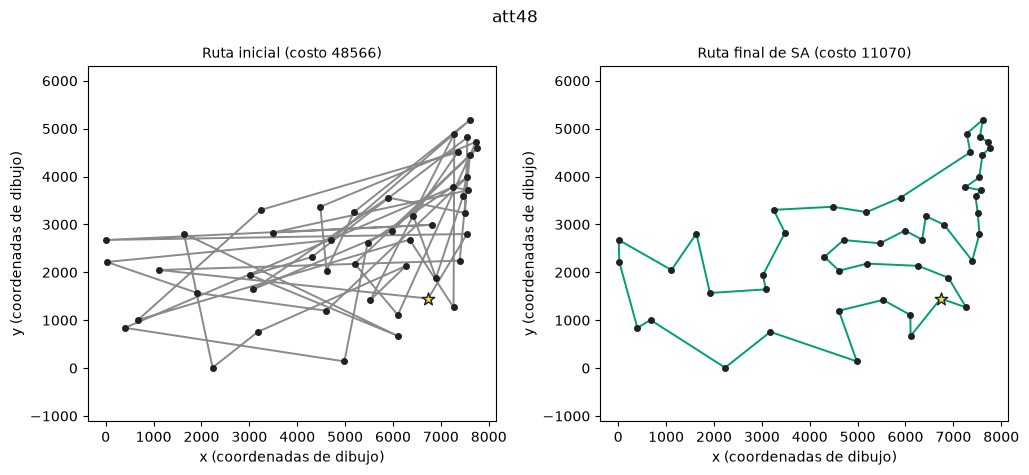

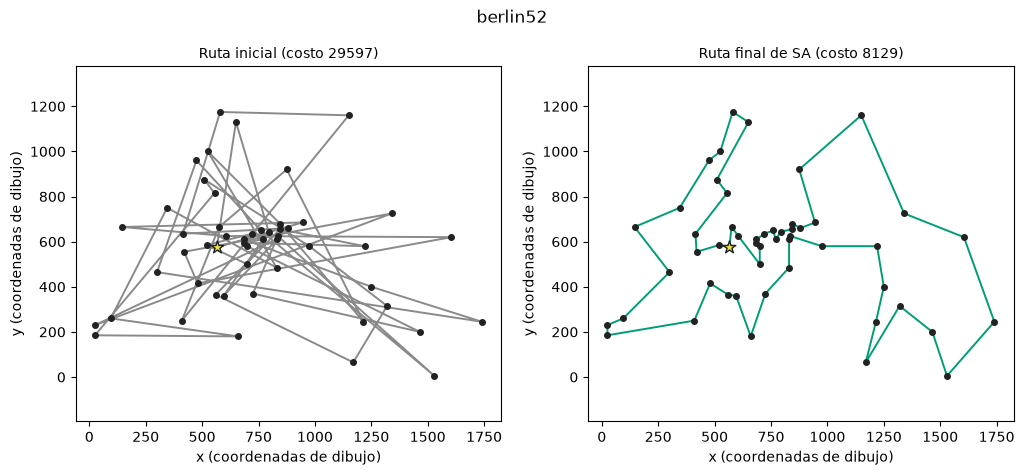

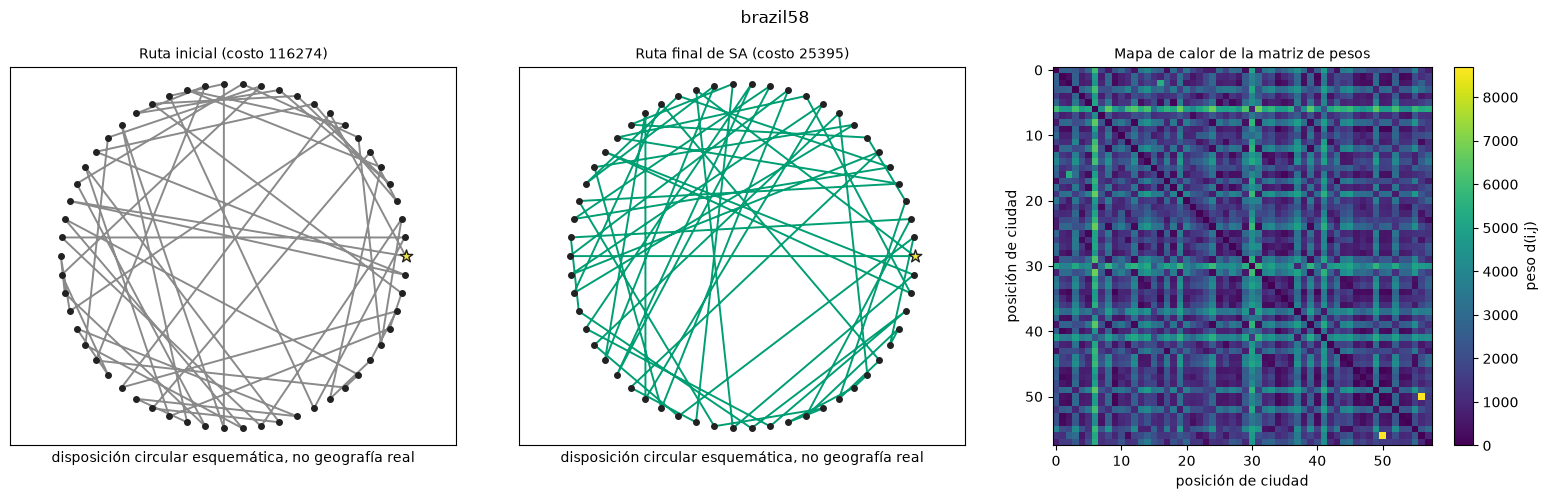

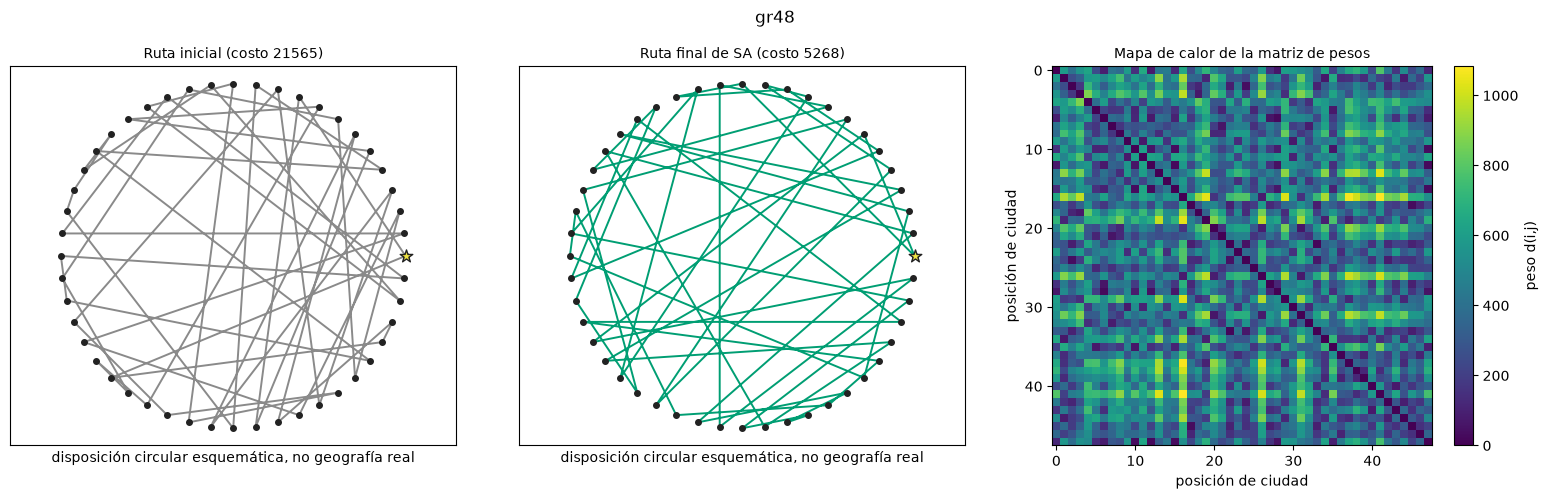

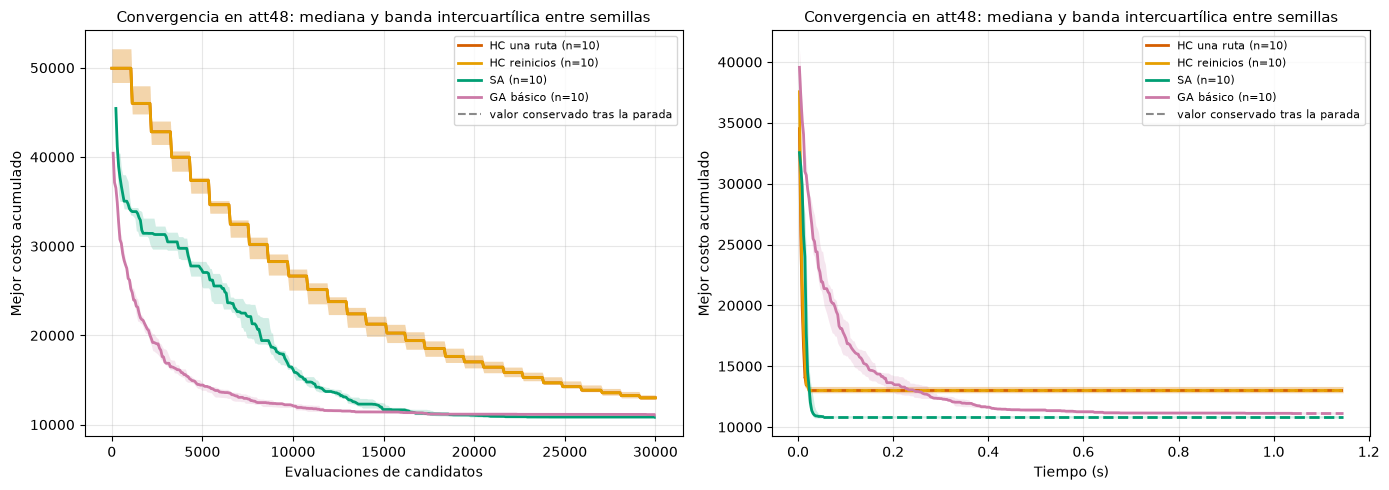

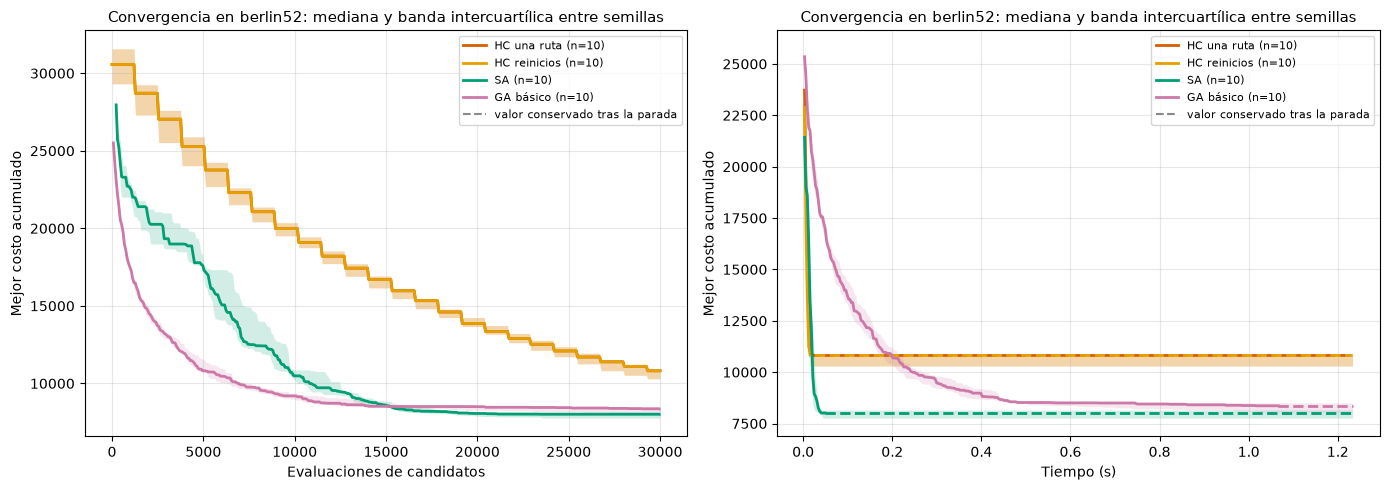

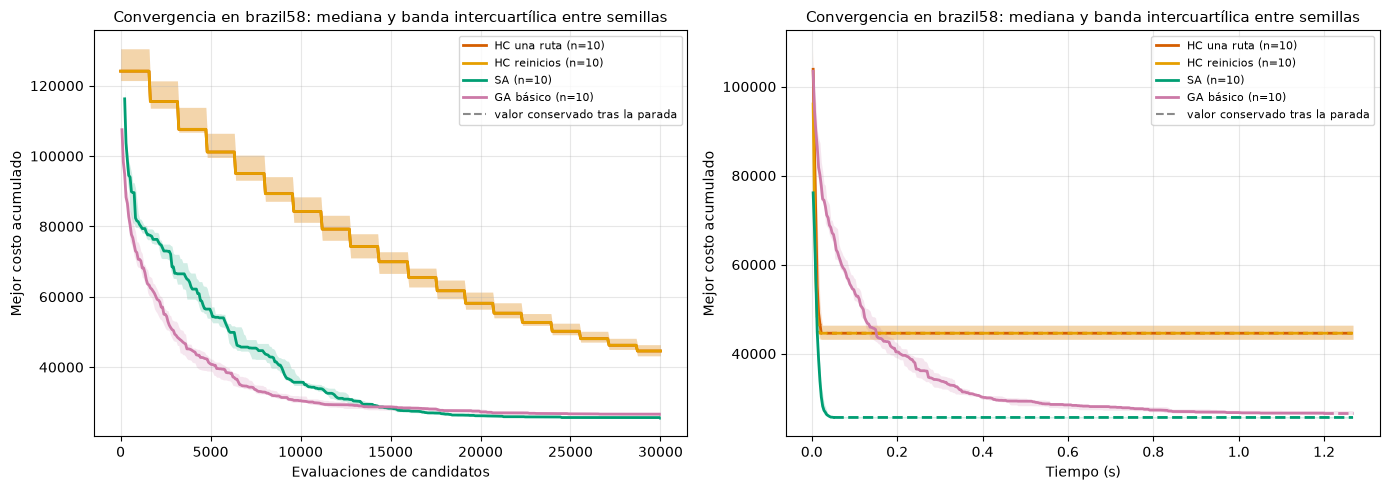

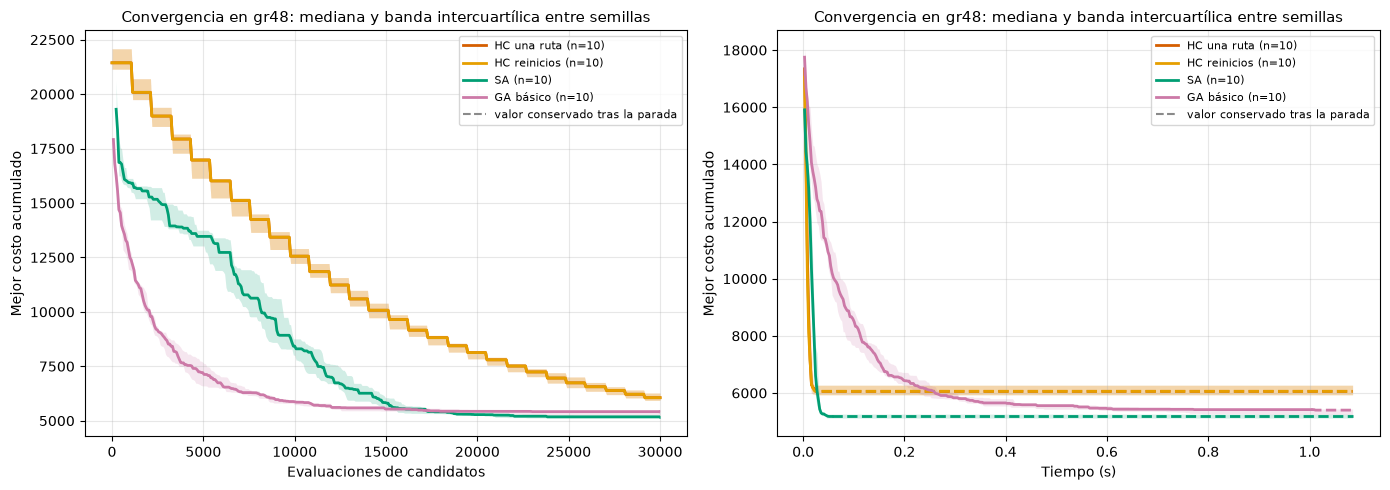

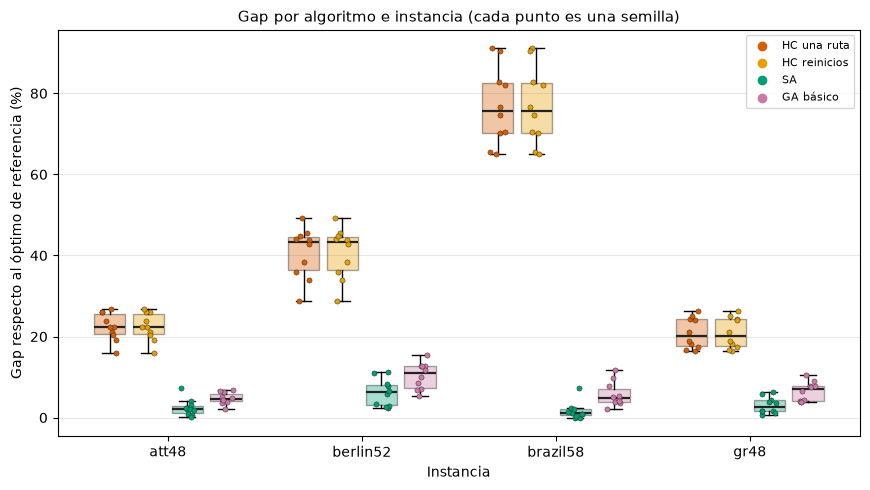

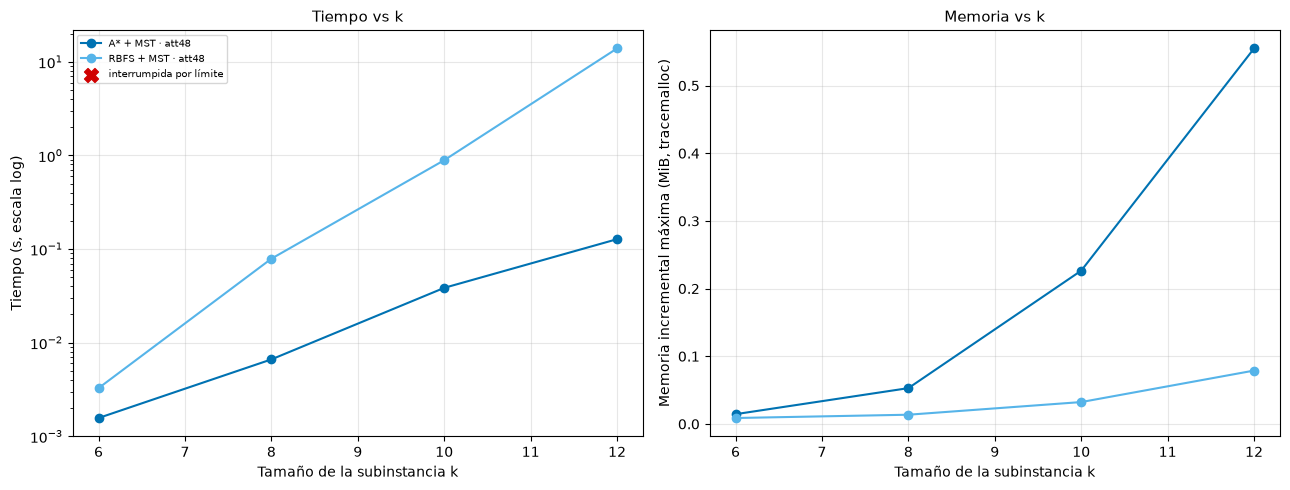

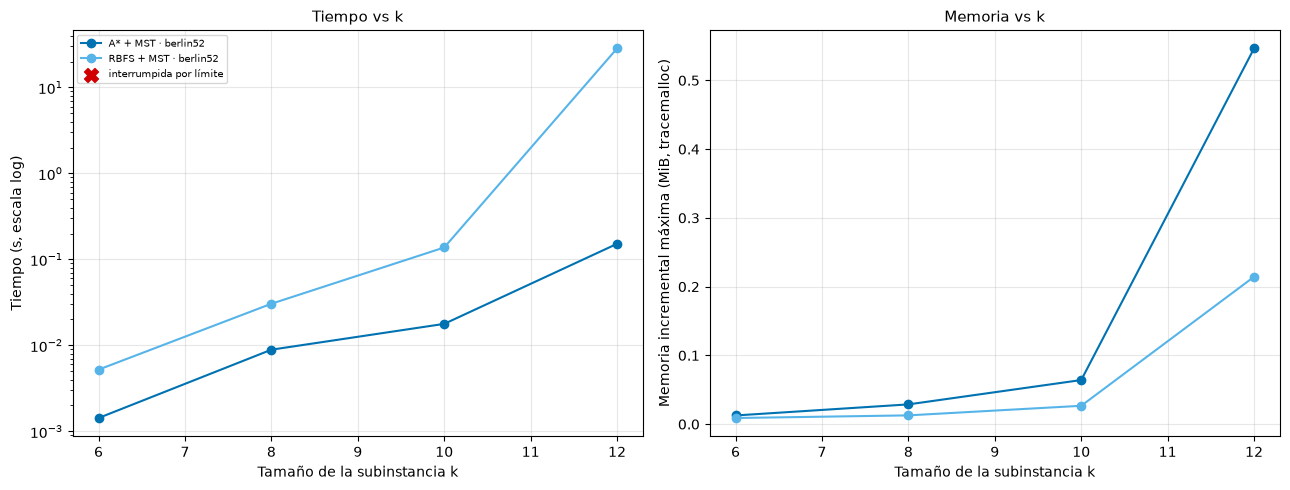

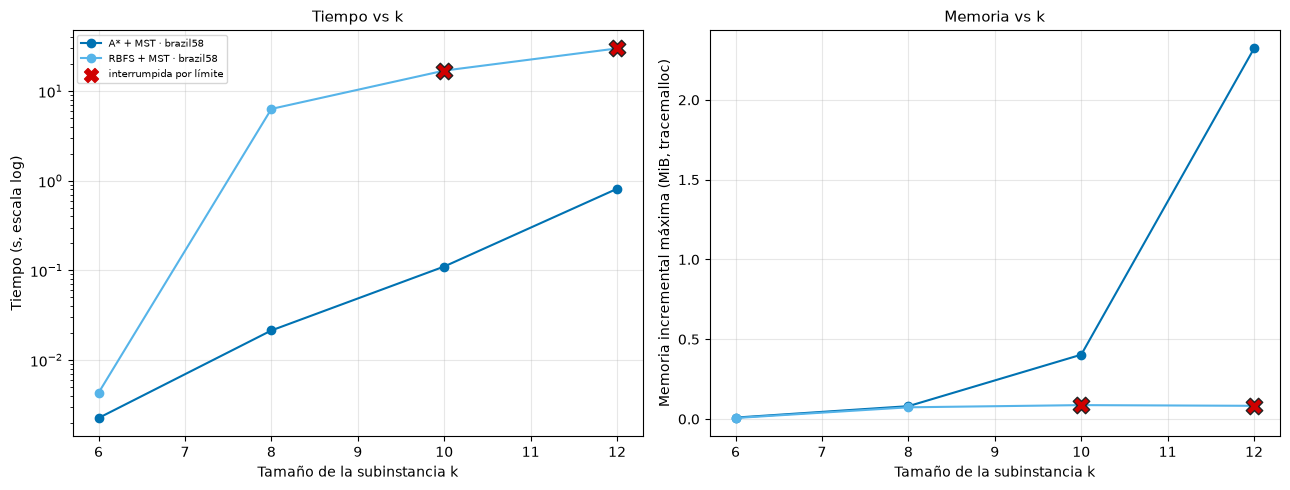

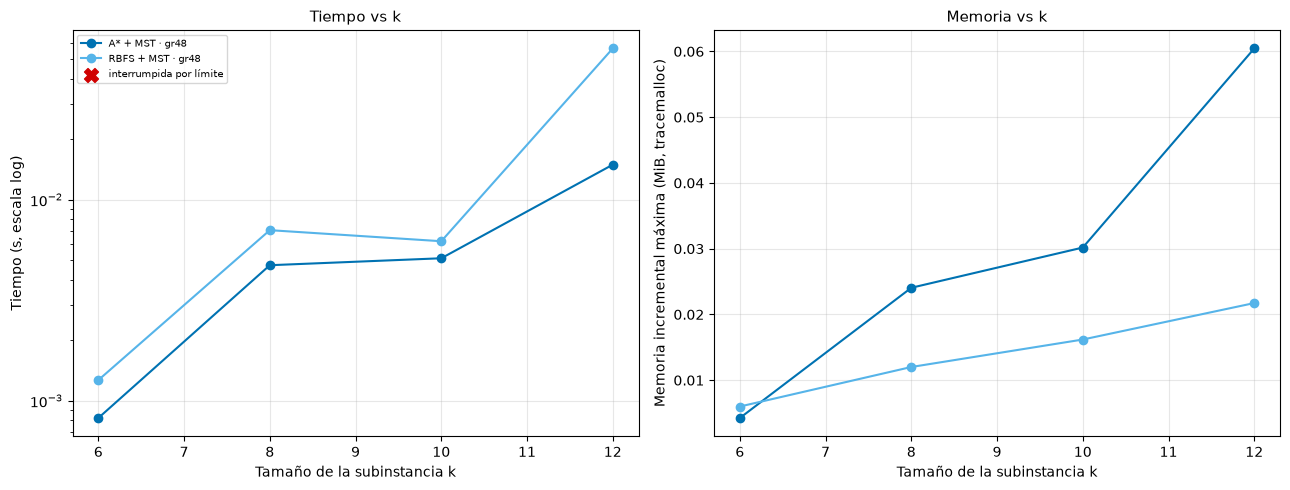

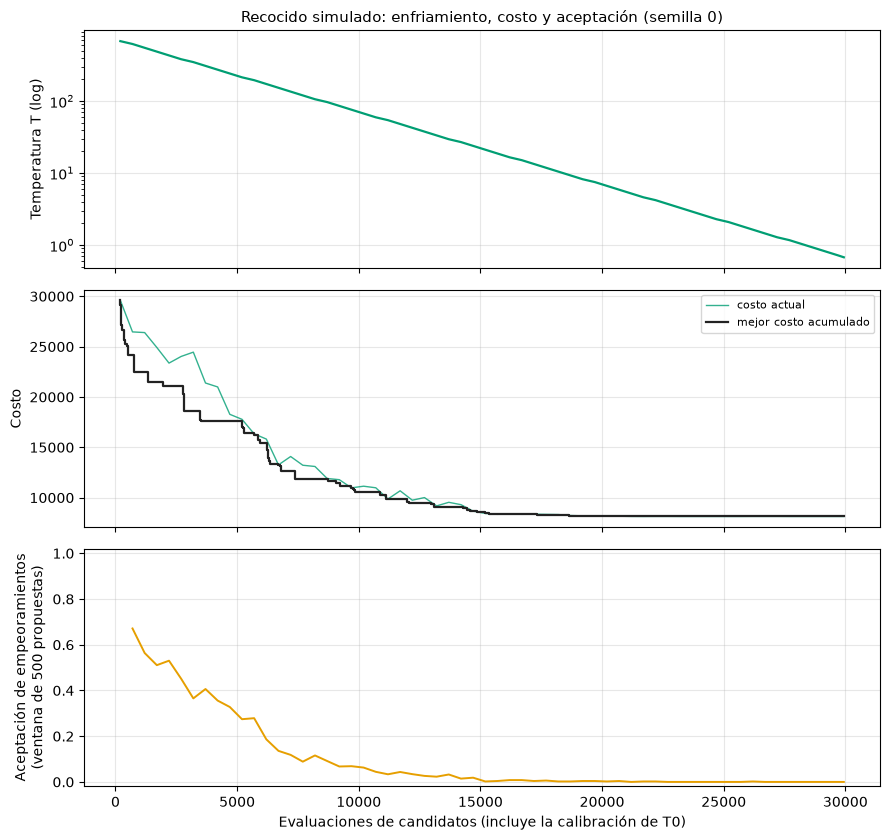

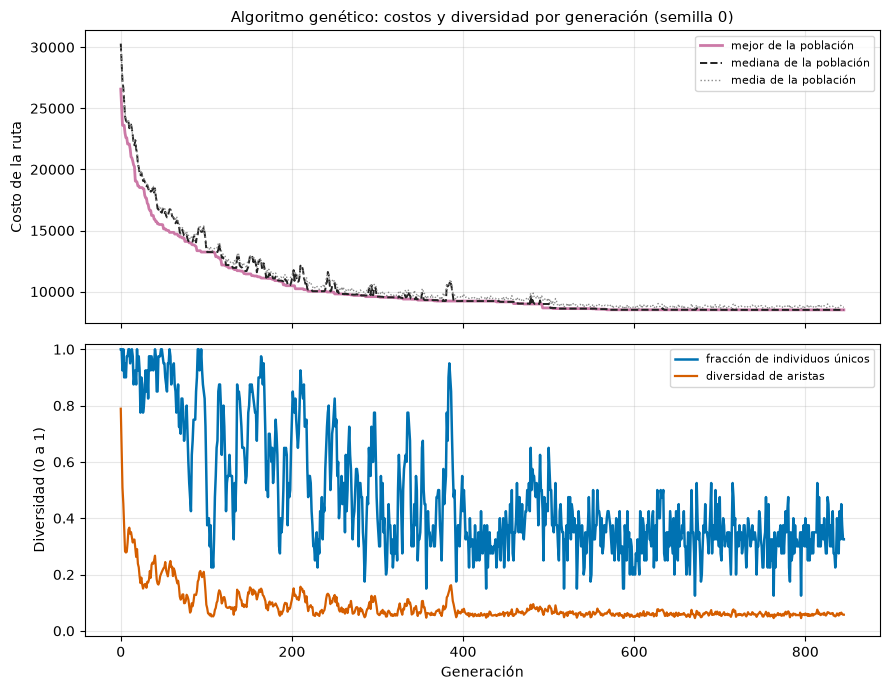

Cuadros generados: 24 → resultados/berlin52_hc.gif


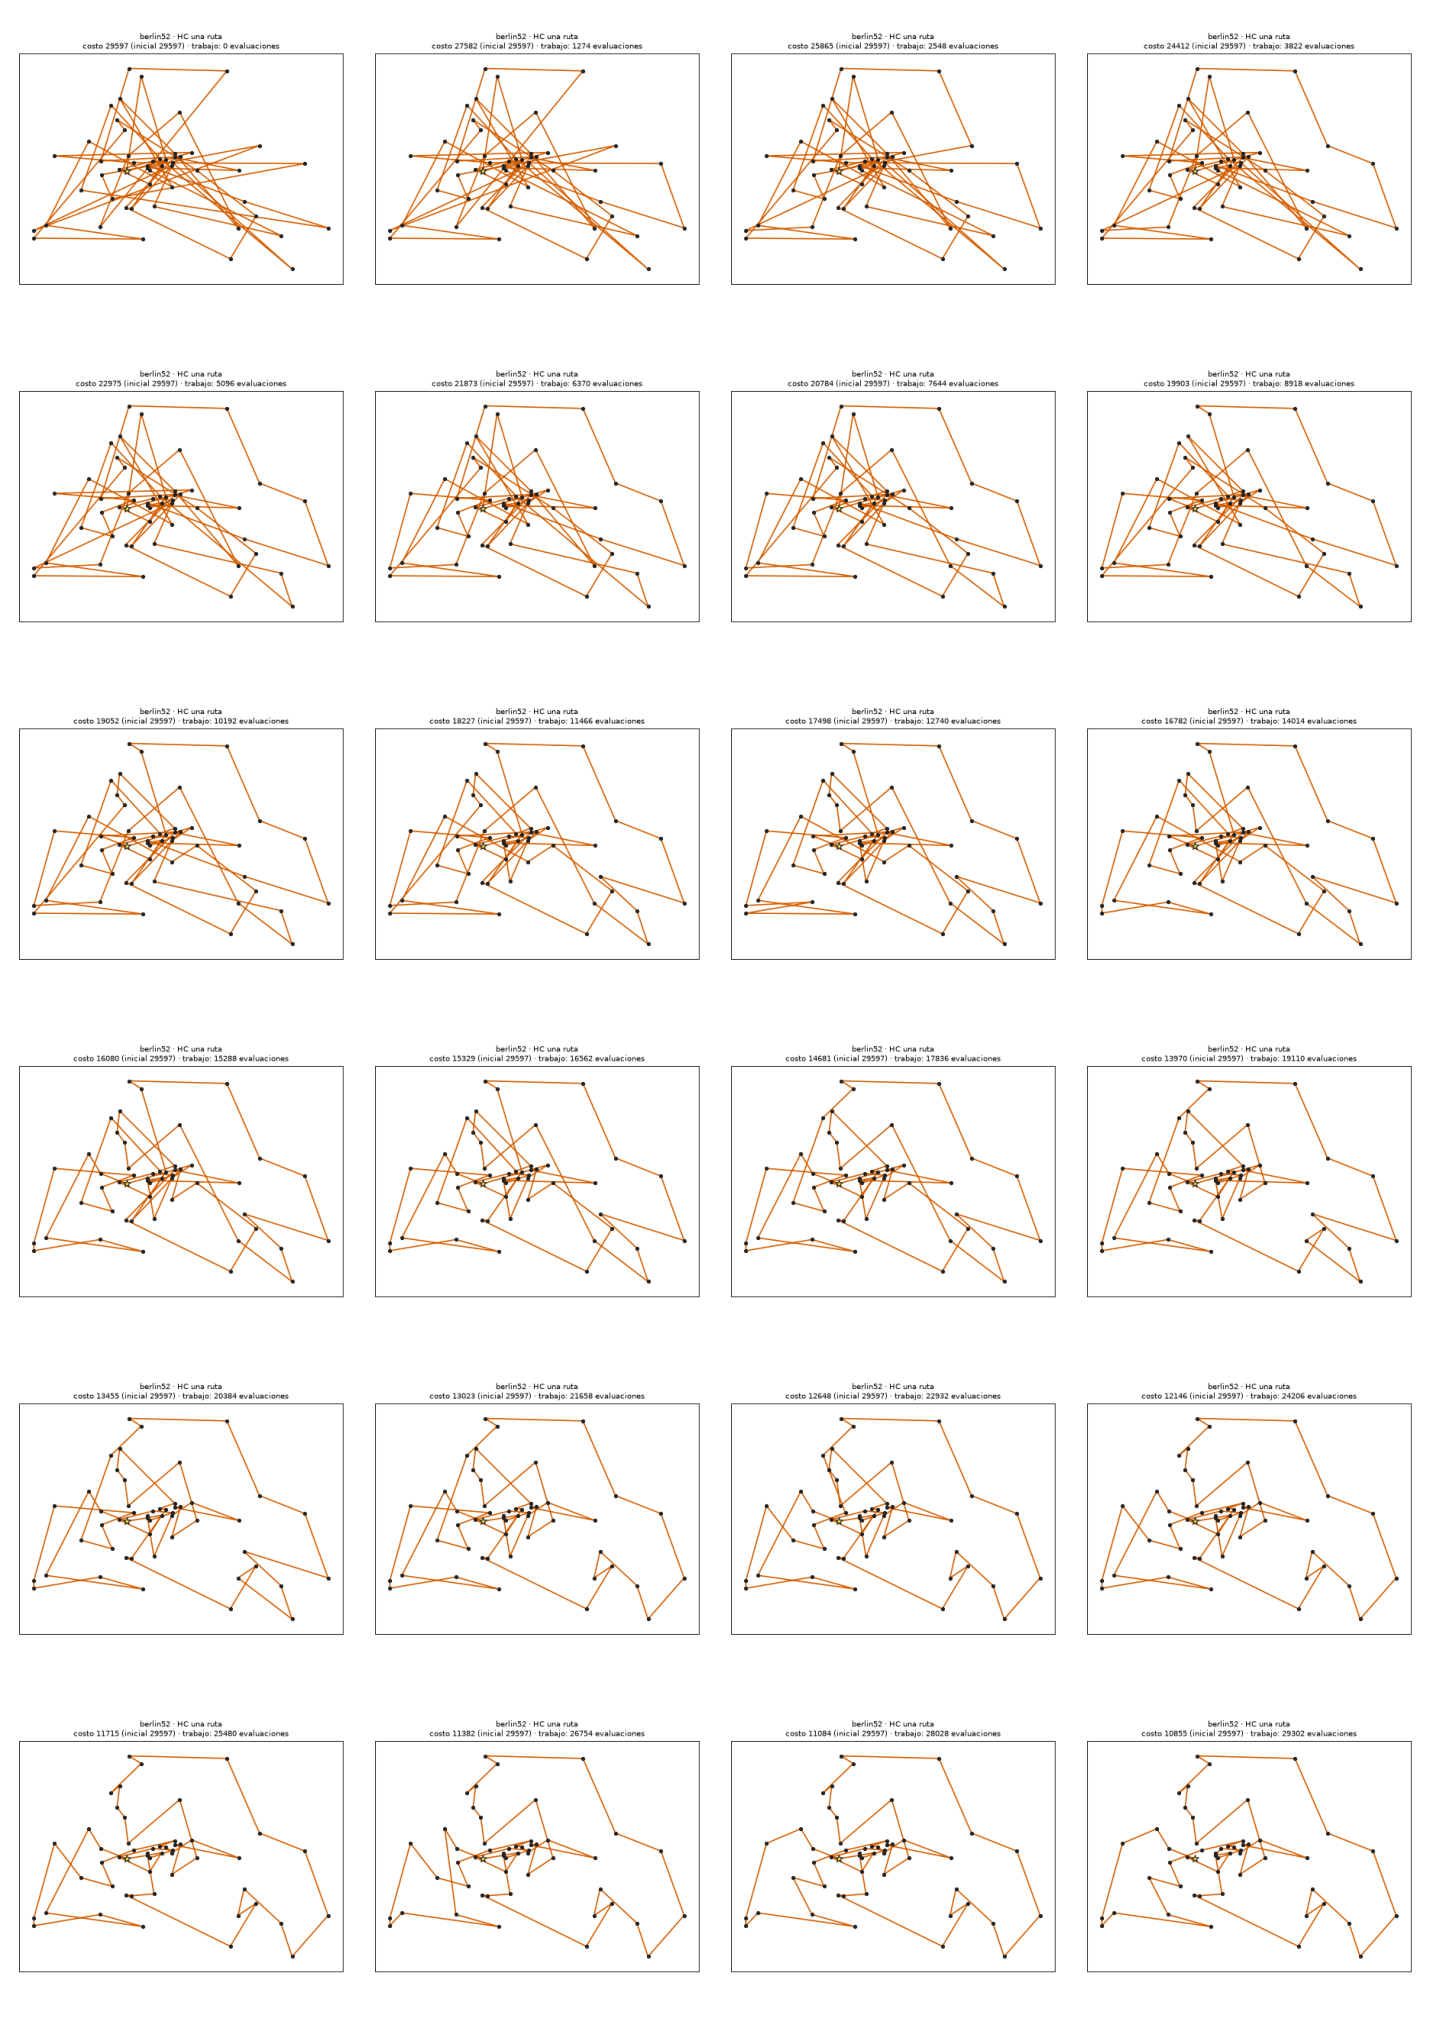

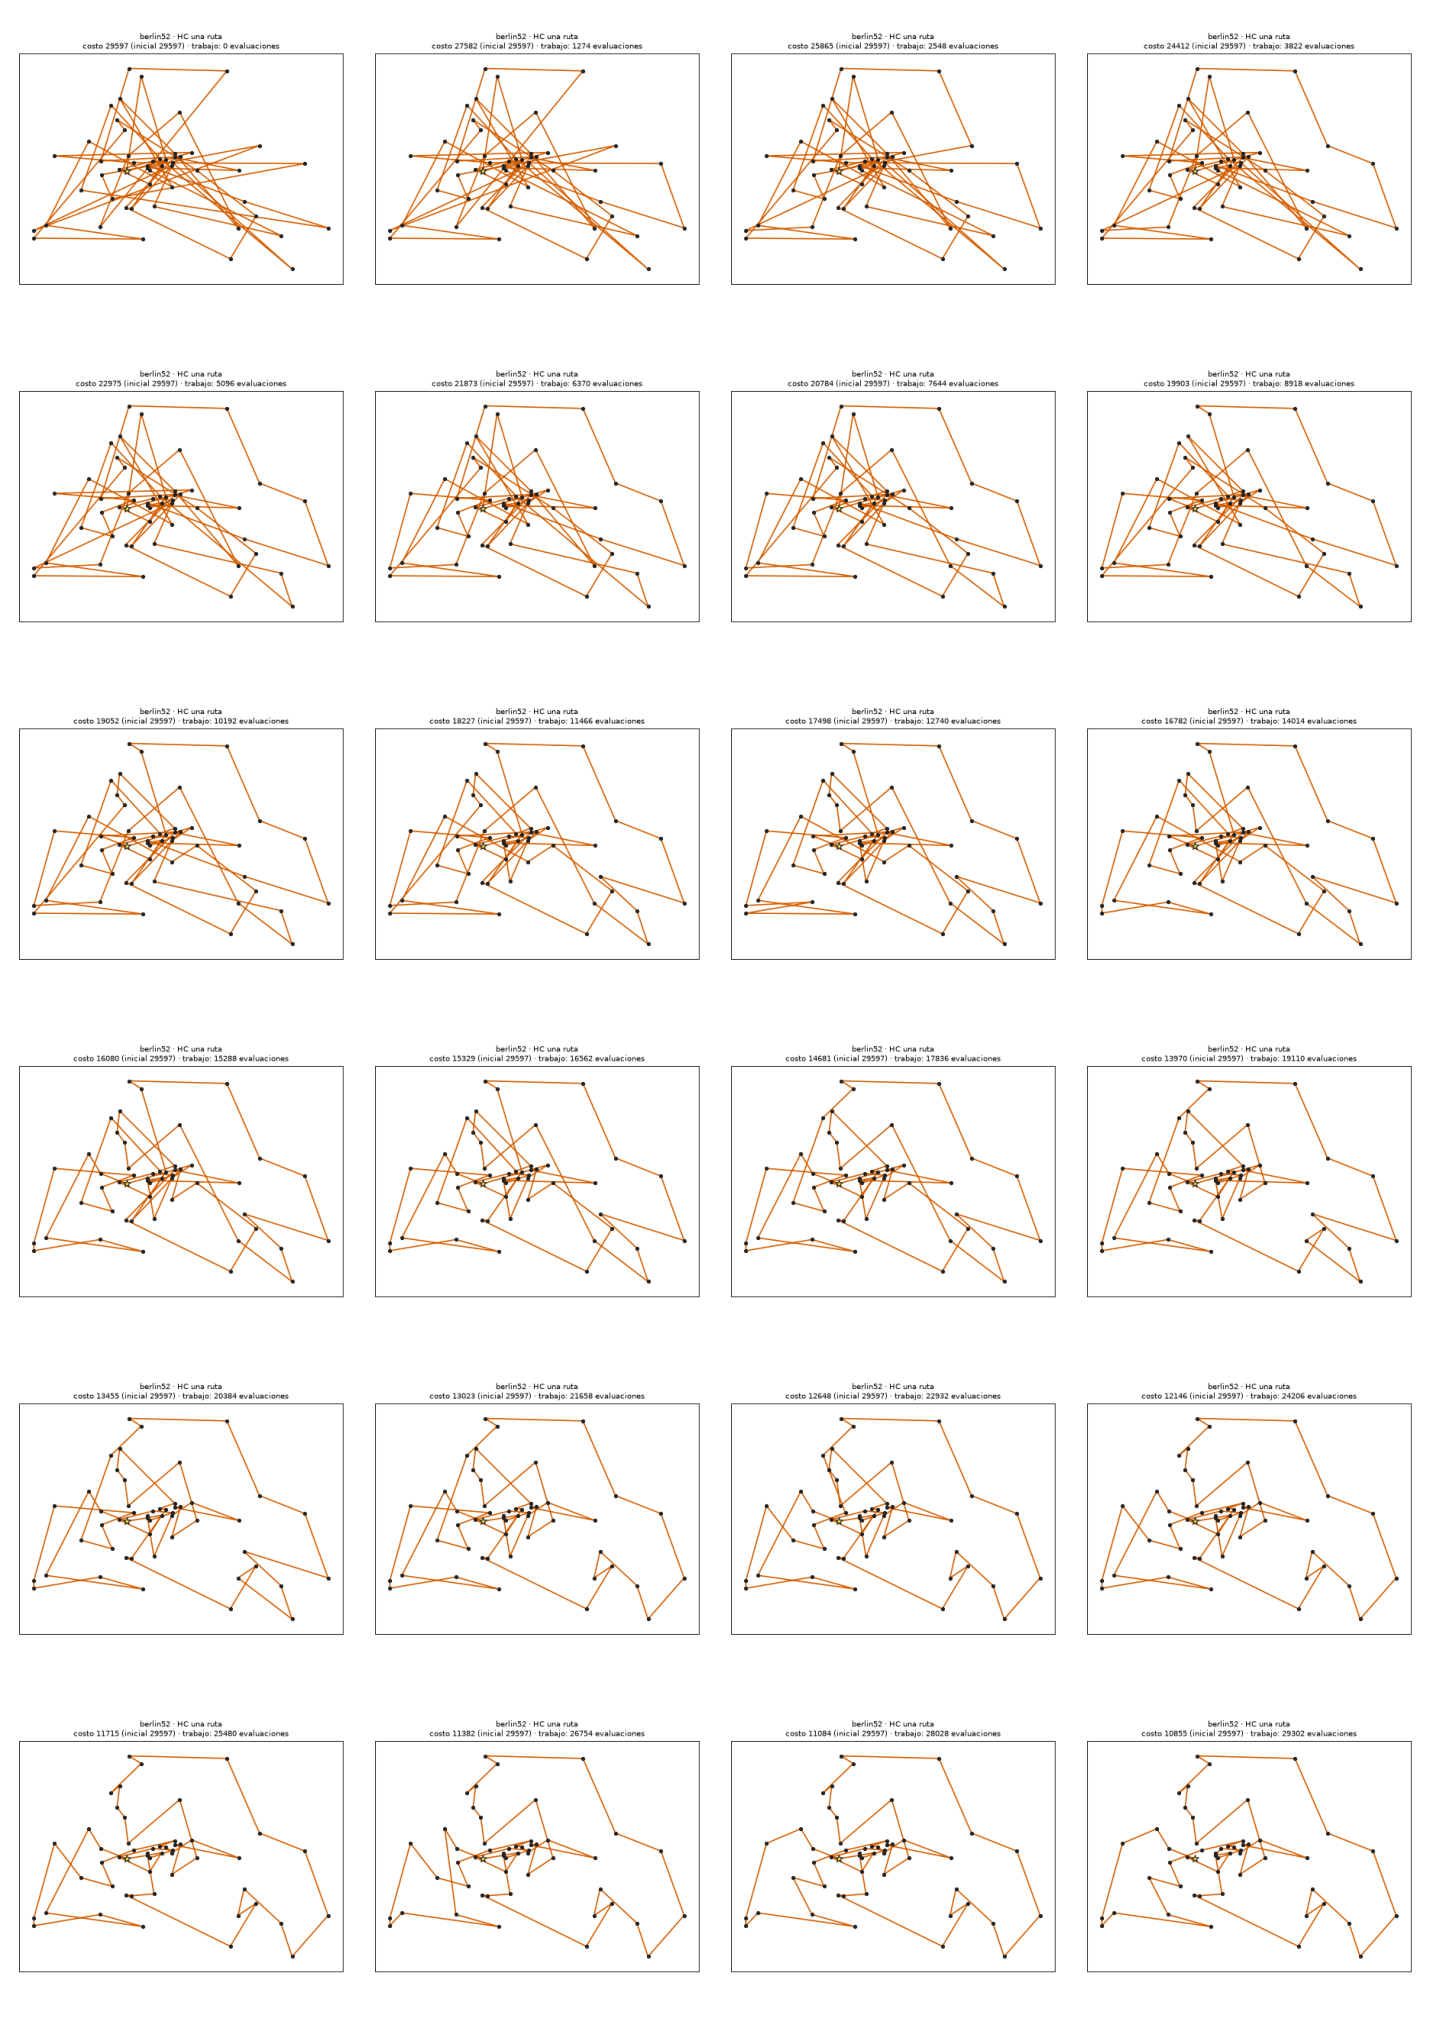

In [25]:
# ===== Visualizaciones obligatorias (15.2) a partir de los registros =====
import matplotlib.pyplot as plt

# 1) Rutas inicial y final: una ejecución de SA por instancia obligatoria (semilla 0).
for _nombre in MANDATORY:
    _inst = INSTANCES[_nombre]
    _r = run_one("SA", _inst, seed=0, config=FROZEN, scale="B", keep_history=True)
    plot_routes(_inst, _r.extras["initial_route"], _r.tour, "SA")
    plt.show()

# 2) Mejor costo acumulado vs. evaluaciones (y vs. tiempo) para HC, SA y GA.
for _nombre in MANDATORY:
    plot_convergence_both(RESULTS_B, _nombre, ("HC", "HC-restarts", "SA", "GA"))
    plt.show()

# 3) Gap por algoritmo e instancia.
plot_gap_boxes(RESULTS_B, MANDATORY, ("HC", "HC-restarts", "SA", "GA"))
plt.show()

# 4) Tiempo y memoria de A* y RBFS contra el tamaño de la subinstancia (interrumpidas marcadas).
for _nombre in MANDATORY:
    plot_exact_scaling(RESULTS_A, _nombre)
    plt.show()

# 5) Temperatura, costo actual y tasa de aceptación de empeoramientos de SA.
_sa = [r for r in RESULTS_B if r.algorithm == "SA" and r.instance == "berlin52" and r.seed == 0][0]
plot_sa(_sa, window=FROZEN["sa"]["window"])
plt.show()

# 6) GA: mejor y mediana de la población + diversidad por generación.
_ga = [r for r in RESULTS_B if r.algorithm == "GA" and r.instance == "berlin52" and r.seed == 0][0]
plot_ga(_ga)
plt.show()

# Animación didáctica de mejoras de berlin52 (Hill Climbing, mejor mejora).
_b52 = INSTANCES["berlin52"]
_hc = run_one("HC", _b52, seed=0, config=FROZEN, scale="B", keep_history=True)
_imagenes = animate_improvements(_b52, _hc.extras["route_history"], "HC", path_gif="resultados/berlin52_hc.gif")
print("Cuadros generados:", len(_imagenes), "→ resultados/berlin52_hc.gif")
show_frames(_imagenes)


### 15.C Cómo leer las figuras y qué conclusión permiten

**Figura 1 · Rutas inicial y final.** Con coordenadas (att48, berlin52) se ve geografía real: la ruta inicial aleatoria de att48 cuesta 48566 y es una maraña de cruces; la ruta final de SA (11070, semilla 0) es casi un lazo limpio, con muy pocos cruces. En brazil58 y gr48 **no hay coordenadas**, así que la disposición circular está rotulada «esquemática, no geografía real» y el cruce de cuerdas en el círculo **no significa nada** sobre la calidad de la ruta: la ruta de SA en brazil58 cuesta 25395 (el óptimo oficial en esa semilla) y en el dibujo parece más enredada que la inicial. El mapa de calor de brazil58 muestra algo que ningún dibujo de la ruta enseña: unas pocas ciudades (franjas claras alrededor de las posiciones 6, 30 y 41) están lejos de casi todas las demás. *Conclusión permitida:* una ruta sin cruces visibles no es necesariamente óptima y, sin coordenadas, el criterio «sin cruces» ni siquiera está definido. *No permitida:* inferir calidad desde el aspecto del dibujo circular.

**Figura 2 · Mejor costo acumulado contra evaluaciones (izquierda) y contra tiempo (derecha).** Línea = mediana de 10 semillas; banda = rango intercuartílico. En att48, GA baja más rápido al principio (la población evalúa muchos individuos distintos desde el inicio), SA arranca lento porque a temperatura alta camina casi al azar y **lo alcanza hacia las 15000 a 17000 evaluaciones**; HC baja por **escalones de ≈ 1000 evaluaciones** (cada escalón es un barrido completo del vecindario que aplica una sola mejora) y termina muy por encima. El tramo discontinuo es *conservación* del mejor valor tras la parada, no evaluaciones ejecutadas. En el eje de **tiempo** la figura cambia de forma: HC y SA terminan en centésimas de segundo y GA necesita más de medio segundo. *Conclusión permitida:* el orden de los métodos depende del eje elegido. *No permitida:* afirmar «GA converge más rápido» sin decir que es por evaluaciones y solo al comienzo.

**Figura 3 · Gap por algoritmo e instancia (cada punto es una semilla).** Muestra lo que una tabla de medianas oculta: las cajas de HC (con y sin reinicios, idénticas) están muy por encima; las de SA y GA están cerca del cero, con SA más baja en las cuatro instancias, pero **las cajas de SA y GA se tocan en berlin52**, y SA tiene puntos de hasta 7 % de gap. *Conclusión permitida:* SA es mejor que GA en mediana en estas cuatro instancias con estos parámetros y este presupuesto. *No permitida:* «SA siempre gana»; con 10 semillas hay ejecuciones de GA que superan a ejecuciones de SA (en 6 de 40 parejas misma-semilla).

**Figura 4 · Tiempo y memoria de A\* y RBFS contra k.** El tiempo está en escala logarítmica: RBFS queda dos órdenes de magnitud por encima de A\* en k = 12; la memoria de A\* crece mucho más rápido que la de RBFS. Las ejecuciones interrumpidas por límite se marcan con una cruz roja (en brazil58, RBFS se interrumpe en k = 10 y k = 12). *Conclusión permitida:* en estas subinstancias, RBFS cambia memoria por tiempo. *No permitida:* extrapolar la pendiente a 48 ciudades, ni comparar estos tiempos con los de los métodos locales (el factor de `tracemalloc`).

**Figura 5 · Temperatura, costo actual y aceptación de empeoramientos de SA** (berlin52, semilla 0; ventana de 500 propuestas). La temperatura baja de forma geométrica (recta en escala logarítmica). La tasa de aceptación de empeoramientos empieza en ≈ 0,67 y cae hasta casi 0 hacia las 15000 evaluaciones; el costo actual deja de separarse del mejor en ese punto. **La segunda mitad del presupuesto casi no mejora el resultado:** SA ya está «congelado». *Conclusión permitida:* con este calendario, un enfriamiento algo más rápido dejaría presupuesto sobrante sin pérdida visible en esta semilla. *No permitida:* asegurar que sea el mejor calendario (no se probó).

**Figura 6 · GA: mejor y mediana de la población, y diversidad por generación** (berlin52, semilla 0). El mejor costo se estanca hacia la generación 400 de ≈ 840, y la mediana llega a pegarse al mejor. La **diversidad de aristas cae a ≈ 0,06 en las primeras ≈ 100 generaciones** y ahí se queda: casi todos los individuos comparten casi todas sus aristas. La fracción de individuos únicos oscila entre ≈ 0,3 y 0,5 porque la mutación crea variantes nuevas sin cesar, pero esas variantes difieren en pocas aristas. Esto es **convergencia prematura**: la población ya no puede explorar con el cruce. *Conclusión permitida:* la fracción de únicos sola engaña; hay que mirar la diversidad de aristas. *No permitida:* atribuir el estancamiento a un solo operador sin probar variantes.

**Animación de berlin52.** `resultados/berlin52_hc.gif` y la secuencia de cuadros bajo la figura muestran cada mejora de Hill Climbing sobre la misma ruta (algoritmo, costo y evaluaciones acumuladas en cada cuadro): los cruces desaparecen uno a uno, y por eso se ve que cada paso de HC cuesta un barrido completo del vecindario.

## 16. Discusión: responda con evidencia

1. ¿Por qué A* y RBFS trabajan con rutas parciales mientras HC, SA y GA trabajan con rutas completas?
2. ¿Por qué el MST da una cota y no una solución? ¿Qué información pierde la relajación?
3. ¿Qué sucede si A* cierra estados usando solamente la última ciudad?
4. ¿Por qué devolver el primer nodo con pendientes vacíos, sin cobrar el retorno, puede dar una respuesta incorrecta?
5. ¿En qué casos RBFS redujo memoria y aumentó recomputación? Muestre números y una traza.
6. ¿Qué diferencias encontró entre att48 y gr48, ambas con 48 ciudades?
7. ¿Cuánto aportaron los reinicios frente a aceptar movimientos peores? Analice distribución, no solo la mejor ejecución.
8. ¿Qué signos de convergencia prematura observó en el GA? ¿Cómo se relacionan con la diversidad?
9. ¿Cambió el ranking al comparar tiempo en lugar de evaluaciones?
10. Si dispone de dos segundos para devolver una ruta, ¿qué elegiría según sus datos? ¿Y si necesita demostrar optimalidad?
11. ¿Qué afirmaciones de complejidad o garantía de la página de referencia requieren matices? Distinga propiedades del algoritmo de particularidades de una implementación.
12. ¿Qué conclusión no puede sostener por falta de repeticiones, límites de recursos o selección de datos?

Cada conclusión debe citar una tabla, figura, prueba o traza del cuaderno. Una afirmación como “GA es mejor” sin presupuesto, instancia y dispersión es insuficiente.


### H. Discusión y conclusiones

Cada respuesta cita la evidencia del cuaderno: tabla de validación (§13), tablas de las escalas A y B (§14), suplemento de HC, comparación a tiempo igual y figuras 1 a 6 (§15).

**1. ¿Por qué A\* y RBFS trabajan con rutas parciales y HC, SA y GA con rutas completas?** Porque necesitan cosas distintas. Un método exacto debe poder *descartar con prueba* y para eso necesita un costo parcial `g` y una cota del resto `h`: solo una ruta a medias tiene ese «resto» que acotar (sección 5 y celda de validación de la heurística). Un método local no demuestra nada: necesita que **todo punto del espacio sea una solución factible** y que un movimiento la conserve; una permutación con 2-opt (o con OX e inversión) lo cumple siempre, y eso permite devolver una ruta válida en cualquier momento, incluso si se interrumpe (tabla de presupuesto en §13). El precio se ve en la escala B: los exactos no devolvieron ninguna ruta en 48 ciudades; los locales devolvieron 10 rutas válidas por instancia.

**2. ¿Por qué el MST da una cota y no una solución? ¿Qué información pierde?** El MST es una relajación: conecta todas las ciudades pendientes con el menor costo, pero **no impone grado dos ni un ciclo único**, así que puede tener una ciudad con tres vecinas y nunca cierra el recorrido. Cualquier camino que recorra las pendientes es un árbol, por eso cuesta al menos el MST (demostración de §6). Lo que pierde es justamente lo que hace difícil el TSP; la cota queda por debajo del costo real, con holgura de 0 o 1 en el microcaso y mayor en las instancias grandes (en las completas, A\* expandió solo unos 1500 a 2400 nodos en 30 s sin terminar). Además, en la raíz las dos conexiones mínimas pueden elegir la misma ciudad.

**3. ¿Qué sucede si A\* cierra estados usando solamente la última ciudad?** Pierde el óptimo, o ni siquiera encuentra una ruta. Evidencia (§13, fila «Dos conjuntos pendientes distintos»): las rutas parciales `0→1→3` y `0→1→2→3` terminan en la misma ciudad; la primera es más barata hasta ahí (g = 2 contra 3), pero su mejor total es 14 y el de la segunda es 5, el óptimo. Con la clave por ciudad, el algoritmo descarta la segunda y, en las dos matrices probadas, **no devuelve ninguna ruta**; con la clave completa devuelve el óptimo (5 y 27). Es el defecto de la implementación de TSP Solve.

**4. ¿Por qué devolver el primer nodo con pendientes vacíos, sin cobrar el retorno, puede dar una respuesta incorrecta?** Porque el costo queda sin una arista y se declara una meta que no lo es. Con las rutas óptimas oficiales (celda de auditoría de §3), omitir el regreso da 10481 en att48 (−1,4 % bajo el óptimo 10628), 7496 en berlin52 (−0,6 %) y 4966 en gr48 (−1,6 %): costos «mejores que el óptimo», imposibles. La meta es `closed`, no `remaining = ∅`.

**5. ¿En qué casos RBFS redujo memoria y aumentó recomputación?** Con k = 12 en att48: 31961 expansiones contra 376 de A\* (85 veces más) y 80 KiB contra 568 KiB (unas 7 veces menos); en brazil58, k = 12, 84 KiB contra 2,3 MiB (28 veces) pero RBFS no termina. En las instancias completas, tras 30 s: A\* retiene unos 55 a 70 mil nodos y 23 a 29 MiB; RBFS, ≈ 0,1 MiB y ≈ 900 a 1400 regeneraciones. Traza con retroceso en el caso de 4 ciudades de §8.1: B se expande, se descarta con valor respaldado 14, D falla con 15 y B **reaparece** y se vuelve a expandir. No es una ley: en gr48 casi no retrocede (79 expansiones contra 38).

**6. ¿Qué diferencias encontré entre att48 y gr48, ambas con 48 ciudades?** (i) att48 tiene coordenadas (distancia ATT) y gr48 solo una matriz: en gr48 no hay dibujo geográfico y el criterio «sin cruces» no existe (figura 1). (ii) En subinstancias de 12 ciudades, la cota MST es mucho más ajustada en gr48: A\* expande 38 nodos contra 376 y RBFS casi no regenera (79 contra 31961). (iii) En las instancias completas los exactos fracasan igual. (iv) Entre los locales, SA es algo mejor en att48 (gap mediano 2,13 % contra 2,63 %) y GA bastante mejor en att48 (4,70 % contra 7,03 %); HC es parecido (22,3 % y 20,1 %). **Lo que no puedo afirmar** es la causa estructural: mis datos muestran la diferencia, no su explicación.

**7. ¿Cuánto aportaron los reinicios frente a aceptar movimientos peores?** En la escala B, **nada**: HC con reinicios es idéntico a HC en las 40 ejecuciones, porque HC necesita entre ≈ 45 000 y 92 000 evaluaciones para su primer óptimo local y el presupuesto es de 30 000 (suplemento de HC, tabla (a)). Aceptar empeoramientos aportó mucho: SA gana a HC en las 40 parejas misma-semilla y su gap mediano es de 1,1 % a 6,2 % contra 20 % a 76 %. Distribución: SA tiene una desviación estándar del gap de ≈ 2 a 3,4 puntos y HC de 3,4 a 9,5 (figura 3). Los reinicios sí funcionan cuando el ascenso cabe: en burma14, de 5 a 10 óptimos de 10 semillas; en gr17, de 1 a 8.

**8. ¿Qué signos de convergencia prematura observé en el GA? ¿Cómo se relacionan con la diversidad?** (i) La diversidad de aristas cae a ≈ 0,06 en las primeras ≈ 100 generaciones y no se recupera (figura 6). (ii) La mediana de la población se pega al mejor costo. (iii) El mejor costo se estanca hacia la mitad del presupuesto. (iv) La fracción de individuos únicos *engaña*: se mantiene en 0,3 a 0,5 porque la mutación crea variantes sin parar. En el experimento deliberado (eil51, población 12, torneo 12, pm = 0), los únicos caen a 0,083 y las aristas a 0,04, con costo 1555; con la configuración sana quedan 0,87 y 0,25, con costo 757. Con pm = 0,1 la diversidad final cae a ≈ 0,12 y el gap sube (calibración).

**9. ¿Cambió el ranking al comparar tiempo en lugar de evaluaciones?** Sí, mucho. A 30000 evaluaciones: SA < GA ≪ HC. A 2 s de reloj: HC con reinicios ≈ SA ≪ GA (tabla de tiempo igual): HC procesa unas 60 veces más evaluaciones por segundo que GA, completa decenas de ascensos y baja de 20–76 % a menos de ≈ 0,5 % de gap mediano. Lo único que no cambia es que GA queda último a tiempo igual.

**10. Si dispongo de dos segundos, ¿qué elegiría según mis datos? ¿Y si necesito demostrar optimalidad?** Con dos segundos, HC con reinicios o SA (gap mediano bajo 1 % en las cuatro instancias); no GA. Con 10 semillas no declaro ganador entre los dos. Para *demostrar* optimalidad solo sirven A\* y RBFS, y en mis datos lo logran hasta k = 12 (A\* en menos de un segundo); en 48 ciudades no certificaron nada en 30 s, así que para esas instancias no puedo ofrecer certificado con estas implementaciones.

**11. ¿Qué afirmaciones de complejidad o garantía de la página de referencia requieren matices?** Distingo propiedades del algoritmo de particularidades de la implementación. *Del algoritmo:* A\* con heurística admisible es óptimo, pero su memoria crece de forma exponencial (en mis corridas, decenas de miles de nodos y ≈ 25 MiB en 30 s); RBFS tiene memoria lineal en la profundidad, pero en TSP la profundidad y el ramificado crecen con n, y su tiempo se dispara por regeneración (85 veces más expansiones en att48 con k = 12). *De la implementación de la página:* la clave de estado por ciudad (pierde el óptimo, caso 3), el término `- depth` (el costo reportado deja de ser el largo de la ruta), el `max` de RBFS aplicado sobre una copia (no tiene efecto; en mi implementación sí actúa: elevó el valor de 235 de 1493 hijos en att48 con k = 8), «tiempo O(∞)» (no es una cota) y «A\* de grafo óptimo» (solo 8 de 48 orígenes dieron el óptimo). La admisibilidad de su heurística no está demostrada en la página; yo la demostré, y comprobé también la consistencia.

**12. ¿Qué conclusión no puedo sostener por falta de repeticiones, límites de recursos o selección de datos?**
- **«SA es mejor que GA» en general.** Solo para estas cuatro instancias, 30000 evaluaciones, parámetros calibrados con 5 semillas en tres instancias y sin calibrar `pc` ni el torneo; GA superó a SA en 6 de 40 parejas.
- **El ranking por tiempo** depende de Python y de este equipo; en otro lenguaje el factor entre HC y GA sería distinto.
- **Certificados más allá de k = 12**, y cualquier extrapolación de las pendientes de la figura 4 a 48 ciudades.
- **Que RBFS «no puede» con brazil58:** el límite de 30 s es un límite de mi protocolo, no una propiedad del algoritmo (y berlin52 con k = 12 está en el borde de ese límite).
- **La memoria de los métodos locales** no se midió, y los tiempos de A\* y RBFS incluyen el sobrecosto de `tracemalloc` (factor de ≈ 5 a 9).
- **Las subinstancias** son los primeros k identificadores, un subconjunto concreto, no una muestra aleatoria; no representan a todas las de ese tamaño.
- **Diferencias finas entre métodos:** con 10 semillas no hice pruebas de hipótesis; las medianas y las cajas muestran órdenes de magnitud, no diferencias de décimas.

## 17. Plan de trabajo y evaluación

| Etapa propuesta | Producto verificable |
|---|---|
| Días 1–2 | Fichas TSPLIB, contrato de ruta y microcaso manual |
| Días 3–5 | MST, A* y RBFS validados en casos pequeños |
| Días 6–8 | Vecindad, HC, SA y GA validados |
| Días 9–11 | Calibración separada y experimentos congelados |
| Días 12–14 | Figuras, discusión, ejecución completa y sustentación |

| Criterio | Peso |
|---|---:|
| Modelo, distancias oficiales y auditoría | 15 % |
| A* + MST: formulación, pruebas y trazas | 15 % |
| RBFS: límites, respaldo de f y medición | 15 % |
| HC vs. SA: operadores y comparación controlada | 15 % |
| GA: permutaciones, OX, mutación y diversidad | 15 % |
| Protocolo, reproducibilidad y análisis de resultados | 15 % |
| Claridad, visualizaciones y sustentación | 10 % |

Las búsquedas exactas que no terminan en las instancias completas **no se penalizan** si son correctas, respetan el protocolo y documentan sus límites. Encontrar una ruta barata no sustituye la corrección ni la calidad experimental.


## 18. Espacios de desarrollo del estudiante

Agregue sus propias celdas de código y Markdown debajo de cada apartado. Mantenga visibles enunciados y pseudocódigos.

### A. Integrantes, entorno y decisiones

*Complete integrantes, equipo, versiones, presupuestos, políticas de desempate y ayuda externa utilizada.*

### B. Datos y verificación del costo

*Agregue lectura de instancias, fichas y pruebas de rutas.*

### C. Modelo de búsqueda, MST y microcaso

*Agregue desarrollo manual, componentes y prueba de admisibilidad.*

### D. A* y RBFS

*Agregue implementaciones, trazas, validación exacta y pruebas de interrupción.*

### E. Vecindad, HC y SA

*Agregue operadores, validación del delta y comparación controlada.*

### F. Algoritmo genético

*Agregue OX manual, operadores, pruebas de permutación y diversidad.*

### G. Experimentos y visualizaciones

*Agregue configuraciones congeladas, registros, tablas, curvas y animación.*

### H. Discusión y conclusiones

*Responda las preguntas y formule conclusiones respaldadas por sus resultados.*


### A. Integrantes, entorno y decisiones (completado)

**Integrantes:** Santiago y Januar Mena (trabajo en pareja, la modalidad que propone el enunciado).

**Presupuestos y límites congelados** (todos viven en `FROZEN`, en la sección 14):

| Concepto | Valor |
|---|---|
| Semillas de evaluación | 0 a 9 (la calibración usó 100 a 104) |
| Escala B: evaluaciones y tiempo por ejecución | 30000 evaluaciones y 30 s, lo que ocurra primero |
| Escala A: evaluaciones y tiempo por ejecución (aproximados) | 5000 evaluaciones y 30 s |
| Exactos (A\* y RBFS) | 30 s, 100000 expansiones o 256 MiB de memoria incremental |
| Subinstancias | los primeros k = 6, 8, 10 y 12 identificadores ordenados |
| SA | α = 0,97; p0 = 0,8; Tmin = 10⁻³·T0; propuestas por temperatura derivadas del presupuesto |
| GA | población 40; 2 élites; pc = 0,9; pm = 0,3; torneo 3 |

**Políticas de desempate.** A\*: se extrae el nodo con menor `f`; si empatan, el de menor `h` (más cercano a la meta) y después el contador de inserción (determinista). RBFS: orden por `(f, h)` con desempate estable por orden de generación. HC: gana el primer vecino con el mejor delta estricto. GA: torneo por costo mínimo; ante un empate gana el primer participante sorteado.

**Decisiones.** Están todas en `BITACORA.md`, con sus alternativas, motivos y consecuencias, y con los errores que cometí y corregí (D-09 numeración de nodos, D-13 contraejemplo de la clave de estado, A-09 el `max` de RBFS, entre otros).

**Ayuda externa declarada.** Usamos un asistente de IA (**Claude**, mediante Claude Code) para programar los módulos, escribir las pruebas, ejecutar los experimentos y redactar estos apuntes; el trabajo se repartió entre agentes en paralelo por módulo y nosotros revisamos los resultados. Además usamos: `tsplib95` (lectura de instancias y pesos oficiales, sin resolver nada), las páginas de TSP Solve y de TSPLIB y el cuaderno de Peter Norvig sobre TSP como lectura de apoyo, y el pseudocódigo de AIMA para RBFS. Ninguna búsqueda ni optimización delega en SimpleAI, DEAP ni un solver. Ambos integrantes podemos explicar y modificar cualquier fragmento durante la sustentación; para eso preparamos guías de estudio por etapa.

**Entorno de ejecución.** Se imprime a continuación, con la herramienta de medición de memoria y sus límites.

In [26]:
# ===== Entorno de ejecución (sección A) =====
from IPython.display import Markdown, display

_info = environment_report()
display(Markdown("\n".join("- **{0}:** {1}".format(k, v) for k, v in _info.items())))


- **cpu:** Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
- **nucleos_logicos:** 12
- **nucleos_fisicos:** 8
- **ram_total_bytes:** 16869351424
- **sistema_operativo:** Windows 11 (10.0.26300)
- **python:** 3.13.7
- **implementacion:** CPython
- **entorno:** Jupyter (ipykernel)
- **paquetes:** {'numpy': '2.5.4', 'matplotlib': '3.11.2', 'pillow': '12.3.0', 'tsplib95': '0.7.1', 'ipykernel': '7.4.0', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'pytest': '9.1.1', 'psutil': '7.2.2'}
- **resolucion_reloj:** 1e-07
- **memoria:** tracemalloc: mide solo asignaciones de Python, de forma INCREMENTAL respecto al inicio del solver; no es la memoria del proceso completo (no incluye la matriz D cargada antes ni memoria de extensiones en C).

### Dónde está cada apartado (B a H)

Por orden de lectura, el trabajo de cada espacio está debajo del enunciado que lo motiva:

| Espacio | Contenido | Sección del cuaderno |
|---|---|---|
| B. Datos y verificación del costo | lectura de instancias, fichas, distancias a mano, rutas oficiales, rutas inválidas | §3 (debajo de 3.2) |
| C. Modelo de búsqueda, MST y microcaso | modelo común, contrato, MST con demostración, microcaso a mano | §4, §6.1 y §6.2 |
| D. A\* y RBFS | implementaciones, trazas, validación exacta, interrupciones | §7, §8 y §8.1 |
| E. Vecindad, HC y SA | 2-opt, delta validado, HC, SA y comparación controlada | §9, §10, §11 y §14 (celda HC vs. SA) |
| F. Algoritmo genético | OX a mano, operadores, pruebas de permutación, diversidad | §12 y §12.1 |
| G. Experimentos y visualizaciones | configuración congelada, calibración, registros, tablas, curvas y animación | §14, §15 y §15.2 |
| H. Discusión y conclusiones | las 12 preguntas con evidencia | §16 |

## 19. Lista de entrega

- [ ] El cuaderno se ejecuta desde un kernel reiniciado con archivos de datos locales.
- [ ] Las cuatro instancias obligatorias están auditadas y los pesos son oficiales.
- [ ] Los cinco algoritmos tienen implementación propia y pruebas pertinentes.
- [ ] El costo incluye cierre y todas las rutas entregadas son permutaciones válidas.
- [ ] Hay pruebas pequeñas de optimalidad para A* y RBFS.
- [ ] Se distinguen swap, 2-opt y mutación por inversión.
- [ ] Los registros incluyen semillas, parámetros, presupuestos y causas de parada.
- [ ] Las comparaciones estadísticas incluyen las diez semillas y resultados censurados.
- [ ] Las gráficas proceden de registros y las conclusiones remiten a evidencia.
- [ ] Se entrega el cuaderno con salidas guardadas y los datos o instrucciones de descarga.
- [ ] Los integrantes pueden explicar cualquier fragmento y hacer un cambio durante la sustentación.


### Lista de entrega: estado y evidencia

| | Punto | Evidencia en este cuaderno |
|---|---|---|
| ✅ | El cuaderno se ejecuta desde un kernel reiniciado con archivos de datos locales | `tools/ejecutar_cuaderno.py` lo ejecuta de arriba abajo en un kernel nuevo y falla en la primera celda con error; los datos están en `datos/` |
| ✅ | Las cuatro instancias obligatorias están auditadas y los pesos son oficiales | §3: fichas, fórmulas EUC_2D y ATT comparadas en todos los pares, rutas óptimas oficiales con costo exacto |
| ✅ | Los cinco algoritmos tienen implementación propia y pruebas pertinentes | `tsp/astar.py`, `rbfs.py`, `hc.py`, `sa.py`, `ga.py`; batería de §13 y `tests/` |
| ✅ | El costo incluye cierre y todas las rutas entregadas son permutaciones válidas | `tour_cost` único; las celdas de las escalas A y B validan cada `RunResult` (ruta válida, costo recalculado, gap no negativo) |
| ✅ | Hay pruebas pequeñas de optimalidad para A\* y RBFS | §13 (enumeración exhaustiva) y escala A (Held-Karp como tercer certificado, invarianza del origen) |
| ✅ | Se distinguen swap, 2-opt y mutación por inversión | §1.A y §6.2 (swap contra 2-opt con un ejemplo), §9, §12 |
| ✅ | Los registros incluyen semillas, parámetros, presupuestos y causas de parada | `RunResult` y `resultados/*.csv` y `*.json` |
| ✅ | Las comparaciones estadísticas incluyen las diez semillas y los resultados censurados | tablas de §14: «válidas/previstas» con censuradas, figuras 3 y 4 |
| ✅ | Las gráficas proceden de registros y las conclusiones remiten a evidencia | §15.2 y §16: cada respuesta cita su tabla, figura o prueba |
| ✅ | Se entrega el cuaderno con salidas guardadas y los datos o instrucciones de descarga | este archivo; `datos/` y `tools/descargar_datos.py` |
| ⬜ | Los integrantes pueden explicar cualquier fragmento y hacer un cambio durante la sustentación | se comprueba en la sustentación; guías de estudio por etapa en `estudio/` |

## 20. Referencias y alcance de las fuentes

Consulta de fuentes: **5 de octubre de 2026**.

1. Hamdi Altaheri. [TSP Solve — inicio](https://sites.google.com/view/tsp-solve/homepage), [A*](https://sites.google.com/view/tsp-solve/tsp-a-algorithm), [Hill Climbing](https://sites.google.com/view/tsp-solve/tsp-hill-climbing-algorithm) y [RBFS](https://sites.google.com/view/tsp-solve/tsp-rbfs-algorithm). Referencia inicial y objeto de lectura crítica; sus resultados no se presentan como resultados de este taller.
2. Gerhard Reinelt. [TSPLIB95](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/), [documentación](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf), [archivos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/tspindex.html), [óptimos](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSP-BEST.html) y [FAQ](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/TSPFAQ.html). Fuente de datos, tipos de distancia y valores de referencia.
3. Russell y Norvig. *Artificial Intelligence: A Modern Approach*, cuarta edición. Capítulo 3: búsqueda informada y memoria limitada; capítulo 4: búsqueda local y optimización. Consulte su ejemplar para el tratamiento teórico.
4. AIMA Code. [Recursive Best First Search](https://github.com/aimacode/aima-pseudocode/blob/master/md/Recursive-Best-First-Search.md). El repositorio identifica ese pseudocódigo como AIMA3e; se usa como apoyo algorítmico, no como reproducción de una figura de la cuarta edición.
5. Desarrolladores de `tsplib95`. [Guía de uso](https://tsplib95.readthedocs.io/en/stable/pages/usage.html). Referencia para lectura y consulta de pesos, sin implementación de los algoritmos solicitados.

Las tablas de resultados están vacías intencionalmente. Este es un enunciado para estudiantes; no incluye soluciones en Python, resultados experimentales inventados ni ejecución de las instancias completas.
